# Causal Bayesian Networks trên UCI 603 In-Vehicle Coupon: so sánh B0 / H1 / H2

**Môn:** IT701100 Mô hình đồ thị có xác suất, HK1 2026–2027 (GV: TS. Nguyễn Chí Thiện)
**Sinh viên:** Lê Anh Tuấn
**Dữ liệu:** UCI ID 603 *In-Vehicle Coupon Recommendation* (DOI 10.24432/C5GS4P, CC BY 4.0)

**Câu hỏi nhân quả (một câu).** Với một người lái xe đang ở trong một bối cảnh lái xe cụ thể (đích đến, người đi cùng, thời điểm, thời tiết, khoảng cách tới quán) và được hệ gợi ý trong xe đề xuất một coupon giảm giá 20%, nếu coupon đó được đặt **hạn 2 giờ** (T = 1) thay vì **hạn 1 ngày** (T = 0) thì xác suất người đó **chấp nhận coupon** (Y = 1) thay đổi bao nhiêu?

**Estimand.** $\text{ATE} = P(Y{=}1 \mid do(T{=}1)) - P(Y{=}1 \mid do(T{=}0))$, chuẩn hoá theo phân phối biến nền của **cohort TEST** (dùng chung cho mọi mô hình), kèm CATE theo loại coupon.

## Mục lục

1. [Hướng dẫn chạy và môi trường](#1)
2. [Câu hỏi nhân quả, biến, timing và bảng giả định](#2)
3. [Khảo sát thuật toán học cấu trúc và học tham số](#3)
4. [Dữ liệu: nguồn, audit, eligibility và từ điển biến](#4)
5. [Tiền xử lý, split theo người và overlap](#5)
6. [Ràng buộc miền và hàm kiểm tra tính đúng đắn của DAG](#6)
7. [Hàm dùng chung: CPD, dự đoán, do-query, bootstrap](#7)
8. [B0: học DAG truyền thống + CPD rời rạc](#8)
9. [H1: thay CPD của Y bằng mạng nơ-ron](#9)
10. [H2: học DAG bằng NOTEARS-MLP có mask ràng buộc](#10)
11. [Chạy 5 paired runs](#11)
12. [Table A: so sánh dự đoán trên TEST](#12)
13. [Table B: so sánh can thiệp trên cohort TEST](#13)
14. [DoWhy: identify, estimate và hai refuter](#14)
15. [Table C: ổn định, robustness và chi phí](#15)
16. [Kiểm tra ngoài, ablation (A1–A5) và độ nhạy](#16)
17. [Kết luận, hạn chế và AI disclosure](#17)

**Thời gian chạy:** khoảng 30 phút trên CPU Apple M-series 8 lõi (5 seed, bootstrap 200 lần cho mỗi mô hình, refuter 100 mô phỏng). Đã kiểm tra tái lập trong môi trường sạch (venv Python 3.13 mới, `pip install -r requirements.txt`, tải lại dữ liệu từ UCI, chạy từ đầu): split, cấu trúc DAG của cả 10 lần học, mọi chỉ số Table A/B và CI bootstrap giống hệt bản nộp (chênh lệch 0). Mọi kết quả, cấu hình và đồ thị học được lưu ở `artifacts/coupon_results/`.

**Tóm tắt kết quả chính (số liệu đầy đủ ở mục 17).**
- **Câu trả lời:** coupon đặt hạn **2 giờ thay vì 1 ngày** làm xác suất chấp nhận giảm **khoảng 16 điểm phần trăm** (0,65 → 0,49) trên cohort TEST; CI 95 % bootstrap theo cụm người không chứa 0 ở mọi run.
- **Mọi cách tính đều đồng ý:** ba mô hình B0, H1, H2 và ước lượng backdoor độc lập của DoWhy cho ATE trong khoảng −0,156 … −0,170; placebo cho ≈ 0, subset 80 % giữ nguyên ATE.
- **Khác nhau theo loại coupon:** nhà hàng −0,24, coffee và mang về −0,14, **Bar gần 0** với CI chứa 0 ở B0 và H2, nên chưa thể kết luận hạn 2 giờ có tác dụng với coupon Bar.
- **Dự đoán Y:** ba mạng Bayes ngang nhau (AUROC ≈ 0,74), bằng hồi quy logistic trên 13 biến và kém gradient boosting khoảng 0,01 AUROC; H1 nhỉnh hơn B0 nhưng trong sai số giữa các seed.
- **Cấu trúc:** Hill Climbing (B0) và NOTEARS-MLP (H2) đều tự tìm ra T → Y và cùng 4 parents cốt lõi của Y; ràng buộc tầng thời gian là bắt buộc vì Hill Climbing không ràng buộc sinh 10–14 cạnh ngược thời gian; dữ liệu tự xác nhận T không phụ thuộc người trả lời (ablation A2, mục 16.2).
- **Hiệu ứng theo ô:** các ô mà B0 cho hạn 2 giờ *tăng* xác suất chấp nhận (14 % dòng TEST) là ô thưa có CI chứa 0, tức là nhiễu lấy mẫu (mục 13.2); đưa ràng buộc đơn điệu τ ≤ 0 vào MLP (mục 16.7) loại hẳn chúng mà không mất log-loss.
- **Robustness:** 11 ước lượng ATE trên forest plot (mục 17) có trung bình trong dải −0,153 … −0,170; đổi cách học tham số (MLE, ESS) hay hệ số phạt L1 của NOTEARS không làm ATE đổi quá 0,001.

<a id="1"></a>
## 1. Hướng dẫn chạy và môi trường

- **Máy cá nhân:** tạo môi trường Python 3.13 (DoWhy ≥ 0.12 chưa hỗ trợ Python 3.14), `pip install -r requirements.txt`, rồi chạy toàn bộ notebook từ đầu (Kernel → Restart & Run All).
- **Google Colab:** chỉ cần tải lên file notebook này; ô dưới tự nhận biết Colab, cài thư viện, tải dữ liệu trực tiếp từ UCI và ghi output vào `/content/pgm_coupon/`. CPU của Colab chậm hơn máy Apple M-series nên toàn bộ notebook có thể mất hơn một giờ; để chạy thử nhanh, giảm `CONFIG["seeds"]` còn `[0]` và `n_boot` còn 20 ở ô cấu hình (kết quả mục 17 sẽ khác bản nộp).
- Mọi lựa chọn ngẫu nhiên đi qua `set_seed()`; 5 seed (0–4) tạo 5 paired run dùng chung split cho B0/H1/H2.

In [1]:
import sys, subprocess, os

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pgmpy>=1.1", "dowhy>=0.12",
                    "torch", "scikit-learn", "networkx>=3.3", "matplotlib", "pandas", "numpy", "scipy"], check=True)
print("Colab:", IN_COLAB)

Colab: False


In [2]:
import json, time, hashlib, itertools, functools, platform, random, warnings, logging, io, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
import torch
import scipy.stats as st
import sklearn, pgmpy, dowhy
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, PC, ExpertKnowledge, BayesianEstimator, MaximumLikelihoodEstimator
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from dowhy import CausalModel
from dowhy import gcm
gcm.config.disable_progress_bars()

warnings.filterwarnings("ignore")
logging.getLogger("dowhy").setLevel(logging.ERROR)
logging.getLogger("pgmpy").setLevel(logging.ERROR)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
torch.set_num_threads(max(1, os.cpu_count() or 1))

# Thư mục gốc dự án: chạy từ notebooks/ hoặc từ thư mục gốc đều được; Colab dùng /content
ROOT = Path("/content/pgm_coupon") if IN_COLAB else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
RAW_DIR = ROOT / "data" / "raw" / "coupon"
PROC_DIR = ROOT / "data" / "processed"
ART = ROOT / "artifacts" / "coupon_results"
for p in (RAW_DIR, PROC_DIR, ART):
    p.mkdir(parents=True, exist_ok=True)

ENV = {
    "python": sys.version.split()[0], "platform": platform.platform(), "machine": platform.machine(),
    "cpu_count": os.cpu_count(), "cuda": torch.cuda.is_available(),
    "numpy": np.__version__, "pandas": pd.__version__, "networkx": nx.__version__,
    "scikit-learn": sklearn.__version__, "pgmpy": pgmpy.__version__, "dowhy": dowhy.__version__, "torch": torch.__version__,
}
pd.Series(ENV).to_frame("giá trị")

/Users/tuanla/workspace/master/probabilistic-graphical-models/.venv313/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,giá trị
python,3.13.18
platform,macOS-27.0.1-arm64-arm-64bit-Mach-O
machine,arm64
cpu_count,8
cuda,False
numpy,2.5.4
pandas,3.1.1
networkx,3.7
scikit-learn,1.9.1
pgmpy,1.1.2


In [3]:
def set_seed(seed: int) -> np.random.Generator:
    """Cố định mọi nguồn ngẫu nhiên (random, numpy, torch) và trả về một Generator của numpy.

    Tham số: seed — số nguyên seed.
    Trả về: numpy Generator đã seed, dùng cho bootstrap và hoán vị.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    return np.random.default_rng(seed)


# Một đối tượng cấu hình duy nhất cho toàn bộ notebook (slide 76)
CONFIG: dict = {
    "data": {"uci_id": 603, "name": "In-Vehicle Coupon Recommendation", "doi": "10.24432/C5GS4P", "license": "CC BY 4.0",
             "zip_url": "https://archive.ics.uci.edu/static/public/603/in+vehicle+coupon+recommendation.zip",
             "csv_name": "in-vehicle-coupon-recommendation.csv",
             "treatment": "T", "treatment_coding": {"1d": 0, "2h": 1}, "outcome": "Y"},
    "seeds": [0, 1, 2, 3, 4],
    "split": {"train": 0.70, "val": 0.15, "test": 0.15, "group": "resp_id", "stratify_on": "tertile tỉ lệ Y của người"},
    "tiers": {  # thứ tự thời gian của các biến trong DAG
        "respondent": ["habit_match", "age_bin", "income_bin", "gender", "has_children"],
        "scenario": ["coupon", "destination", "time_bin", "passenger", "weather", "dist", "direction_same"],
        "treatment": ["T"],
        "outcome": ["Y"],
    },
    "cpd": {"estimator": "BayesianEstimator", "prior_type": "BDeu", "equivalent_sample_size": 5},
    "b0": {"candidates": {"scoring": ["bic-d", "bdeu", "k2", "aic-d"], "max_indegree": [3, 4, 6]},
           "pc": {"ci_test": "chi_square", "significance_level": 0.01},
           "select_on": "validation log-loss của Y (tie-break: log-likelihood toàn BN trên VALIDATION)"},
    "h1": {"replace_node": "Y", "hidden": [32, 16], "dropout": 0.2, "lr": 1e-3, "weight_decay": 0.0,
           "batch_size": 256, "max_epochs": 200, "patience": 10, "loss": "BCEWithLogits"},
    "h2": {"method": "NOTEARS-MLP (nonlinear) cho biến phân loại, one-hot, mask cạnh cấm",
           "hidden": 10, "lambda1": 0.01, "lambda2": 0.01, "rho_max": 1e16, "h_tol": 1e-8, "max_iter": 20,
           "inner_steps": 100, "thresholds": [0.05, 0.1, 0.15, 0.2, 0.3], "l1_scale_T_grid": [1.0, 0.3, 0.1], "cycle_repair": "bỏ cạnh yếu nhất trong mỗi chu trình",
           "required_edges": [["T", "Y"]]},
    "f1_threshold": "chọn trên VALIDATION để tối đa macro-F1 (lưới 0.05–0.95)",
    "refute": {"placebo": {"placebo_type": "permute", "num_simulations": 100},
               "subset": {"subset_fraction": 0.8, "num_simulations": 100}},
    "uncertainty": {"method": "cluster bootstrap TRAIN theo resp_id, DAG cố định, cohort TEST cố định", "n_boot": 200, "level": 0.95},
}
NODES: list[str] = [n for tier in CONFIG["tiers"].values() for n in tier]
TIER_OF: dict[str, int] = {n: k for k, tier in enumerate(CONFIG["tiers"].values()) for n in tier}
RESP, SCEN = CONFIG["tiers"]["respondent"], CONFIG["tiers"]["scenario"]
C_FULL: list[str] = RESP + SCEN          # mọi biến nền đo trước T = cohort tham chiếu
print("Số nút DAG:", len(NODES), "|", NODES)

Số nút DAG: 14 | ['habit_match', 'age_bin', 'income_bin', 'gender', 'has_children', 'coupon', 'destination', 'time_bin', 'passenger', 'weather', 'dist', 'direction_same', 'T', 'Y']


<a id="2"></a>
## 2. Câu hỏi nhân quả, biến, timing và bảng giả định

**Population.** Các cặp (người trả lời, kịch bản lái xe) trong khảo sát Amazon Mechanical Turk của Wang và cộng sự (2017). Mỗi người trả lời khoảng 20–22 kịch bản; mỗi kịch bản là một dòng.

**Treatment T = thời hạn coupon** (`expiration`): 1 ngày (T = 0, control) hay 2 giờ (T = 1, treatment). Ngoài loại quán (`coupon`, xếp vào tầng kịch bản), đây là thuộc tính coupon **duy nhất** mà bảng hỏi biến thiên, và là tham số nhà phát coupon đặt được với chi phí bằng 0 mà không đổi loại coupon, nên can thiệp $do(T)$ có nghĩa thực tế. Thời điểm can thiệp: lúc coupon hiển thị trên màn hình xe.

**Outcome Y** = 1 nếu người trả lời chọn "đi ngay" hoặc "đi sau, trước khi hết hạn"; 0 nếu từ chối. Y được đo ngay sau khi xem coupon.

**Estimand.** $\text{ATE} = P(Y{=}1 \mid do(T{=}1)) - P(Y{=}1 \mid do(T{=}0))$ lấy trung bình trên cohort TEST (công thức và cách chuẩn hoá ở mục 7.3), cùng CATE theo loại coupon. Mọi mô hình (B0, H1, H2) và cả hai cách tính của DoWhy đều nhắm đúng estimand này trên cùng cohort.

**Thứ tự thời gian của biến (tiers).**

| Tầng | Biến | Timing | Vai trò |
|---|---|---|---|
| 1. Người trả lời | `habit_match`, `age_bin`, `income_bin`, `gender`, `has_children` | thuộc tính cố định, đo ở phần 1 bảng hỏi | → kịch bản, → Y; **cấm → T** (T không phụ thuộc người) |
| 2. Kịch bản | `coupon`, `destination`, `time_bin`, `passenger`, `weather`, `dist`, `direction_same` | do bảng hỏi gán, trước T | → T và → Y (confounder theo thiết kế) |
| 3. Treatment | `T` | lúc hiển thị coupon | can thiệp |
| 4. Outcome | `Y` | sau T | kết quả |

`habit_match` = tần suất người đó đến **đúng loại quán** của coupon đang hiển thị (gộp 5 cột thói quen Bar/CoffeeHouse/CarryAway/Restaurant). Đây là biến mạnh nhất theo bài báo gốc.

**Bảng giả định.** Ký hiệu G1–G6 (giả định) để phân biệt với các ablation A1–A5 ở mục 16, tên do đề bài quy định.

| Mã | Giả định | Căn cứ / cách kiểm tra |
|---|---|---|
| G1 | T được gán theo phiên bản bảng hỏi: **độc lập với người trả lời**, chỉ phụ thuộc biến kịch bản | Kiểm tra trên dữ liệu ở mục 5.4 (chi-square T với từng biến); thuật toán tự xác nhận khi không bị ép ở mục 16.1 và 16.2 (A2) |
| G2 | Không còn confounder ẩn giữa T và Y sau khi điều chỉnh biến kịch bản | Phiên bản bảng hỏi không có trong dữ liệu nên đây là giả định, không kiểm chứng được; với DAG đã cho, tiêu chí backdoor được kiểm tra ở mục 8.3 và 13; hạn chế ở mục 17.4 |
| G3 | Consistency: "hạn 2 giờ" và "hạn 1 ngày" là hai phiên bản can thiệp rõ ràng, không trộn lẫn | Thiết kế bảng hỏi; mã hoá T ở mục 4.3 |
| G4 | Positivity: trong mỗi tổ hợp biến điều chỉnh, cả hai giá trị T đều xuất hiện | Loại ô Bar × Work (0% hạn 2 giờ) ở mục 4.4; bảng overlap mục 5.3 |
| G5 | Y là ý định khai báo trong tình huống giả định, không phải hành vi thật | Hạn chế ở mục 17.4 |
| G6 | Các dòng của cùng một người không độc lập | Tái tạo `resp_id` ở mục 4.3; split theo người ở mục 5.1; bootstrap theo cụm ở mục 7.3 |

<a id="3"></a>
## 3. Khảo sát thuật toán học cấu trúc và học tham số

### 3.1 Học cấu trúc DAG (structure learning)

| Nhóm | Thuật toán | Thư viện | Ràng buộc miền | Nhận xét cho bài này |
|---|---|---|---|---|
| Score-based | Hill Climbing / Tabu (BIC, BDeu, K2, AIC) | `pgmpy.HillClimbSearch`, bnlearn (R) `hc`, `tabu` | `ExpertKnowledge(forbidden_edges, required_edges, temporal_order)` | Nhanh (giây), hỗ trợ ràng buộc đầy đủ → **chọn làm B0** |
| Score-based | GES (Greedy Equivalence Search) | `pgmpy.GES`, causal-learn | chưa nhận ExpertKnowledge trong pgmpy 1.1.2 | Trả về CPDAG, phải định hướng thêm |
| Score-based | Exhaustive search | `pgmpy.ExhaustiveSearch` | — | Chỉ khả thi ≤ 6 nút |
| Constraint-based | PC (chi-square, G-test) | `pgmpy.PC`, causal-learn, bnlearn `pc.stable` | `expert_knowledge`, `enforce_expert_knowledge` | Nhạy với mức ý nghĩa; trả về PDAG; ở mục 8 là ứng viên so sánh |
| Hybrid | MMHC | `pgmpy.MmhcEstimator`, bnlearn `mmhc` | hạn chế | Kết hợp PC để tìm skeleton + HC để định hướng |
| Tree | Chow-Liu, TAN | `pgmpy.TreeSearch` | — | Chỉ cho cây, quá đơn giản cho 14 nút |
| Neural / gradient | NOTEARS (linear, MLP), DAG-GNN, GOLEM, DAGMA | github `xunzheng/notears`, `fishmoon1234/DAG-GNN`; tự cài đặt | mask nhân với trọng số lớp đầu | Tối ưu liên tục với ràng buộc acyclic $h(A)=\mathrm{tr}\,e^{A\circ A}-d=0$ → **chọn NOTEARS-MLP làm H2** |

### 3.2 Học tham số (parameter learning) cho BN rời rạc

| Phương pháp | Thư viện | Ý tưởng | Nhận xét |
|---|---|---|---|
| Maximum Likelihood (MLE) | `pgmpy.MaximumLikelihoodEstimator`, bnlearn `bn.fit(method="mle")` | $\hat P(x\mid pa) = N(x,pa)/N(pa)$ | Ô thưa cho xác suất 0 hoặc không xác định → dùng ở ablation A3 |
| Bayesian / Dirichlet (BDeu, K2, Dirichlet tuỳ ý) | `pgmpy.BayesianEstimator`, bnlearn `method="bayes"` | cộng pseudo-count $\alpha$ trước khi chuẩn hoá; BDeu chia ESS đều cho các ô | Làm trơn ô thưa; ESS = 5 → **chọn cho B0 và H2** |
| EM | `pgmpy.ExpectationMaximization` | cho dữ liệu thiếu hoặc biến ẩn | Không cần vì dữ liệu đã đầy đủ sau eligibility |
| CPD nơ-ron | PyTorch / Keras | MLP nhận one-hot của parents, output sigmoid → bảng CPD | Chia sẻ thống kê giữa các ô thưa → **H1**; thêm phạt đơn điệu theo T → mục 16.7 |
| CPD hồi quy logistic | `sklearn.LogisticRegression` | logit cộng tính (hoặc có tương tác coupon × T) trên one-hot của parents → bảng CPD | Ít tham số, đơn điệu theo T theo cấu trúc → mục 16.6 |
| Cơ chế GCM | `dowhy.gcm` | classifier/regressor cho mỗi nút, can thiệp bằng mô phỏng (`interventional_samples`) | Khảo sát, không dùng trong notebook: ước lượng backdoor của DoWhy (mục 14) đã đủ làm kiểm tra độc lập |

<a id="4"></a>
## 4. Dữ liệu: nguồn, audit, eligibility và từ điển biến

### 4.1 Tải và ghi nhận nguồn

In [4]:
def sha256(path: Path) -> str:
    """Tính SHA-256 của một file để ghi nhận phiên bản dữ liệu.

    Tham số: path — đường dẫn file.
    Trả về: chuỗi hex 64 ký tự.
    """
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def download_uci_coupon(dest: Path, url: str, csv_name: str) -> Path:
    """Tải zip chính thức của UCI 603 và giải nén file CSV nếu chưa có trên máy.

    Tham số: dest — thư mục lưu; url — link zip của UCI; csv_name — tên file CSV trong zip.
    Trả về: đường dẫn file CSV.
    """
    csv_path = dest / csv_name
    if csv_path.exists():
        return csv_path
    print("Đang tải", url)
    data = urllib.request.urlopen(url, timeout=120).read()
    (dest / "in+vehicle+coupon+recommendation.zip").write_bytes(data)
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        z.extract(csv_name, dest)
    return csv_path


RAW_CSV = download_uci_coupon(RAW_DIR, CONFIG["data"]["zip_url"], CONFIG["data"]["csv_name"])
SOURCE = {"UCI ID": 603, "DOI": CONFIG["data"]["doi"], "license": CONFIG["data"]["license"],
          "file": str(RAW_CSV.relative_to(ROOT)), "sha256": sha256(RAW_CSV), "ngày tải": "2026-11-06",
          "trích dẫn": "Wang, Rudin, Doshi-Velez, Liu, Klampfl, MacNeille (2017). JMLR 18(70):1-37."}
pd.Series(SOURCE).to_frame("giá trị")

,giá trị
UCI ID,603
DOI,10.24432/C5GS4P
license,CC BY 4.0
file,data/raw/coupon/in-vehicle-coupon-recommendati...
sha256,d47897367f5a12a31dece0f4e42d7bd9da76d7016b568d...
ngày tải,2026-11-06
trích dẫn,"Wang, Rudin, Doshi-Velez, Liu, Klampfl, MacNei..."


### 4.2 Audit file gốc

Kiểm tra số mức của từng cột, giá trị thiếu, cột hằng số, dòng trùng, tỉ lệ lớp và tỉ lệ hạn 2 giờ.

In [5]:
RESP_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation", "income",
             "car", "Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
HABIT_OF_COUPON = {"Bar": "Bar", "Coffee House": "CoffeeHouse", "Carry out & Take away": "CarryAway",
                   "Restaurant(<20)": "RestaurantLessThan20", "Restaurant(20-50)": "Restaurant20To50"}


def load_raw(path: Path) -> pd.DataFrame:
    """Đọc file CSV gốc dưới dạng chuỗi (giữ nguyên mã hoá của UCI) và thêm cột row_id.

    Tham số: path — đường dẫn CSV.
    Trả về: DataFrame 12.684 dòng, cột `passanger` (sai chính tả trong file gốc) đổi thành `passenger`.
    """
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    raw = raw.rename(columns={"passanger": "passenger"})
    raw.insert(0, "row_id", np.arange(len(raw)))
    return raw


def audit_raw(raw: pd.DataFrame) -> dict:
    """Tóm tắt chất lượng dữ liệu gốc: số mức, thiếu, hằng số, trùng, tỉ lệ Y và tỉ lệ hạn 2h."""
    cols = [c for c in raw.columns if c != "row_id"]
    return {"n_rows": int(len(raw)), "n_cols": len(cols),
            "missing_counts": {c: int((raw[c] == "").sum()) for c in cols if (raw[c] == "").any()},
            "levels": {c: int(raw[c].nunique()) for c in cols},
            "constant_cols": [c for c in cols if raw[c].nunique() == 1],
            "exact_duplicate_rows": int(raw.duplicated(subset=cols).sum()),
            "y_rate": float((raw["Y"] == "1").mean()), "t_rate_2h": float((raw["expiration"] == "2h").mean())}


raw = load_raw(RAW_CSV)
AUDIT = audit_raw(raw)
print("Thiếu:", AUDIT["missing_counts"])
print("Cột hằng số:", AUDIT["constant_cols"], "| dòng trùng hoàn toàn:", AUDIT["exact_duplicate_rows"])
print(f"Y = 1: {AUDIT['y_rate']:.3f} | P(expiration = 2h) = {AUDIT['t_rate_2h']:.3f}")
pd.Series(AUDIT["levels"], name="số mức").to_frame().T

Thiếu: {'car': 12576, 'Bar': 107, 'CoffeeHouse': 217, 'CarryAway': 151, 'RestaurantLessThan20': 130, 'Restaurant20To50': 189}
Cột hằng số: ['toCoupon_GEQ5min'] | dòng trùng hoàn toàn: 74
Y = 1: 0.568 | P(expiration = 2h) = 0.441


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
số mức,3,4,3,3,5,5,2,2,8,5,2,6,25,9,6,6,6,6,6,6,1,2,2,2,2,2


Nhận xét: `car` thiếu 99%, `toCoupon_GEQ5min` là hằng số, `direction_opp` = 1 − `direction_same`, `temperature` gần trùng `weather`: bốn cột này bị bỏ. 74 dòng trùng hoàn toàn có thể là hai người cùng hồ sơ nên được giữ và chỉ ghi nhận.

### 4.3 Tái tạo người trả lời và mã hoá biến

File không có cột ID người trả lời. Các dòng **liên tiếp** có cùng 13 cột nhân khẩu học/thói quen được gom thành một block = một người (bài báo nói mỗi người trả lời 20 kịch bản; dữ liệu cho thấy đa số block có 22 dòng).

In [6]:
def make_resp_id(raw: pd.DataFrame) -> pd.Series:
    """Gom các dòng liên tiếp có cùng 13 cột người trả lời thành một block và đánh số resp_id."""
    key = raw[RESP_COLS].astype(str).agg("|".join, axis=1)
    new_block = key.ne(key.shift(fill_value="__start__"))
    return (new_block.cumsum() - 1).rename("resp_id")


def recode(raw: pd.DataFrame) -> pd.DataFrame:
    """Mã hoá dữ liệu gốc thành 14 nút của DAG (chuỗi) cộng row_id, resp_id và ba biến người bổ sung
    education_bin, marital_bin, occupation_bin (không dùng trong các mô hình, giữ lại để có thể mở rộng DAG; gộp mức theo nghĩa, không nhìn Y).

    Tham số: raw — DataFrame từ load_raw().
    Trả về: DataFrame cùng số dòng; habit_match có thể NaN khi thiếu tần suất đúng loại quán.
    """
    d = pd.DataFrame({"row_id": raw["row_id"].astype(int), "resp_id": make_resp_id(raw).astype(int)})
    d["coupon"] = raw["coupon"]
    d["destination"] = raw["destination"]
    d["time_bin"] = raw["time"].map({"7AM": "morning", "10AM": "morning", "2PM": "afternoon", "6PM": "evening", "10PM": "evening"})
    d["passenger"] = raw["passenger"]
    d["weather"] = raw["weather"]
    d["dist"] = np.select([raw["toCoupon_GEQ25min"] == "1", raw["toCoupon_GEQ15min"] == "1"], ["25+", "15-25"], default="<15")
    d["direction_same"] = raw["direction_same"]
    d["T"] = (raw["expiration"] == "2h").astype(int).astype(str)      # 1d = 0 (control), 2h = 1 (treatment)
    d["Y"] = raw["Y"].astype(str)
    habit_col = raw["coupon"].map(HABIT_OF_COUPON)
    habit_raw = pd.Series([raw.at[i, c] for i, c in zip(raw.index, habit_col)], index=raw.index)
    d["habit_match"] = habit_raw.map({"never": "low", "less1": "low", "1~3": "mid", "4~8": "high", "gt8": "high"})
    d["age_bin"] = raw["age"].map({"below21": "<26", "21": "<26", "26": "26-35", "31": "26-35",
                                   "36": "36-50", "41": "36-50", "46": "36-50", "50plus": "50+"})
    d["income_bin"] = raw["income"].map({"Less than $12500": "<37.5k", "$12500 - $24999": "<37.5k", "$25000 - $37499": "<37.5k",
                                         "$37500 - $49999": "37.5-75k", "$50000 - $62499": "37.5-75k", "$62500 - $74999": "37.5-75k",
                                         "$75000 - $87499": "75k+", "$87500 - $99999": "75k+", "$100000 or More": "75k+"})
    d["gender"] = raw["gender"]
    d["has_children"] = raw["has_children"]
    d["education_bin"] = raw["education"].map({"Some High School": "<=HS", "High School Graduate": "<=HS",
                                               "Some college - no degree": "some_college", "Associates degree": "some_college",
                                               "Bachelors degree": "bachelor+", "Graduate degree (Masters or Doctorate)": "bachelor+"})
    d["marital_bin"] = raw["maritalStatus"].map({"Married partner": "partner", "Unmarried partner": "partner", "Single": "single",
                                                 "Divorced": "formerly", "Widowed": "formerly"})
    d["occupation_bin"] = np.select([raw["occupation"] == "Student", raw["occupation"].isin(["Unemployed", "Retired"])],
                                    ["student", "not_working"], default="employed")
    return d


d_all = recode(raw)
blocks = d_all.groupby("resp_id").size()
print(f"Số block người trả lời = {blocks.shape[0]}; số khoá nhân khẩu học khác nhau = {raw[RESP_COLS].drop_duplicates().shape[0]}")
blocks.value_counts().sort_index().rename("số block").to_frame().T

Số block người trả lời = 587; số khoá nhân khẩu học khác nhau = 567


,6,14,16,17,19,20,21,22,23,28,29,34
số block,12,1,2,7,1,8,29,517,4,1,1,4


### 4.4 Eligibility flow

Hai bước loại dòng, ghi số dòng trước và sau: (1) ô Bar × Work có 0/487 dòng hạn 2 giờ nên không có overlap; (2) dòng thiếu tần suất đến đúng loại quán của coupon (không tính được `habit_match`).

In [7]:
def eligibility(raw: pd.DataFrame, d: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Áp dụng tiêu chí loại dòng và ghi lại eligibility flow.

    Tham số: raw — dữ liệu gốc; d — dữ liệu đã mã hoá (cùng index).
    Trả về: (dữ liệu đủ điều kiện đã reset index, bảng flow với số dòng trước/sau mỗi bước).
    """
    flow = [{"bước": "file UCI gốc", "loại": 0, "còn lại": int(len(d))}]
    keep = pd.Series(True, index=d.index)
    m = (d["coupon"] == "Bar") & (d["destination"] == "Work")
    keep &= ~m
    flow.append({"bước": "loại ô Bar × Work (0% hạn 2h, không có overlap)", "loại": int(m.sum()), "còn lại": int(keep.sum())})
    m = keep & d["habit_match"].isna()
    keep &= ~m
    flow.append({"bước": "loại dòng thiếu tần suất đến đúng loại quán (habit_match)", "loại": int(m.sum()), "còn lại": int(keep.sum())})
    dup = int(raw.loc[keep.values, [c for c in raw.columns if c != "row_id"]].duplicated().sum())
    flow.append({"bước": f"dòng trùng hoàn toàn: giữ, chỉ ghi nhận ({dup} dòng)", "loại": 0, "còn lại": int(keep.sum())})
    out = d.loc[keep].reset_index(drop=True)
    assert out[NODES].isna().sum().sum() == 0
    return out, pd.DataFrame(flow)


d, FLOW = eligibility(raw, d_all)
print(f"Sau eligibility: {len(d)} dòng, {d['resp_id'].nunique()} người, Y = 1: {(d['Y'] == '1').mean():.4f}, P(T = 1) = {(d['T'] == '1').mean():.4f}")
FLOW

Sau eligibility: 12037 dòng, 580 người, Y = 1: 0.5767, P(T = 1) = 0.4583


,bước,loại,còn lại
0,file UCI gốc,0,12684
1,"loại ô Bar × Work (0% hạn 2h, không có overlap)",487,12197
2,loại dòng thiếu tần suất đến đúng loại quán (h...,160,12037
3,"dòng trùng hoàn toàn: giữ, chỉ ghi nhận (73 dòng)",0,12037


### 4.5 Từ điển biến sau mã hoá

In [8]:
def variable_dictionary(d: pd.DataFrame) -> pd.DataFrame:
    """Bảng từ điển biến: số mức, các mức và số dòng, timing, vai trò trong DAG."""
    rows = []
    for c in NODES:
        tier = ["người trả lời (trước T)", "kịch bản (trước T)", "treatment", "outcome"][TIER_OF[c]]
        role = {0: "→ Y; cấm → T", 1: "→ T và → Y (confounder theo thiết kế)", 2: "expiration: 1d = 0, 2h = 1", 3: "chấp nhận coupon"}[TIER_OF[c]]
        vc = d[c].value_counts()
        rows.append({"biến": c, "số mức": int(d[c].nunique()), "mức = số dòng": ", ".join(f"{k}={v}" for k, v in vc.items()),
                     "timing": tier, "vai trò": role, "thiếu": 0})
    return pd.DataFrame(rows)


VARDICT = variable_dictionary(d)
VARDICT

,biến,số mức,mức = số dòng,timing,vai trò,thiếu
0,habit_match,3,"low=4925, mid=3750, high=3362",người trả lời (trước T),→ Y; cấm → T,0
1,age_bin,4,"26-35=4342, <26=3033, 36-50=2956, 50+=1706",người trả lời (trước T),→ Y; cấm → T,0
2,income_bin,3,"<37.5k=4621, 37.5-75k=4116, 75k+=3300",người trả lời (trước T),→ Y; cấm → T,0
3,gender,2,"Female=6193, Male=5844",người trả lời (trước T),→ Y; cấm → T,0
4,has_children,2,"0=7073, 1=4964",người trả lời (trước T),→ Y; cấm → T,0
5,coupon,5,"Coffee House=3924, Restaurant(<20)=2759, Carry...",kịch bản (trước T),→ T và → Y (confounder theo thiết kế),0
6,destination,3,"No Urgent Place=6184, Home=3197, Work=2656",kịch bản (trước T),→ T và → Y (confounder theo thiết kế),0
7,time_bin,3,"evening=5166, morning=4894, afternoon=1977",kịch bản (trước T),→ T và → Y (confounder theo thiết kế),0
8,passenger,4,"Alone=6748, Friend(s)=3249, Partner=1054, Kid(...",kịch bản (trước T),→ T và → Y (confounder theo thiết kế),0
9,weather,3,"Sunny=9635, Snowy=1305, Rainy=1097",kịch bản (trước T),→ T và → Y (confounder theo thiết kế),0


<a id="5"></a>
## 5. Tiền xử lý, split theo người và overlap

### 5.1 Split 70/15/15 theo `resp_id`, 5 seed

Các dòng cùng một người không độc lập (G6) nên split theo **người**, không theo dòng; stratify theo tertile tỉ lệ Y trung bình của người để ba tập có tỉ lệ lớp tương đương. Cùng một split dùng cho B0, H1, H2 trong mỗi paired run.

In [9]:
def make_splits(d: pd.DataFrame, seeds: list[int], frac: tuple[float, float, float]) -> dict:
    """Tạo chỉ số row_id TRAIN/VAL/TEST cho từng seed bằng group split theo resp_id.

    Tham số: d — dữ liệu đủ điều kiện; seeds — danh sách seed; frac — tỉ lệ (train, val, test).
    Trả về: dict {seed(str): {"train": [row_id...], "val": [...], "test": [...], "n_resp": {...}}}.
    """
    resp = d.groupby("resp_id")["Y"].apply(lambda s: (s == "1").mean()).rename("y_rate").to_frame()
    resp["strata"] = pd.qcut(resp["y_rate"].rank(method="first"), 3, labels=["lo", "mid", "hi"])
    splits = {}
    for s in seeds:
        tr, rest = train_test_split(resp.index, test_size=1 - frac[0], stratify=resp["strata"], random_state=s)
        va, te = train_test_split(rest, test_size=frac[2] / (frac[1] + frac[2]), stratify=resp.loc[rest, "strata"], random_state=s)
        part = {"train": tr, "val": va, "test": te}
        splits[str(s)] = {k: d.loc[d["resp_id"].isin(v), "row_id"].astype(int).tolist() for k, v in part.items()}
        splits[str(s)]["n_resp"] = {k: int(len(v)) for k, v in part.items()}
    return splits


def get_split(d: pd.DataFrame, splits: dict, seed: int) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Trả về (TRAIN, VAL, TEST) của một seed, chỉ gồm các cột nút DAG + row_id + resp_id."""
    cols = ["row_id", "resp_id"] + NODES
    parts = []
    for k in ("train", "val", "test"):
        parts.append(d[d["row_id"].isin(set(splits[str(seed)][k]))][cols].reset_index(drop=True))
    return parts[0], parts[1], parts[2]


SPLITS = make_splits(d, CONFIG["seeds"], (CONFIG["split"]["train"], CONFIG["split"]["val"], CONFIG["split"]["test"]))
STATES: dict[str, list[str]] = {c: sorted(d[c].unique()) for c in NODES}   # thứ tự trạng thái cố định cho mọi mô hình
json.dump(SPLITS, open(ART / "splits.json", "w"))
json.dump({"STATES": STATES, "NODES": NODES}, open(ART / "states.json", "w"), ensure_ascii=False, indent=1)
d.to_csv(PROC_DIR / "coupon_discretized.csv", index=False)
pd.DataFrame({s: {k: len(v) for k, v in sp.items() if k != "n_resp"} | {f"người_{k}": n for k, n in sp["n_resp"].items()}
              for s, sp in SPLITS.items()}).T

,train,val,test,người_train,người_val,người_test
0,8394,1819,1824,405,87,88
1,8440,1784,1813,405,87,88
2,8372,1834,1831,405,87,88
3,8399,1842,1796,405,87,88
4,8368,1830,1839,405,87,88


### 5.2 Trạng thái của từng nút

In [10]:
pd.Series({k: ", ".join(v) for k, v in STATES.items()}, name="trạng thái").to_frame()

,trạng thái
habit_match,"high, low, mid"
age_bin,"26-35, 36-50, 50+, <26"
income_bin,"37.5-75k, 75k+, <37.5k"
gender,"Female, Male"
has_children,"0, 1"
coupon,"Bar, Carry out & Take away, Coffee House, Rest..."
destination,"Home, No Urgent Place, Work"
time_bin,"afternoon, evening, morning"
passenger,"Alone, Friend(s), Kid(s), Partner"
weather,"Rainy, Snowy, Sunny"


### 5.3 Overlap (positivity) trên TRAIN

Kiểm tra overlap trên hai biến kịch bản mà T phụ thuộc mạnh nhất (`coupon`, `destination`; mục 5.4), cũng là hai biến có mặt trong mọi tập backdoor mà DoWhy tìm ra ở mục 8: mỗi ô coupon × destination phải có đủ cả hai nhánh T.

In [11]:
def overlap_table(train: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Đếm số dòng và tỉ lệ Y theo từng ô (cols × T) trên TRAIN; min_arm = nhánh T nhỏ nhất của ô."""
    y = train.assign(Y1=(train["Y"] == "1").astype(float))
    g = y.groupby(cols + ["T"]).agg(n=("Y1", "size"), y_rate=("Y1", "mean")).unstack("T")
    g.columns = [f"{a}_T{b}" for a, b in g.columns]
    g = g.fillna({"n_T0": 0, "n_T1": 0})
    g["min_arm"] = g[["n_T0", "n_T1"]].min(axis=1).astype(int)
    g["p_T1"] = g["n_T1"] / (g["n_T0"] + g["n_T1"])
    return g.reset_index()


train0, val0, test0 = get_split(d, SPLITS, 0)
ov = overlap_table(train0, ["coupon", "destination"])
print(f"Ô (coupon × destination) trên TRAIN seed 0: {len(ov)} ô, nhánh nhỏ nhất = {ov['min_arm'].min()} dòng")
ov.round(3)

Ô (coupon × destination) trên TRAIN seed 0: 14 ô, nhánh nhỏ nhất = 100 dòng


,coupon,destination,n_T0,n_T1,y_rate_T0,y_rate_T1,min_arm,p_T1
0,Bar,Home,243,102,0.506,0.363,102,0.296
1,Bar,No Urgent Place,490,210,0.398,0.424,210,0.300
2,Carry out & Take away,Home,312,152,0.804,0.776,152,0.328
3,Carry out & Take away,No Urgent Place,353,297,0.827,0.704,297,0.457
4,Carry out & Take away,Work,354,186,0.718,0.554,186,0.344
5,Coffee House,Home,301,342,0.445,0.269,301,0.532
6,Coffee House,No Urgent Place,686,773,0.638,0.534,686,0.530
7,Coffee House,Work,236,410,0.572,0.376,236,0.635
8,Restaurant(20-50),Home,322,133,0.491,0.226,133,0.292
9,Restaurant(20-50),No Urgent Place,142,139,0.585,0.388,139,0.495


In [12]:
summary = {}
for s in CONFIG["seeds"]:
    tr_s, _, _ = get_split(d, SPLITS, s)
    for name, cset in [("coupon × destination", ["coupon", "destination"]),
                       ("+ time_bin + weather", ["coupon", "destination", "time_bin", "weather"])]:
        o = overlap_table(tr_s, cset)
        summary[(s, name)] = {"ô": len(o), "min_arm": int(o["min_arm"].min()), "ô < 30": int((o["min_arm"] < 30).sum()), "ô trống": int((o["min_arm"] == 0).sum())}
print("Thêm time_bin và weather vào tập điều chỉnh tạo ô trống (Bar × Snowy, Carry out × Snowy...), nên các biến này chỉ giữ trong DAG, không dùng để phân tầng thủ công.")
pd.DataFrame(summary).T

Thêm time_bin và weather vào tập điều chỉnh tạo ô trống (Bar × Snowy, Carry out × Snowy...), nên các biến này chỉ giữ trong DAG, không dùng để phân tầng thủ công.


ô  min_arm  ô < 30  ô trống
0 coupon × destination  14      100       0        0
  + time_bin + weather  54        0      34       27
1 coupon × destination  14       89       0        0
  + time_bin + weather  54        0      32       27
2 coupon × destination  14      102       0        0
  + time_bin + weather  54        0      35       27
3 coupon × destination  14       95       0        0
  + time_bin + weather  54        0      33       27
4 coupon × destination  14       91       0        0
  + time_bin + weather  54        0      34       27

**Đọc kết quả.** Trên hai biến backdoor cốt lõi (`coupon` × `destination`, 14 ô) mọi ô đều có ≥ 89 dòng ở nhánh T nhỏ hơn ở cả 5 seed, không ô trống: positivity (G4) đạt. Thêm `time_bin` và `weather` (54 ô) tạo 27 ô trống và 32–35 ô dưới 30 dòng, nên điều chỉnh theo nhiều biến hơn phải đi qua CPD của DAG (chia sẻ thống kê giữa ô) chứ không phân tầng thủ công; đó là việc do-query chuẩn hoá ở mục 7.3 làm.

### 5.4 Kiểm tra giả định G1 bằng dữ liệu: T độc lập với người trả lời, phụ thuộc kịch bản

Chi-square giữa T và từng biến trên TRAIN seed 0. Biến người trả lời phải có p-value lớn và biên độ P(T = 1) nhỏ; biến kịch bản được phép phụ thuộc. Đây cũng là bằng chứng cho ràng buộc "cấm cạnh người trả lời → T" ở mục 6.

In [13]:
def t_dependence_table(train: pd.DataFrame) -> pd.DataFrame:
    """Chi-square T × biến và biên độ P(T=1) giữa các mức, cho mọi biến tầng 1–2."""
    rows = []
    for c in RESP + SCEN:
        ct = pd.crosstab(train[c], train["T"])
        chi2, p, dof, _ = st.chi2_contingency(ct)
        r = (train["T"] == "1").groupby(train[c]).mean()
        rows.append({"biến": c, "tầng": "người trả lời" if c in RESP else "kịch bản", "chi2": round(chi2, 1), "p-value": p,
                     "min P(T=1)": round(r.min(), 3), "max P(T=1)": round(r.max(), 3), "biên độ": round(r.max() - r.min(), 3)})
    return pd.DataFrame(rows).sort_values(["tầng", "biên độ"], ascending=[False, False]).reset_index(drop=True)


TDEP = t_dependence_table(train0)
TDEP.style.format({"p-value": "{:.2e}"})

,biến,tầng,chi2,p-value,min P(T=1),max P(T=1),biên độ
0,age_bin,người trả lời,4.900000,1.79e-01,0.447000,0.475000,0.028000
1,habit_match,người trả lời,4.200000,1.23e-01,0.443000,0.467000,0.024000
2,income_bin,người trả lời,2.200000,3.38e-01,0.447000,0.464000,0.018000
3,has_children,người trả lời,0.800000,3.75e-01,0.452000,0.462000,0.010000
4,gender,người trả lời,0.400000,5.47e-01,0.453000,0.460000,0.007000
5,coupon,kịch bản,309.300000,1.08e-65,0.299000,0.555000,0.256000
6,weather,kịch bản,110.500000,9.93e-25,0.301000,0.540000,0.239000
7,time_bin,kịch bản,83.300000,8.29e-19,0.349000,0.495000,0.145000
8,passenger,kịch bản,77.900000,8.59e-17,0.418000,0.529000,0.111000
9,dist,kịch bản,57.000000,4.18e-13,0.413000,0.517000,0.105000


**Đọc kết quả.** Năm biến người trả lời có p-value ≥ 0,12 và biên độ P(T = 1) ≤ 0,03 (sai khác trong ngưỡng nhiễu với ≈ 8 400 dòng), còn mọi biến kịch bản có p ≤ 0,03, mạnh nhất là `coupon` (P(T = 1) từ 0,30 đến 0,56), `weather` và `time_bin`. Dữ liệu ủng hộ G1 và ràng buộc "cấm người trả lời → T" ở mục 6; `coupon` là confounder thật (dù yếu) vì vừa quyết định T vừa quyết định tỉ lệ chấp nhận nền (mục 17.1).

<a id="6"></a>
## 6. Ràng buộc miền và hàm kiểm tra tính đúng đắn của DAG

Cùng một bộ ràng buộc dùng cho B0 (qua `ExpertKnowledge`) và H2 (qua mask $M$):

1. **Thứ tự thời gian:** tầng 1 (người) → tầng 2 (kịch bản) → T → Y; không có cạnh ngược tầng.
2. **Không cạnh ra khỏi Y** (Y đo sau cùng).
3. **Cấm mọi cạnh từ tầng 1 vào T:** thời hạn coupon do bảng hỏi gán, không phụ thuộc người trả lời (G1, kiểm chứng ở 5.4).
4. **T không trỏ về tầng 1–2** (hệ quả của 1).
5. **Cạnh bắt buộc T → Y:** estimand cần cơ chế của Y nhận T; nếu dữ liệu không ủng hộ, cạnh được thêm vào và việc này được ghi nhận.

Hàm `check_dag()` kiểm tra mọi DAG do thuật toán sinh ra theo 5 ràng buộc trên cộng với tính acyclic. Mọi DAG dùng trong notebook phải qua kiểm tra này trước khi fit CPD.

Năm ràng buộc trên là ràng buộc **cấu trúc** (cạnh nào được phép). Tri thức miền thứ hai, "hạn ngắn hơn không làm tăng ý định chấp nhận" (τ ≤ 0 ở mọi ô), là ràng buộc **tham số** lên CPD của Y; ba mô hình chính B0/H1/H2 **không** áp ràng buộc này để kết quả phản ánh dữ liệu, và nó chỉ được đưa vào ở mục 16.6 (logit) và 16.7 (MLP có phạt) như một kiểm tra độ nhạy.

In [14]:
def forbidden_edges() -> list[tuple[str, str]]:
    """Liệt kê mọi cạnh bị cấm theo 4 quy tắc đầu (danh sách tường minh để đưa vào ExpertKnowledge và mask)."""
    forb = []
    for u in NODES:
        for v in NODES:
            if u == v:
                continue
            if u == "Y" or TIER_OF[u] > TIER_OF[v] or (u in RESP and v == "T"):
                forb.append((u, v))
    return forb


REQUIRED_EDGES: list[tuple[str, str]] = [tuple(e) for e in CONFIG["h2"]["required_edges"]]
FORBIDDEN_EDGES = forbidden_edges()
TEMPORAL_ORDER = [RESP, SCEN, ["T"], ["Y"]]
EXPERT = ExpertKnowledge(forbidden_edges=FORBIDDEN_EDGES, required_edges=REQUIRED_EDGES, temporal_order=TEMPORAL_ORDER)


def allowed_mask() -> np.ndarray:
    """Mask M (d × d) cho H2: M[i, j] = 1 nếu cạnh NODES[i] → NODES[j] được phép, 0 nếu cấm hoặc i = j."""
    dn = len(NODES)
    M = np.ones((dn, dn), dtype=np.float32)
    forb = set(FORBIDDEN_EDGES)
    for i, u in enumerate(NODES):
        for j, v in enumerate(NODES):
            if i == j or (u, v) in forb:
                M[i, j] = 0.0
    return M


def check_dag(edges: list[tuple[str, str]]) -> dict:
    """Kiểm tra một DAG do thuật toán sinh ra theo các ràng buộc miền.

    Tham số: edges — danh sách cạnh (u, v).
    Trả về: dict gồm các cờ boolean và danh sách vi phạm; khoá "hợp lệ" = True khi không vi phạm gì.
    """
    G = nx.DiGraph(edges)
    G.add_nodes_from(NODES)
    forb = set(FORBIDDEN_EDGES)
    viol_forbidden = [e for e in G.edges() if e in forb]
    viol_tier = [(u, v) for u, v in G.edges() if TIER_OF[u] > TIER_OF[v]]
    out_of_y = [e for e in G.edges() if e[0] == "Y"]
    resp_to_t = [(u, v) for u, v in G.edges() if u in RESP and v == "T"]
    missing_required = [e for e in REQUIRED_EDGES if not G.has_edge(*e)]
    res = {"acyclic": nx.is_directed_acyclic_graph(G), "không cạnh cấm": len(viol_forbidden) == 0,
           "đúng thứ tự tầng": len(viol_tier) == 0, "Y là nút lá": len(out_of_y) == 0,
           "không người→T": len(resp_to_t) == 0, "có cạnh bắt buộc": len(missing_required) == 0,
           "số cạnh": G.number_of_edges(), "vi phạm": viol_forbidden + out_of_y + resp_to_t, "thiếu": missing_required}
    res["hợp lệ"] = all(res[k] for k in ["acyclic", "không cạnh cấm", "đúng thứ tự tầng", "Y là nút lá", "không người→T", "có cạnh bắt buộc"])
    return res


MASK = allowed_mask()
print(f"Số cạnh cấm: {len(FORBIDDEN_EDGES)} / {len(NODES) * (len(NODES) - 1)} cạnh có hướng khả dĩ; số cạnh được phép trong mask: {int(MASK.sum())}")
print("Ví dụ kiểm tra một DAG vi phạm (Y → T, gender → T):", check_dag([("Y", "T"), ("gender", "T"), ("T", "Y")]))

Số cạnh cấm: 65 / 182 cạnh có hướng khả dĩ; số cạnh được phép trong mask: 117
Ví dụ kiểm tra một DAG vi phạm (Y → T, gender → T): {'acyclic': False, 'không cạnh cấm': False, 'đúng thứ tự tầng': False, 'Y là nút lá': False, 'không người→T': False, 'có cạnh bắt buộc': True, 'số cạnh': 3, 'vi phạm': [('Y', 'T'), ('gender', 'T'), ('Y', 'T'), ('gender', 'T')], 'thiếu': [], 'hợp lệ': False}


<a id="7"></a>
## 7. Hàm dùng chung: CPD, dự đoán, do-query, bootstrap

Các hàm này dùng y hệt cho B0, H1, H2 để phép so sánh chỉ khác ở **cơ chế của Y** (B0 ↔ H1) hoặc **đồ thị** (B0 ↔ H2).

### 7.1 Fit CPD rời rạc và đọc CPD thành bảng

Vì Y là nút lá (không có con), $P(Y \mid \text{mọi biến khác}) = P(Y \mid \text{parents}(Y))$. Do đó cả dự đoán lẫn do-query chỉ cần bảng $P(Y{=}1 \mid \text{parents}(Y))$; mục 8.5 kiểm chứng điều này bằng Variable Elimination trên toàn mạng.

In [15]:
def fit_discrete_bn(edges: list[tuple[str, str]], data: pd.DataFrame, estimator: str = "BayesianEstimator", ess: float = 5.0,
                    nodes: list[str] | None = None, states: dict | None = None) -> DiscreteBayesianNetwork:
    """Tạo BN rời rạc từ danh sách cạnh và fit mọi CPD trên data.

    Tham số: edges — cạnh DAG; data — TRAIN (cột chuỗi); estimator — "BayesianEstimator" (BDeu, ESS = ess) hoặc "MLE";
             nodes, states — danh sách nút và trạng thái (mặc định NODES, STATES của bài; có thể truyền danh sách mở rộng).
    Trả về: DiscreteBayesianNetwork đã có CPD và qua check_model().
    """
    nodes = NODES if nodes is None else nodes
    states = STATES if states is None else states
    bn = DiscreteBayesianNetwork(edges)
    bn.add_nodes_from(nodes)
    if estimator == "BayesianEstimator":
        cpds = BayesianEstimator(bn, data[nodes], state_names=states).get_parameters(prior_type="BDeu", equivalent_sample_size=ess)
    else:
        cpds = MaximumLikelihoodEstimator(bn, data[nodes], state_names=states).get_parameters()
    bn.add_cpds(*cpds)
    assert bn.check_model()
    return bn


def cpd_to_frame(cpd: TabularCPD) -> pd.DataFrame:
    """Chuyển một TabularCPD thành bảng dài: mỗi dòng là một tổ hợp (nút, parents) và xác suất p."""
    cols = list(cpd.variables)
    configs = list(itertools.product(*[cpd.state_names[v] for v in cols]))
    out = pd.DataFrame(configs, columns=cols)
    out["p"] = np.asarray(cpd.values, dtype=float).reshape(-1)
    return out


def y_table(bn: DiscreteBayesianNetwork) -> pd.DataFrame:
    """Bảng P(Y=1 | parents(Y)) của một BN: cột = parents(Y) + 'p1'."""
    f = cpd_to_frame(bn.get_cpds("Y"))
    f = f[f["Y"] == "1"].drop(columns="Y").rename(columns={"p": "p1"})
    return f.reset_index(drop=True)


def log_likelihood(bn: DiscreteBayesianNetwork, data: pd.DataFrame) -> float:
    """Log-likelihood trung bình mỗi dòng của data dưới BN: (1/n) Σ_dòng Σ_nút log P(x_nút | parents)."""
    total = 0.0
    for node in NODES:
        f = cpd_to_frame(bn.get_cpds(node))
        cols = [c for c in f.columns if c != "p"]
        merged = data[cols].merge(f, on=cols, how="left")
        total += np.log(np.clip(merged["p"].values, 1e-12, None)).sum()
    return float(total / len(data))


def node_log_loss(bn: DiscreteBayesianNetwork, data: pd.DataFrame, node: str) -> float:
    """Log-loss trung bình của riêng một nút: −(1/n) Σ_dòng log P(x_nút | parents(nút)) (chấm cơ chế của nút đó trên data)."""
    f = cpd_to_frame(bn.get_cpds(node))
    cols = [c for c in f.columns if c != "p"]
    merged = data[cols].merge(f, on=cols, how="left")
    return float(-np.log(np.clip(merged["p"].values, 1e-12, None)).mean())

### 7.2 Dự đoán Y trên TEST và các chỉ số của Table A

Dự đoán $\hat p_i = P_m(Y{=}1 \mid \text{parents}(Y) = \text{giá trị quan sát của dòng } i)$, rồi so với Y quan sát bằng AUROC, macro-F1 (ngưỡng chọn trên VALIDATION), Brier và log loss.

In [16]:
def predict_y(table: pd.DataFrame, data: pd.DataFrame) -> np.ndarray:
    """Tra bảng P(Y=1 | parents) cho từng dòng của data (dùng cho dự đoán)."""
    parents = [c for c in table.columns if c != "p1"]
    merged = data[parents].merge(table, on=parents, how="left")
    assert merged["p1"].notna().all(), "có tổ hợp parents chưa có trong bảng CPD"
    return merged["p1"].values


def choose_f1_threshold(y: np.ndarray, p: np.ndarray) -> float:
    """Chọn ngưỡng phân lớp tối đa macro-F1 trên VALIDATION (lưới 0.05–0.95)."""
    grid = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y, (p >= t).astype(int), average="macro") for t in grid]
    return float(grid[int(np.argmax(scores))])


def prediction_metrics(y: np.ndarray, p: np.ndarray, thr: float) -> dict:
    """AUROC, macro-F1 (tại ngưỡng thr), Brier và log loss của dự đoán p so với nhãn y."""
    return {"AUROC": roc_auc_score(y, p), "macro-F1": f1_score(y, (p >= thr).astype(int), average="macro"),
            "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p), "ngưỡng F1": thr}

### 7.3 Do-query chuẩn hoá theo cohort TEST (Table B)

Mọi biến ngoài T và Y đều đo **trước** T và không có mediator giữa T và Y (ràng buộc mục 6), nên với hồ sơ nền đầy đủ $C_i$ của dòng $i$ trong TEST, công thức truncated factorization $P(Y \mid do(T{=}t), C_i) = P(Y \mid T{=}t, C_i)$ (điều chỉnh backdoor với $C_i$; kiểm chứng trên đồ thị ở mục 8.3 và bằng Variable Elimination ở mục 8.5) rút gọn thành
$$q_m(t, C_i) = P_m(Y{=}1 \mid T{=}t,\ \text{parents}(Y)\setminus\{T\} = \text{thành phần tương ứng của } C_i),\qquad
\text{risk}_m(t) = \frac{1}{n_\text{test}}\sum_i q_m(t, C_i),\qquad \text{ATE}_m = \text{risk}_m(1) - \text{risk}_m(0).$$
Nhãn Y của TEST **không** tham gia phép tính. CATE theo loại coupon = trung bình $q_m(1,C_i) - q_m(0,C_i)$ trong từng nhóm `coupon` của TEST.

In [17]:
def do_query(table: pd.DataFrame, cohort: pd.DataFrame) -> pd.DataFrame:
    """Tính q(0, C_i) và q(1, C_i) cho mọi dòng của cohort bằng bảng P(Y=1 | parents).

    Tham số: table — bảng CPD của Y (cột parents + p1); cohort — các dòng TEST (chỉ cần cột nền, không cần Y).
    Trả về: DataFrame cùng số dòng với cohort, có thêm cột q0, q1 và coupon.
    """
    out = cohort[[c for c in C_FULL]].copy()
    for t in ("0", "1"):
        tmp = cohort[C_FULL].copy()
        tmp["T"] = t
        out[f"q{t}"] = predict_y(table, tmp)
    return out


def standardize(table: pd.DataFrame, cohort: pd.DataFrame) -> dict:
    """risk(0), risk(1), ATE trên cohort và CATE theo coupon (dict)."""
    q = do_query(table, cohort)
    cate = (q["q1"] - q["q0"]).groupby(q["coupon"]).mean()
    return {"risk0": float(q["q0"].mean()), "risk1": float(q["q1"].mean()), "ATE": float((q["q1"] - q["q0"]).mean()),
            "CATE": {k: float(v) for k, v in cate.items()}, "n_ref": int(len(q))}


def cluster_bootstrap(train: pd.DataFrame, cohort: pd.DataFrame, spec: dict, n_boot: int, rng: np.random.Generator) -> pd.DataFrame:
    """Bootstrap theo cụm resp_id trên TRAIN, DAG cố định, cohort TEST cố định.

    Tham số: train — TRAIN; cohort — TEST; spec — mô tả cách refit cơ chế của Y (xem refit_table ở mục 11);
             n_boot — số lần lặp; rng — Generator đã seed.
    Trả về: DataFrame n_boot dòng, cột "ATE" và một cột CATE cho mỗi loại coupon (mục 13.1), mỗi dòng là một lần refit.
    """
    groups = train["resp_id"].unique()
    by_group = {g: idx for g, idx in train.groupby("resp_id").indices.items()}
    ates = []
    for _ in range(n_boot):
        chosen = rng.choice(groups, size=len(groups), replace=True)
        idx = np.concatenate([by_group[g] for g in chosen])
        boot = train.iloc[idx].reset_index(drop=True)
        S = standardize(refit_table(spec, boot), cohort)
        ates.append({"ATE": S["ATE"], **S["CATE"]})
    return pd.DataFrame(ates)


def percentile_ci(values: np.ndarray, level: float = 0.95) -> tuple[float, float]:
    """Khoảng tin cậy percentile của một mảng bootstrap."""
    a = (1 - level) / 2
    return float(np.quantile(values, a)), float(np.quantile(values, 1 - a))

### 7.4 Vẽ DAG theo tầng thời gian

In [18]:
def draw_dag(edges: list[tuple[str, str]], title: str, weights: dict | None = None, ax: plt.Axes | None = None) -> None:
    """Vẽ DAG với nút xếp theo tầng (trên: người trả lời, dưới: Y); cạnh T → Y tô đậm."""
    G = nx.DiGraph(edges)
    G.add_nodes_from(NODES)
    tiers = list(CONFIG["tiers"].values())
    pos = {}
    for k, tier in enumerate(tiers):
        for i, n in enumerate(tier):
            pos[n] = ((i - (len(tier) - 1) / 2) * 1.7, (3 - k) * 1.6 + (0.5 if (k == 1 and i % 2) else 0))
    color = {n: ["#cfe2f3", "#fff2cc", "#f9cb9c", "#b6d7a8"][TIER_OF[n]] for n in NODES}
    if ax is None:
        _, ax = plt.subplots(figsize=(13, 7))
    nx.draw_networkx_nodes(G, pos, node_color=[color[n] for n in G.nodes], node_size=2700, edgecolors="#444", ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: n.replace("_", "\n") for n in G.nodes}, font_size=8.5, ax=ax)   # xuống dòng tại "_" để nhãn nằm gọn trong nút
    normal = [e for e in G.edges if e != ("T", "Y")]
    nx.draw_networkx_edges(G, pos, edgelist=normal, arrows=True, arrowsize=14, node_size=2700, width=1.1, edge_color="#666", connectionstyle="arc3,rad=0.12", ax=ax)
    if G.has_edge("T", "Y"):
        nx.draw_networkx_edges(G, pos, edgelist=[("T", "Y")], arrows=True, arrowsize=20, node_size=2700, width=3, edge_color="#c0392b", ax=ax)
    if weights:
        labels = {e: f"{weights[e]:.2f}" for e in G.edges if e in weights}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=7, ax=ax)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

<a id="8"></a>
## 8. B0: học DAG truyền thống + CPD rời rạc

### 8.1 Ứng viên cấu trúc và chọn trên VALIDATION

Trên TRAIN của mỗi seed, chạy `HillClimbSearch` với 4 hàm điểm (BIC, BDeu, K2, AIC) × 3 mức `max_indegree`, cộng thuật toán PC (chi-square, α = 0,01), tất cả cùng `ExpertKnowledge` mục 6. Mỗi ứng viên được fit CPD BDeu (ESS = 5) trên TRAIN rồi chấm trên **VALIDATION** bằng log-loss của Y (tiêu chí chính) và log-likelihood toàn BN (phụ). Cấu trúc thắng được **khoá** trước khi chạm TEST.

In [19]:
def learn_b0_candidates(train: pd.DataFrame, val: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Chạy mọi ứng viên học cấu trúc truyền thống trên TRAIN, chấm trên VALIDATION.

    Tham số: train, val — hai tập của cùng một seed.
    Trả về: (bảng ứng viên đã sắp theo tiêu chí chọn, dict {tên ứng viên: danh sách cạnh}).
    """
    rows, edges_of = [], {}
    yv = (val["Y"] == "1").astype(int).values
    cands = [("HC", sc, mi) for sc in CONFIG["b0"]["candidates"]["scoring"] for mi in CONFIG["b0"]["candidates"]["max_indegree"]]
    cands.append(("PC", CONFIG["b0"]["pc"]["ci_test"], None))
    for algo, sc, mi in cands:
        name = f"{algo}:{sc}:{mi}" if algo == "HC" else f"PC:{sc}:α={CONFIG['b0']['pc']['significance_level']}"
        t0 = time.time()
        if algo == "HC":
            dag = HillClimbSearch(train[NODES]).estimate(scoring_method=sc, max_indegree=mi, expert_knowledge=EXPERT, show_progress=False)
            edges = sorted(dag.edges())
        else:
            dag = PC(train[NODES]).estimate(ci_test=sc, return_type="dag", significance_level=CONFIG["b0"]["pc"]["significance_level"],
                                            expert_knowledge=EXPERT, enforce_expert_knowledge=True, show_progress=False, n_jobs=1)
            edges = sorted(set(dag.edges()) | set(REQUIRED_EDGES))   # PC không áp cạnh bắt buộc nên thêm tường minh
        t_struct = time.time() - t0
        chk = check_dag(edges)
        if not chk["hợp lệ"]:
            rows.append({"ứng viên": name, "hợp lệ": False, "vi phạm": str(chk["vi phạm"] + chk["thiếu"])})
            continue
        bn = fit_discrete_bn(edges, train, CONFIG["cpd"]["estimator"], CONFIG["cpd"]["equivalent_sample_size"])
        tab = y_table(bn)
        pv = predict_y(tab, val)
        rows.append({"ứng viên": name, "hợp lệ": True, "số cạnh": len(edges), "|parents(Y)|": len(bn.get_parents("Y")),
                     "parents(Y)": ", ".join(sorted(bn.get_parents("Y"))), "val log-loss Y": log_loss(yv, pv), "val AUROC": roc_auc_score(yv, pv),
                     "val LL/dòng": log_likelihood(bn, val), "giây": round(t_struct, 1)})
        edges_of[name] = edges
    table = pd.DataFrame(rows).sort_values(["val log-loss Y", "val LL/dòng"], ascending=[True, False]).reset_index(drop=True)
    return table, edges_of


t0 = time.time()
CAND0, EDGES_OF0 = learn_b0_candidates(train0, val0)
print(f"{len(CAND0)} ứng viên, {time.time() - t0:.0f}s. Ứng viên thắng trên VALIDATION: {CAND0.iloc[0]['ứng viên']}")
CAND0.round(4)

13 ứng viên, 41s. Ứng viên thắng trên VALIDATION: HC:k2:6


,ứng viên,hợp lệ,số cạnh,|parents(Y)|,parents(Y),val log-loss Y,val AUROC,val LL/dòng,giây
0,HC:k2:6,True,43,6,"T, coupon, destination, direction_same, habit_...",0.5708,0.7645,-9.9528,1.4
1,HC:k2:4,True,37,4,"T, coupon, destination, habit_match",0.5803,0.7502,-10.2263,0.9
2,HC:aic-d:4,True,43,4,"T, coupon, destination, habit_match",0.5803,0.7502,-10.2651,1.1
3,HC:aic-d:6,True,43,4,"T, coupon, destination, habit_match",0.5803,0.7502,-10.2730,1.5
4,HC:bdeu:6,True,40,3,"T, coupon, habit_match",0.5907,0.7388,-9.9322,1.2
5,HC:bdeu:4,True,35,3,"T, coupon, habit_match",0.5907,0.7388,-10.3093,0.8
6,HC:bic-d:4,True,29,3,"T, coupon, habit_match",0.5907,0.7388,-10.5021,1.0
7,HC:bic-d:6,True,29,3,"T, coupon, habit_match",0.5907,0.7388,-10.5021,1.0
8,HC:bic-d:3,True,28,3,"T, coupon, habit_match",0.5907,0.7388,-10.5791,0.7
9,HC:k2:3,True,30,3,"T, coupon, habit_match",0.5907,0.7388,-10.5890,0.9


Nhận xét: BIC phạt tham số mạnh nên chỉ giữ 3 parent cho Y; K2/AIC với `max_indegree` lớn hơn cho Y nhiều parent hơn và log-loss VALIDATION tốt hơn. PC (constraint-based) ở α = 0,01 không tìm được cạnh nào vào Y ngoài cạnh bắt buộc nên bị loại. Tiêu chí chọn được khai báo trước ở `CONFIG["b0"]["select_on"]`.

### 8.2 Fit CPD BDeu cho cấu trúc thắng và xem CPD của Y

B0 seed 0: HC:k2:6 | 43 cạnh | kiểm tra DAG: {'acyclic': True, 'không cạnh cấm': True, 'đúng thứ tự tầng': True, 'Y là nút lá': True, 'không người→T': True, 'có cạnh bắt buộc': True, 'số cạnh': 43, 'hợp lệ': True}
parents(Y) = ['T', 'coupon', 'destination', 'direction_same', 'habit_match', 'time_bin'] | parents(T) = ['coupon', 'destination', 'dist', 'passenger', 'time_bin', 'weather']


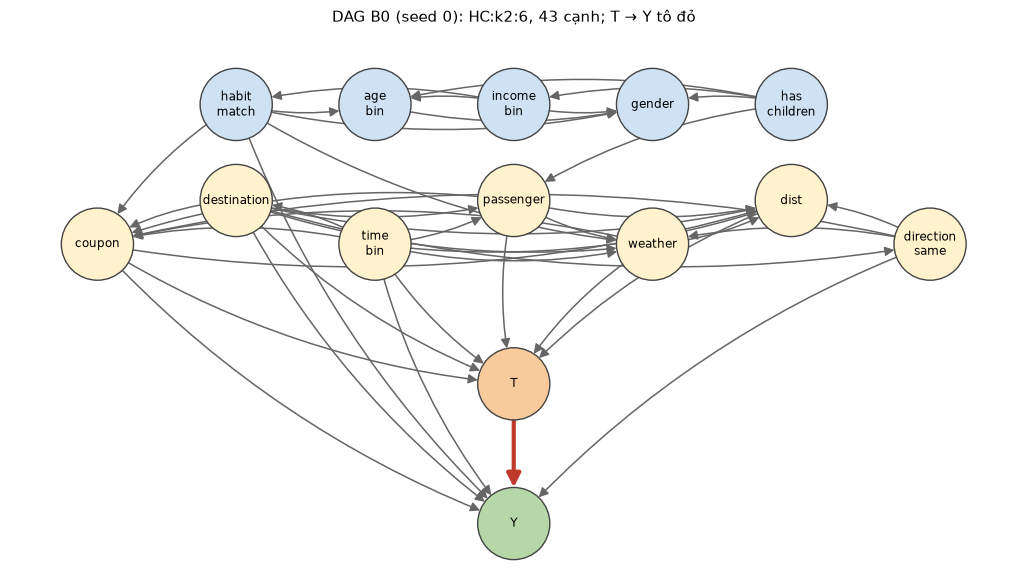

In [20]:
def run_b0(train: pd.DataFrame, val: pd.DataFrame) -> dict:
    """Pipeline B0 cho một seed: chọn cấu trúc trên VALIDATION, fit CPD BDeu trên TRAIN.

    Trả về: dict gồm edges, bn, table (CPD của Y), bảng ứng viên, tên ứng viên thắng, thời gian fit.
    """
    t0 = time.time()
    cand, edges_of = learn_b0_candidates(train, val)
    best = cand.iloc[0]["ứng viên"]
    edges = edges_of[best]
    bn = fit_discrete_bn(edges, train, CONFIG["cpd"]["estimator"], CONFIG["cpd"]["equivalent_sample_size"])
    return {"edges": edges, "bn": bn, "table": y_table(bn), "candidates": cand, "chosen": best,
            "fit_time": time.time() - t0, "check": check_dag(edges)}


B0_0 = run_b0(train0, val0)
print("B0 seed 0:", B0_0["chosen"], "|", len(B0_0["edges"]), "cạnh | kiểm tra DAG:", {k: v for k, v in B0_0["check"].items() if k not in ("vi phạm", "thiếu")})
print("parents(Y) =", sorted(B0_0["bn"].get_parents("Y")), "| parents(T) =", sorted(B0_0["bn"].get_parents("T")))
draw_dag(B0_0["edges"], f"DAG B0 (seed 0): {B0_0['chosen']}, {len(B0_0['edges'])} cạnh; T → Y tô đỏ")
plt.savefig(ART / "dag_b0_seed0.png", dpi=130, bbox_inches="tight")
plt.show()

In [21]:
cpdT = cpd_to_frame(B0_0["bn"].get_cpds("T"))
cpdT = cpdT[cpdT["T"] == "1"].drop(columns="T").rename(columns={"p": "P(T=1|parents)"})
parT = [c for c in cpdT.columns if c != "P(T=1|parents)"]
cpdT = cpdT.merge(train0.groupby(parT).size().rename("n TRAIN").reset_index(), on=parT, how="left").fillna({"n TRAIN": 0})
print(f"CPD của T (BDeu, ESS = 5): parents(T) = {parT} đều thuộc tầng kịch bản; {len(cpdT)} tổ hợp, {int((cpdT['n TRAIN'] == 0).sum())} tổ hợp trống (BDeu cho 0,5).")
cpdT.sort_values("n TRAIN", ascending=False).head(8).round(3)

CPD của T (BDeu, ESS = 5): parents(T) = ['coupon', 'destination', 'dist', 'passenger', 'time_bin', 'weather'] đều thuộc tầng kịch bản; 1620 tổ hợp, 1487 tổ hợp trống (BDeu cho 0,5).


,coupon,destination,dist,passenger,time_bin,weather,P(T=1|parents),n TRAIN
872,Coffee House,Work,15-25,Alone,morning,Sunny,0.680,303.0
725,Coffee House,Home,<15,Alone,evening,Sunny,0.439,303.0
767,Coffee House,No Urgent Place,15-25,Friend(s),afternoon,Sunny,0.500,244.0
1373,Restaurant(<20),Home,<15,Alone,evening,Sunny,0.725,233.0
401,Carry out & Take away,Home,<15,Alone,evening,Sunny,0.000,224.0
977,Restaurant(20-50),Home,15-25,Alone,evening,Sunny,0.167,221.0
620,Carry out & Take away,Work,<15,Alone,morning,Sunny,0.589,207.0
1418,Restaurant(<20),No Urgent Place,15-25,Friend(s),evening,Sunny,0.589,207.0


In [22]:
tabY = B0_0["table"]
print(f"Bảng P(Y=1 | parents) của B0 có {len(tabY)} tổ hợp. 10 tổ hợp có xác suất chấp nhận cao nhất và thấp nhất:")
pd.concat([tabY.sort_values("p1", ascending=False).head(10), tabY.sort_values("p1").head(10)]).round(3)

Bảng P(Y=1 | parents) của B0 có 540 tổ hợp. 10 tổ hợp có xác suất chấp nhận cao nhất và thấp nhất:


,T,coupon,destination,direction_same,habit_match,time_bin,p1
75,0,Carry out & Take away,No Urgent Place,0,low,afternoon,1.000
18,0,Bar,No Urgent Place,0,high,afternoon,0.999
345,1,Carry out & Take away,No Urgent Place,0,low,afternoon,0.999
182,0,Restaurant(20-50),No Urgent Place,0,high,morning,0.998
181,0,Restaurant(20-50),No Urgent Place,0,high,evening,0.995
271,1,Bar,Home,0,high,evening,0.995
442,1,Restaurant(20-50),Home,1,high,evening,0.995
234,0,Restaurant(<20),No Urgent Place,0,high,afternoon,0.915
72,0,Carry out & Take away,No Urgent Place,0,high,afternoon,0.915
16,0,Bar,Home,1,mid,evening,0.912


**Đọc kết quả.** 540 tổ hợp parents nhưng chỉ 189 có trong TRAIN (mục 9), nên nhiều xác suất cực trị (≈ 1,00 hay 0,005) là ô chỉ có vài dòng: với ESS = 5 chia cho 1 080 ô con, pseudo-count mỗi ô chỉ ≈ 0,005 nên BDeu gần như không làm trơn ô có dữ liệu, chỉ kéo ô *trống* về 0,5. Vì vậy mức ESS hầu như không đổi kết quả (A4, mục 16.3) và khác biệt giữa CPD rời rạc với MLP tập trung ở ô thưa (mục 9, 13.2).

### 8.3 Identify bằng DoWhy trên DAG B0

DoWhy nhận DAG (DOT), T và Y, trả về estimand. Với `identify_effect` mặc định, DoWhy liệt kê các tập điều chỉnh thoả **tiêu chí backdoor** (Pearl): tập $Z$ không chứa hậu duệ của T và chặn mọi đường backdoor T ← … → Y, tức là T ⫫ Y | Z trong đồ thị đã **cắt các cạnh ra khỏi T**; `get_backdoor_variables()` trả về tập **nhỏ nhất** trong số đó. Tập này không nhất thiết là parents(T) và không nhất thiết nằm trong tầng kịch bản: biến tầng người trả lời cũng hợp lệ miễn là nó đo trước T (ví dụ `habit_match`, vừa là cha của `coupon` vừa là cha của Y). Hàm `check_backdoor` dưới đây kiểm tra lại tiêu chí bằng `networkx` cho tập DoWhy chọn và cho $C_\text{full}$.

In [23]:
def to_dowhy_frame(data: pd.DataFrame, categories: dict | None = None) -> pd.DataFrame:
    """Chuyển dữ liệu chuỗi sang dạng DoWhy dùng được: T, Y số nguyên; biến khác kiểu category với cùng thứ tự mức."""
    out = data[NODES].copy()
    out["T"] = out["T"].astype(int)
    out["Y"] = out["Y"].astype(int)
    for c in NODES:
        if c not in ("T", "Y"):
            out[c] = pd.Categorical(out[c], categories=STATES[c])
    return out


def dowhy_identify(edges: list[tuple[str, str]], train: pd.DataFrame) -> tuple[CausalModel, object]:
    """Tạo CausalModel của DoWhy từ DAG và TRAIN; trả về (model, estimand đã identify)."""
    dot = "digraph { " + "; ".join(f'"{u}" -> "{v}"' for u, v in edges) + "; }"
    model = CausalModel(data=to_dowhy_frame(train), treatment="T", outcome="Y", graph=dot)
    estimand = model.identify_effect(proceed_when_unidentifiable=False)
    return model, estimand


def check_backdoor(edges: list[tuple[str, str]], Z: list[str]) -> dict:
    """Kiểm tra tiêu chí backdoor của tập Z cho T → Y trên DAG edges bằng d-separation của networkx.

    Tham số: edges — cạnh DAG; Z — tập điều chỉnh cần kiểm tra.
    Trả về: dict gồm số biến, Z có chứa hậu duệ của T không, Z có chặn mọi đường backdoor không (d-separation trong đồ thị
            đã cắt cạnh ra khỏi T), Z có tối thiểu không (bỏ bớt một biến là hỏng), và kết luận "hợp lệ".
    """
    G = nx.DiGraph(edges)
    G.add_nodes_from(NODES)
    Z = set(Z)
    has_desc = bool(Z & nx.descendants(G, "T"))
    G_cut = G.copy()
    G_cut.remove_edges_from([(u, v) for u, v in G.edges if u == "T"])   # cắt mọi cạnh ra khỏi T → chỉ còn đường backdoor
    blocks = bool(nx.is_d_separator(G_cut, {"T"}, {"Y"}, Z))
    minimal = blocks and bool(nx.is_minimal_d_separator(G_cut, {"T"}, {"Y"}, Z))
    return {"|Z|": len(Z), "chứa hậu duệ của T": has_desc, "chặn mọi đường backdoor": blocks, "tối thiểu": minimal,
            "hợp lệ": (not has_desc) and blocks}


MODEL0, ESTIMAND0 = dowhy_identify(B0_0["edges"], train0)
print(ESTIMAND0)
BD0 = ESTIMAND0.get_backdoor_variables()
print("Tập backdoor DoWhy chọn:", BD0, "| tầng:", {v: list(CONFIG["tiers"])[TIER_OF[v]] for v in BD0})
(ART / "identification_b0_seed0.txt").write_text(str(ESTIMAND0))
BD_CHECK = pd.DataFrame({"tập DoWhy chọn": check_backdoor(B0_0["edges"], BD0),
                         "parents(T)": check_backdoor(B0_0["edges"], list(B0_0["bn"].get_parents("T"))),
                         "C_full (12 biến nền)": check_backdoor(B0_0["edges"], C_FULL),
                         "tập rỗng": check_backdoor(B0_0["edges"], [])}).T
assert BD_CHECK.loc["tập DoWhy chọn", "hợp lệ"] and BD_CHECK.loc["C_full (12 biến nền)", "hợp lệ"]
BD_CHECK

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                                                               
────(E[Y|direction_same,time_bin,destination,coupon,habit_match])
d[T]                                                             
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,direction_same,time_bin,destination,coupon,habit_match,U) = P(Y|T,direction_same,time_bin,destination,coupon,habit_match)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
 d                                                           
────(E[Y|dist,time_bin,destination,passenger,weather,coupon])
d[T]                                                         
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,dist,time_bin,destination,passenger,weath

,|Z|,chứa hậu duệ của T,chặn mọi đường backdoor,tối thiểu,hợp lệ
tập DoWhy chọn,5,False,True,True,True
parents(T),6,False,True,True,True
C_full (12 biến nền),12,False,True,False,True
tập rỗng,0,False,False,False,False


Bảng trên xác nhận bằng đồ thị: tập DoWhy chọn và parents(T) đều hợp lệ; tập rỗng không hợp lệ (có đường backdoor qua `coupon`, đúng với phân tích confounder ở mục 5.4); và **toàn bộ** $C_\text{full}$ (hồ sơ TEST) cũng hợp lệ vì mọi biến nền đều đo trước T (không chứa hậu duệ của T) và là siêu tập của một tập backdoor. Vì vậy công thức mục 7.3 dùng $C_\text{full}$ cho B0/H1/H2 chung một cohort tham chiếu và cho cả CATE; mục 13 lặp lại kiểm tra này cho mọi seed và cả DAG H2 (assert trong `dowhy_reference_estimate`).

### 8.4 Do-query B0 trên cohort TEST seed 0

In [24]:
def show_profiles(q: pd.DataFrame, k: int = 6) -> pd.DataFrame:
    """Hiển thị k hồ sơ TEST đầu tiên với q(0, C_i), q(1, C_i) (slide 77 bước 4)."""
    return q.head(k).assign(**{"q1-q0": lambda x: x["q1"] - x["q0"]}).round(3)


Q0 = do_query(B0_0["table"], test0)
S0 = standardize(B0_0["table"], test0)
print(f"Cohort TEST seed 0: n = {S0['n_ref']} dòng. risk(0) = {S0['risk0']:.4f}, risk(1) = {S0['risk1']:.4f}, ATE = {S0['ATE']:+.4f}")
print("CATE theo coupon:", {k: round(v, 3) for k, v in S0["CATE"].items()})
show_profiles(Q0)

Cohort TEST seed 0: n = 1824 dòng. risk(0) = 0.6519, risk(1) = 0.4892, ATE = -0.1627
CATE theo coupon: {'Bar': -0.052, 'Carry out & Take away': -0.123, 'Coffee House': -0.15, 'Restaurant(20-50)': -0.221, 'Restaurant(<20)': -0.246}


,habit_match,age_bin,income_bin,gender,has_children,coupon,destination,time_bin,passenger,weather,dist,direction_same,q0,q1,q1-q0
0,high,26-35,37.5-75k,Female,1,Restaurant(<20),No Urgent Place,afternoon,Alone,Sunny,<15,0,0.915,0.697,-0.218
1,low,26-35,37.5-75k,Female,1,Coffee House,No Urgent Place,morning,Friend(s),Sunny,<15,0,0.523,0.480,-0.043
2,high,26-35,37.5-75k,Female,1,Carry out & Take away,No Urgent Place,morning,Friend(s),Sunny,15-25,0,0.854,0.696,-0.158
3,low,26-35,37.5-75k,Female,1,Coffee House,No Urgent Place,afternoon,Friend(s),Sunny,15-25,0,0.399,0.344,-0.055
4,low,26-35,37.5-75k,Female,1,Coffee House,No Urgent Place,afternoon,Friend(s),Sunny,15-25,0,0.399,0.344,-0.055
5,high,26-35,37.5-75k,Female,1,Restaurant(<20),No Urgent Place,evening,Friend(s),Sunny,15-25,0,0.902,0.806,-0.097


### 8.5 Kiểm tra cài đặt: tra bảng CPD so với Variable Elimination trên toàn mạng

Hai kiểm tra trên vài dòng TEST: (a) $P(Y \mid \text{mọi biến khác})$ bằng VE phải trùng tra bảng (Y là nút lá); (b) $P(Y \mid do(T{=}t), C_i)$ tính bằng **mạng cắt cạnh vào T** (truncated factorization) phải trùng $q(t, C_i)$.

In [25]:
def mutilate(bn: DiscreteBayesianNetwork, node: str) -> DiscreteBayesianNetwork:
    """Mạng can thiệp do(node): cắt mọi cạnh vào node, thay CPD của node bằng phân phối đều, giữ các CPD khác."""
    edges = [(u, v) for u, v in bn.edges() if v != node]
    m = DiscreteBayesianNetwork(edges)
    m.add_nodes_from(NODES)
    k = len(STATES[node])
    cpds = [c for c in bn.get_cpds() if c.variable != node]
    cpds.append(TabularCPD(node, k, np.full((k, 1), 1.0 / k), state_names={node: STATES[node]}))
    m.add_cpds(*cpds)
    assert m.check_model()
    return m


def implementation_check(bn: DiscreteBayesianNetwork, table: pd.DataFrame, rows: pd.DataFrame) -> pd.DataFrame:
    """So sánh tra bảng với VE (dự đoán) và với mạng cắt cạnh (do-query) trên vài dòng."""
    inf_obs = VariableElimination(bn)
    inf_do = VariableElimination(mutilate(bn, "T"))
    others = [c for c in NODES if c != "Y"]
    out = []
    for _, r in rows.iterrows():
        ev = {c: r[c] for c in others}
        p_ve = inf_obs.query(["Y"], evidence=ev, show_progress=False).values[1]
        q_do = {t: inf_do.query(["Y"], evidence={**{c: r[c] for c in C_FULL}, "T": t}, show_progress=False).values[1] for t in ("0", "1")}
        tmp = pd.DataFrame([r[C_FULL + ["T"]]])
        out.append({"p_VE(Y=1|mọi biến)": p_ve, "p_tra_bảng": predict_y(table, tmp)[0],
                    "do0_VE": q_do["0"], "do1_VE": q_do["1"]})
    chk = pd.DataFrame(out)
    q = do_query(table, rows)
    chk["q0_tra_bảng"] = q["q0"].values
    chk["q1_tra_bảng"] = q["q1"].values
    assert np.allclose(chk["p_VE(Y=1|mọi biến)"], chk["p_tra_bảng"], atol=1e-9)
    assert np.allclose(chk["do0_VE"], chk["q0_tra_bảng"], atol=1e-9) and np.allclose(chk["do1_VE"], chk["q1_tra_bảng"], atol=1e-9)
    return chk


print("Sai lệch tối đa giữa hai cách tính bằng 0 (assert đã qua):")
implementation_check(B0_0["bn"], B0_0["table"], test0.head(5)).round(6)

Sai lệch tối đa giữa hai cách tính bằng 0 (assert đã qua):


,p_VE(Y=1|mọi biến),p_tra_bảng,do0_VE,do1_VE,q0_tra_bảng,q1_tra_bảng
0,0.915222,0.915222,0.915222,0.696942,0.915222,0.696942
1,0.480393,0.480393,0.523436,0.480393,0.523436,0.480393
2,0.695985,0.695985,0.853579,0.695985,0.853579,0.695985
3,0.343761,0.343761,0.398655,0.343761,0.398655,0.343761
4,0.398655,0.398655,0.398655,0.343761,0.398655,0.343761


<a id="9"></a>
## 9. H1: thay CPD của Y bằng mạng nơ-ron

H1 **giữ nguyên DAG B0** của cùng seed và chỉ thay $P(Y \mid \text{parents}(Y))$ bằng một MLP:

- Input: one-hot của parents(Y) (khoảng 20 chiều); 2 lớp ẩn 32–16, ReLU, dropout 0,2; output 1 logit.
- Loss BCE, Adam (lr 0,001), batch 256, tối đa 200 epoch, **early stopping theo loss VALIDATION** (patience 10).
- Sau khi huấn luyện, **liệt kê mọi tổ hợp parents** → tính $P(Y{=}1 \mid \cdot)$ → tạo `TabularCPD` → chèn vào bản sao của B0 → `check_model()`. Mọi phép dự đoán và do-query sau đó chạy y hệt B0.

Lý do kỳ vọng H1 khác B0: với 500–1000 ô tổ hợp parents, BDeu ước lượng từng ô độc lập (co về prior ở ô thưa) còn MLP chia sẻ thống kê giữa các ô.

H1 seed 0: parents(Y) = ['T', 'coupon', 'destination', 'direction_same', 'habit_match', 'time_bin'] | input 18 chiều | 1153 tham số | 51 epoch | 10.2s | bảng CPD 540 tổ hợp


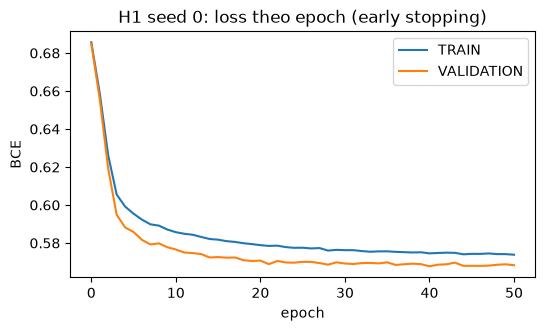

In [26]:
def onehot(data: pd.DataFrame, cols: list[str]) -> np.ndarray:
    """Mã hoá one-hot các cột cols theo thứ tự trạng thái cố định trong STATES (float32)."""
    blocks = [np.stack([(data[c].values == s).astype(np.float32) for s in STATES[c]], axis=1) for c in cols]
    return np.concatenate(blocks, axis=1)


def build_mlp(d_in: int, hidden: list[int], dropout: float) -> torch.nn.Sequential:
    """Tạo MLP d_in → hidden... → 1 logit bằng nn.Sequential (không định nghĩa class mới)."""
    layers, k = [], d_in
    for h in hidden:
        layers += [torch.nn.Linear(k, h), torch.nn.ReLU(), torch.nn.Dropout(dropout)]
        k = h
    layers.append(torch.nn.Linear(k, 1))
    return torch.nn.Sequential(*layers)


def train_mlp(X_tr: np.ndarray, y_tr: np.ndarray, X_va: np.ndarray, y_va: np.ndarray, cfg: dict, seed: int) -> tuple[torch.nn.Sequential, pd.DataFrame]:
    """Huấn luyện MLP nhị phân với early stopping trên VALIDATION.

    Tham số: X_tr, y_tr — TRAIN; X_va, y_va — VALIDATION; cfg — CONFIG["h1"] (hoặc bản sửa cho ablation); seed — seed torch.
             Tuỳ chọn trong cfg (mục 16.7): "mono_lambda" > 0 và "t_cols" = (cột one-hot T=0, cột one-hot T=1) thêm phạt đơn điệu
             λ · mean(ReLU(P(Y=1 | T=1, c) − P(Y=1 | T=0, c))) trên các dòng của batch.
    Trả về: (mạng ở epoch tốt nhất theo loss VALIDATION, bảng lịch sử loss theo epoch).
    """
    torch.manual_seed(seed)
    net = build_mlp(X_tr.shape[1], cfg["hidden"], cfg["dropout"])
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = torch.nn.BCEWithLogitsLoss()
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr, dtype=torch.float32)
    Xv, yv = torch.tensor(X_va), torch.tensor(y_va, dtype=torch.float32)
    lam, t_cols = cfg.get("mono_lambda", 0.0), cfg.get("t_cols")
    best, best_state, bad, hist = np.inf, None, 0, []
    for ep in range(cfg["max_epochs"]):
        net.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            opt.zero_grad()
            loss = loss_fn(net(Xt[idx]).squeeze(1), yt[idx])
            if lam > 0:
                X1, X0 = Xt[idx].clone(), Xt[idx].clone()
                X1[:, t_cols[0]], X1[:, t_cols[1]] = 0.0, 1.0            # cùng dòng, đặt T = 1
                X0[:, t_cols[0]], X0[:, t_cols[1]] = 1.0, 0.0            # cùng dòng, đặt T = 0
                net.eval()                                               # tắt dropout khi tính hiệu, nếu không hai mask dropout khác nhau tạo phạt giả
                loss = loss + lam * torch.relu(torch.sigmoid(net(X1)) - torch.sigmoid(net(X0))).mean()
                net.train()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            l_tr = loss_fn(net(Xt).squeeze(1), yt).item()
            l_va = loss_fn(net(Xv).squeeze(1), yv).item()
        hist.append({"epoch": ep, "train loss": l_tr, "val loss": l_va})
        if l_va < best - 1e-5:
            best, bad, best_state = l_va, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    return net, pd.DataFrame(hist)


def mlp_cpd(net: torch.nn.Sequential, parents: list[str]) -> tuple[TabularCPD, pd.DataFrame]:
    """Liệt kê mọi tổ hợp parents, tính P(Y=1 | ·) từ MLP và đóng gói thành TabularCPD hợp lệ của pgmpy.

    Trả về: (TabularCPD của Y, bảng parents + p1 cùng định dạng với y_table()).
    """
    configs = pd.DataFrame(list(itertools.product(*[STATES[p] for p in parents])), columns=parents)
    with torch.no_grad():
        p1 = torch.sigmoid(net(torch.tensor(onehot(configs, parents))).squeeze(1)).numpy().astype(float)
    p1 = np.clip(p1, 1e-6, 1 - 1e-6)
    cpd = TabularCPD("Y", 2, np.vstack([1 - p1, p1]), evidence=parents, evidence_card=[len(STATES[p]) for p in parents],
                     state_names={"Y": STATES["Y"], **{p: STATES[p] for p in parents}})
    return cpd, configs.assign(p1=p1)


def run_h1(bn_b0: DiscreteBayesianNetwork, train: pd.DataFrame, val: pd.DataFrame, seed: int, cfg: dict | None = None) -> dict:
    """Pipeline H1 cho một seed: huấn luyện MLP cho P(Y | parents(Y) của B0), chèn vào bản sao B0.

    Trả về: dict gồm bn (bản sao B0 với CPD mới), table, net, lịch sử loss, số tham số, thời gian fit, refit (hàm cho bootstrap).
    """
    cfg = cfg or CONFIG["h1"]
    parents = sorted(bn_b0.get_parents("Y"))
    if cfg.get("mono_lambda", 0.0) > 0:                                  # vị trí hai cột one-hot của T trong đầu vào (mục 16.7)
        off = sum(len(STATES[q]) for q in parents[:parents.index("T")])
        cfg = {**cfg, "t_cols": (off, off + 1)}
    t0 = time.time()
    net, hist = train_mlp(onehot(train, parents), (train["Y"] == "1").astype(int).values,
                          onehot(val, parents), (val["Y"] == "1").astype(int).values, cfg, seed)
    cpd, table = mlp_cpd(net, parents)
    bn = bn_b0.copy()
    bn.remove_cpds("Y")
    bn.add_cpds(cpd)
    assert bn.check_model()
    n_params = sum(p.numel() for p in net.parameters())
    refit_spec = {"kind": "mlp", "parents": parents, "val": val, "cfg": cfg, "seed": seed}   # dùng cho bootstrap (mục 11)
    return {"bn": bn, "table": table, "net": net, "hist": hist, "parents": parents, "n_params": n_params,
            "fit_time": time.time() - t0, "epochs": len(hist), "refit": refit_spec}


H1_0 = run_h1(B0_0["bn"], train0, val0, seed=0)
print(f"H1 seed 0: parents(Y) = {H1_0['parents']} | input {onehot(train0.head(1), H1_0['parents']).shape[1]} chiều | "
      f"{H1_0['n_params']} tham số | {H1_0['epochs']} epoch | {H1_0['fit_time']:.1f}s | bảng CPD {len(H1_0['table'])} tổ hợp")
torch.save(H1_0["net"].state_dict(), ART / "h1_seed0.pt")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(H1_0["hist"]["epoch"], H1_0["hist"]["train loss"], label="TRAIN")
ax.plot(H1_0["hist"]["epoch"], H1_0["hist"]["val loss"], label="VALIDATION")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE"); ax.set_title("H1 seed 0: loss theo epoch (early stopping)"); ax.legend()
plt.show()

In [27]:
cmp = B0_0["table"].merge(H1_0["table"], on=H1_0["parents"], suffixes=("_B0", "_H1"))
cmp["|khác biệt|"] = (cmp["p1_B0"] - cmp["p1_H1"]).abs()
cnt = train0.groupby(H1_0["parents"]).size().rename("n TRAIN").reset_index()
cmp = cmp.merge(cnt, on=H1_0["parents"], how="left").fillna({"n TRAIN": 0})
w_mean = np.average(cmp["|khác biệt|"], weights=cmp["n TRAIN"])
print(f"So sánh CPD của Y: B0 (BDeu) và H1 (MLP) trên {len(cmp)} tổ hợp parents; {int((cmp['n TRAIN'] == 0).sum())} tổ hợp không có trong TRAIN.")
print(f"Khác biệt tuyệt đối trung bình: {cmp['|khác biệt|'].mean():.3f} (đều theo ô), {w_mean:.3f} (trọng số theo số dòng TRAIN) → khác biệt tập trung ở ô thưa, nơi BDeu co về 0,5 còn MLP nội suy từ ô lân cận.")
cmp.sort_values("n TRAIN", ascending=False).head(8).round(3)

So sánh CPD của Y: B0 (BDeu) và H1 (MLP) trên 540 tổ hợp parents; 351 tổ hợp không có trong TRAIN.
Khác biệt tuyệt đối trung bình: 0.162 (đều theo ô), 0.048 (trọng số theo số dòng TRAIN) → khác biệt tập trung ở ô thưa, nơi BDeu co về 0,5 còn MLP nội suy từ ô lân cận.


,T,coupon,destination,direction_same,habit_match,time_bin,p1_B0,p1_H1,|khác biệt|,n TRAIN
401,1,Coffee House,No Urgent Place,0,low,morning,0.480,0.453,0.027,204.0
23,0,Bar,No Urgent Place,0,low,morning,0.278,0.286,0.008,176.0
129,0,Coffee House,No Urgent Place,0,low,afternoon,0.399,0.400,0.001,148.0
240,0,Restaurant(<20),No Urgent Place,0,mid,afternoon,0.909,0.889,0.020,143.0
166,0,Restaurant(20-50),Home,0,low,evening,0.364,0.357,0.008,140.0
382,1,Coffee House,Home,0,low,evening,0.115,0.182,0.067,139.0
511,1,Restaurant(<20),No Urgent Place,0,mid,evening,0.806,0.766,0.040,134.0
131,0,Coffee House,No Urgent Place,0,low,morning,0.523,0.543,0.019,128.0


**Đọc kết quả.** Ở các ô dày (> 130 dòng TRAIN) hai cơ chế gần như trùng nhau (|Δ| 0,001–0,07), còn 351/540 tổ hợp không có trong TRAIN thì BDeu trả 0,5 và MLP nội suy từ ô lân cận; khác biệt trung bình theo ô 0,16 nhưng theo trọng số số dòng chỉ 0,05. Đây là nguồn gốc của việc H1 gần như không có ô τ > 0 (tỉ lệ theo mô hình ở bảng mục 16.6) trong khi ATE không đổi so với B0 (mục 13).

<a id="10"></a>
## 10. H2: học DAG bằng NOTEARS-MLP có mask ràng buộc

**Ý tưởng NOTEARS** (Zheng et al. 2018, 2020): thay tìm kiếm tổ hợp bằng tối ưu liên tục. Mỗi nút $j$ có một MLP nhỏ nhận one-hot của *mọi* nút khác; ma trận kề $A_{ij} = \lVert W^{(1)}_{j}[:, \text{khối } i]\rVert_2$ (chuẩn của các trọng số lớp đầu nối từ nút $i$). Ràng buộc acyclic viết thành hàm trơn $h(A) = \mathrm{tr}\,e^{A \circ A} - d = 0$ và giải bằng augmented Lagrangian.

**Thích nghi cho biến phân loại:** input one-hot, output softmax theo số mức của nút, loss = tổng cross-entropy của 14 nút (mỗi MLP có 1 lớp ẩn 10 đơn vị). Hàm mục tiêu đúng như `notears_objective` dưới đây:
$$\min_W\ \sum_{j=1}^{14} \mathrm{CE}_j(W) + \lambda_1 \lVert s \odot W^{(1)}\rVert_1 + \tfrac{\lambda_2}{2}\lVert W\rVert_2^2 + \tfrac{\rho}{2} h(A)^2 + \alpha\, h(A),$$
với $\lambda_1 = \lambda_2 = 0{,}01$, $s$ là hệ số nhân phạt theo nút đích (bằng 1 trừ các cạnh vào T, xem dưới), $(\rho, \alpha)$ là tham số augmented Lagrangian tăng dần qua tối đa 20 vòng ngoài cho tới khi $h(A) < 10^{-8}$; mỗi vòng ngoài giải bằng L-BFGS.

**Ràng buộc miền:** mask $M$ (mục 6) nhân vào trọng số lớp đầu, $W_\text{eff} = M \odot W$, nên trọng số của cạnh cấm luôn bằng 0 cả khi học lẫn khi tính $h(A)$. Quy ước: $M[i, j]$ ứng với cạnh $i \to j$; đường chéo bằng 0.

**Hệ số phạt riêng cho cạnh vào T:** vì T độc lập với biến người trả lời và chỉ phụ thuộc yếu vào biến kịch bản (mục 5.4), cải thiện cross-entropy của T khi thêm cạnh kịch bản → T rất nhỏ và phạt L1 đồng đều dễ xoá hết cơ chế của T. Vì vậy NOTEARS được chạy một lần cho mỗi hệ số nhân phạt L1 của các cạnh vào T trong lưới $\{1;\,0{,}3;\,0{,}1\}$ (`l1_scale_T_grid`), và hệ số được chọn trên VALIDATION cùng với ngưỡng.

**Sau khi học:** cặp (hệ số, ngưỡng) chọn trên VALIDATION (fit CPD BDeu cho từng cặp, chấm log-loss của Y; hoà thì chấm riêng cơ chế của T bằng log-loss của T, hoà nữa thì lấy log-likelihood toàn mạng cao hơn), sửa chu trình bằng quy tắc "bỏ cạnh yếu nhất trong mỗi chu trình", bổ sung T → Y nếu thiếu (ghi nhận), kiểm tra `check_dag()`, rồi re-identify bằng DoWhy và fit CPD BDeu như B0.

In [28]:
def notears_adjacency(W1: torch.Tensor, M_full: torch.Tensor, B_sel: torch.Tensor, Mt: torch.Tensor) -> torch.Tensor:
    """Ma trận kề có trọng số từ lớp đầu của MLP: A[i, j] = sqrt(Σ_m Σ_{cột ∈ khối i} (M ⊙ W1)[j, m, cột]^2).

    Tham số: W1 — trọng số lớp đầu (d, m1, D); M_full — mask dạng (d, D); B_sel — ma trận gom cột one-hot về nút (D, d); Mt — mask d × d.
    Trả về: tensor d × d.
    """
    S = ((W1 * M_full[:, None, :]) ** 2).sum(1)              # (d, D)
    return torch.sqrt((S @ B_sel).T + 1e-12) * Mt


def notears_fit_loss(net: dict, Xt: torch.Tensor, It: torch.Tensor) -> torch.Tensor:
    """Tổng cross-entropy softmax của d nút (trung bình theo dòng, cộng theo nút).

    Tham số: net — dict các tensor W1, b1, W2, b2, M_full, cls_mask, Kmax, dn; Xt — one-hot (n × D); It — chỉ số trạng thái (n × d).
    """
    H = torch.relu(torch.einsum("jmD,nD->njm", net["W1"] * net["M_full"][:, None, :], Xt) + net["b1"])
    logits = torch.einsum("jkm,njm->njk", net["W2"], H) + net["b2"] + net["cls_mask"]
    return torch.nn.functional.cross_entropy(logits.reshape(-1, net["Kmax"]), It.reshape(-1), reduction="mean") * net["dn"]


def notears_h(A: torch.Tensor, dn: int) -> torch.Tensor:
    """Ràng buộc phi chu trình h(A) = tr exp(A ∘ A) − d (bằng 0 khi và chỉ khi A là DAG)."""
    return torch.trace(torch.matrix_exp(A * A)) - dn


def notears_objective(opt: torch.optim.Optimizer, net: dict, Xt: torch.Tensor, It: torch.Tensor, rho: float, alpha: float, cfg: dict) -> torch.Tensor:
    """Hàm mục tiêu Lagrange tăng cường cho một bước LBFGS (được gọi lại qua functools.partial, không lồng hàm).

    Tham số: opt — optimizer; net — dict tensor (L1w: hệ số nhân phạt L1 theo nút đích, mặc định 1); Xt, It — dữ liệu; rho, alpha — tham số phạt; cfg — CONFIG["h2"].
    Trả về: giá trị mục tiêu (đã gọi backward).
    """
    opt.zero_grad()
    A = notears_adjacency(net["W1"], net["M_full"], net["B_sel"], net["Mt"])
    hv = notears_h(A, net["dn"])
    obj = (notears_fit_loss(net, Xt, It) + 0.5 * rho * hv * hv + alpha * hv
           + cfg["lambda1"] * (net["L1w"][:, None, None] * net["W1"] * net["M_full"][:, None, :]).abs().sum()
           + 0.5 * cfg["lambda2"] * ((net["W1"] ** 2).sum() + (net["W2"] ** 2).sum()))
    obj.backward()
    return obj


def notears_mlp_categorical(X: np.ndarray, idx: np.ndarray, sizes: list[int], M: np.ndarray, cfg: dict, seed: int, verbose: bool = False,
                            l1_scale_T: float = 1.0) -> tuple[np.ndarray, dict]:
    """NOTEARS-MLP cho biến phân loại với mask cạnh cấm (cài đặt bằng tensor thuần, không dùng class).

    Tham số: X — one-hot (n × D); idx — chỉ số trạng thái (n × d); sizes — số mức mỗi nút; M — mask d × d;
             cfg — CONFIG["h2"]; seed — seed torch; l1_scale_T — hệ số nhân phạt L1 cho các cạnh đi vào T (1 = như mọi nút; <1 = phạt nhẹ hơn; run_h2 chọn trên VALIDATION).
    Trả về: (ma trận kề A d × d với A[i, j] = cường độ cạnh i → j, dict thông tin hội tụ).
    """
    torch.manual_seed(seed)
    dn, D, Kmax, m1 = len(sizes), X.shape[1], max(sizes), cfg["hidden"]
    block = np.repeat(np.arange(dn), sizes)                       # cột one-hot nào thuộc nút nào
    Mt = torch.tensor(M)
    M_full = Mt[block, :].T.contiguous()                          # (d, D): M_full[j, cột] = M[nút(cột), j]
    B_sel = torch.tensor(np.eye(dn, dtype=np.float32)[block])     # (D, d): gom cột về nút
    Xt, It = torch.tensor(X), torch.tensor(idx)
    cls_mask = torch.full((dn, Kmax), -1e9)
    for j, k in enumerate(sizes):
        cls_mask[j, :k] = 0.0
    W1 = torch.nn.Parameter(torch.randn(dn, m1, D) * 0.1)
    b1 = torch.nn.Parameter(torch.zeros(dn, m1))
    W2 = torch.nn.Parameter(torch.randn(dn, Kmax, m1) * 0.1)
    b2 = torch.nn.Parameter(torch.zeros(dn, Kmax))
    params = [W1, b1, W2, b2]
    L1w = torch.ones(dn)
    L1w[NODES.index("T")] = l1_scale_T
    net = {"W1": W1, "b1": b1, "W2": W2, "b2": b2, "M_full": M_full, "B_sel": B_sel, "Mt": Mt, "cls_mask": cls_mask, "Kmax": Kmax, "dn": dn, "L1w": L1w}

    rho, alpha, h, ce, log = 1.0, 0.0, np.inf, np.nan, []
    for it in range(cfg["max_iter"]):
        while rho < cfg["rho_max"]:
            opt = torch.optim.LBFGS(params, lr=1.0, max_iter=cfg["inner_steps"], line_search_fn="strong_wolfe")
            # LBFGS cần một hàm không tham số: cố định các đối số bằng functools.partial thay vì lồng hàm
            opt.step(functools.partial(notears_objective, opt, net, Xt, It, rho, alpha, cfg))
            with torch.no_grad():
                h_new = notears_h(notears_adjacency(W1, M_full, B_sel, Mt), dn).item()
                ce = notears_fit_loss(net, Xt, It).item()
            if h_new > 0.25 * h:
                rho *= 10
            else:
                break
        h = h_new
        alpha += rho * h
        log.append({"iter": it, "h": h, "rho": rho, "ce": ce})
        if verbose:
            print(f"  iter {it}: h = {h:.2e}, rho = {rho:.0e}, CE = {ce:.4f}")
        if h <= cfg["h_tol"] or rho >= cfg["rho_max"]:
            break
    with torch.no_grad():
        A = notears_adjacency(W1, M_full, B_sel, Mt).numpy()
    assert np.all(A[M == 0] == 0), "trọng số cạnh cấm phải bằng 0"
    return A, {"ce": ce, "h": h, "rho": rho, "iters": len(log), "log": log}


def threshold_dag(A: np.ndarray, thr: float) -> tuple[list[tuple[str, str]], list, list]:
    """Lấy cạnh có A[i, j] > thr, sửa chu trình (bỏ cạnh yếu nhất), thêm cạnh bắt buộc nếu thiếu.

    Trả về: (danh sách cạnh, cạnh đã bỏ vì chu trình, cạnh bắt buộc đã thêm).
    """
    G = nx.DiGraph()
    G.add_nodes_from(NODES)
    for i, u in enumerate(NODES):
        for j, v in enumerate(NODES):
            if A[i, j] > thr:
                G.add_edge(u, v, w=float(A[i, j]))
    removed = []
    while not nx.is_directed_acyclic_graph(G):
        cyc = nx.find_cycle(G)
        e = min(cyc, key=lambda e: G.edges[e]["w"])
        G.remove_edge(*e)
        removed.append(e)
    added = [e for e in REQUIRED_EDGES if not G.has_edge(*e)]
    G.add_edges_from(added)
    return sorted(G.edges()), removed, added


def h2_threshold_table(A: np.ndarray, train: pd.DataFrame, val: pd.DataFrame, scale: float) -> tuple[list[dict], dict]:
    """Với một ma trận kề A, thử mọi ngưỡng trong CONFIG: lấy DAG, fit CPD BDeu, chấm log-loss của Y, log-loss của T và LL toàn mạng trên VALIDATION.

    Tham số: A — ma trận kề NOTEARS; train, val — dữ liệu; scale — hệ số phạt L1 vào T đã dùng để học A (ghi vào bảng).
    Trả về: (danh sách dòng của bảng ngưỡng, dict ngưỡng → (edges, cạnh bỏ vì chu trình, cạnh bắt buộc đã thêm)).
    """
    yv = (val["Y"] == "1").astype(int).values
    rows, edges_of = [], {}
    for thr in CONFIG["h2"]["thresholds"]:
        edges, removed, added = threshold_dag(A, thr)
        chk = check_dag(edges)
        bn = fit_discrete_bn(edges, train, CONFIG["cpd"]["estimator"], CONFIG["cpd"]["equivalent_sample_size"])
        pv = predict_y(y_table(bn), val)
        rows.append({"λ₁(T)×": scale, "ngưỡng": thr, "số cạnh": len(edges), "chu trình bỏ": len(removed), "T→Y thêm": len(added), "hợp lệ": chk["hợp lệ"],
                     "parents(T)": ", ".join(sorted(bn.get_parents("T"))), "parents(Y)": ", ".join(sorted(bn.get_parents("Y"))),
                     "val log-loss Y": log_loss(yv, pv), "val log-loss T": node_log_loss(bn, val, "T"), "val LL/dòng": log_likelihood(bn, val)})
        edges_of[thr] = (edges, removed, added)
    return rows, edges_of


def run_h2(train: pd.DataFrame, val: pd.DataFrame, seed: int, mask: np.ndarray | None = None, verbose: bool = False,
           l1_scale_T: float | None = None) -> dict:
    """Pipeline H2 cho một seed: NOTEARS-MLP có mask (một lần cho mỗi hệ số phạt vào T) → chọn (hệ số, ngưỡng) trên VALIDATION → CPD BDeu.

    Tham số: train, val — dữ liệu; seed — seed torch; mask — mask cạnh cấm (mặc định MASK); verbose — in log NOTEARS của hệ số đầu tiên;
             l1_scale_T — None = thử cả lưới CONFIG["h2"]["l1_scale_T_grid"]; một số cụ thể = chỉ dùng hệ số đó.
    Trả về: dict gồm A (ma trận kề của hệ số chọn), bảng ngưỡng (mọi hệ số × ngưỡng, đã xếp theo tiêu chí), hệ số và ngưỡng chọn,
            edges, bn, table, thời gian, thông tin hội tụ, kiểm tra DAG, per_scale (A và thông tin hội tụ của từng hệ số).
    """
    mask = MASK if mask is None else mask
    grid = CONFIG["h2"]["l1_scale_T_grid"] if l1_scale_T is None else [l1_scale_T]
    sizes = [len(STATES[c]) for c in NODES]
    idx = np.stack([np.searchsorted(STATES[c], train[c].values) for c in NODES], axis=1)
    t0 = time.time()
    rows, per_scale, t_notears = [], {}, 0.0
    for scale in grid:
        t1 = time.time()
        A, info = notears_mlp_categorical(onehot(train, NODES), idx, sizes, mask, CONFIG["h2"], seed, verbose and scale == grid[0], scale)
        t_notears += time.time() - t1
        r, edges_of = h2_threshold_table(A, train, val, scale)
        rows += r
        per_scale[scale] = {"A": A, "info": info, "edges_of": edges_of}
    tab = pd.DataFrame(rows)
    tab["_ky"] = tab["val log-loss Y"].round(6)                  # tiêu chí chính: cơ chế của Y
    tab["_kt"] = tab["val log-loss T"].round(6)                  # hoà (đến 1e-6) → cơ chế của T; hoà nữa → LL toàn mạng
    tab = tab.sort_values(["_ky", "_kt", "val LL/dòng"], ascending=[True, True, False], kind="stable").drop(columns=["_ky", "_kt"]).reset_index(drop=True)
    scale, thr = float(tab.iloc[0]["λ₁(T)×"]), float(tab.iloc[0]["ngưỡng"])
    A, info = per_scale[scale]["A"], per_scale[scale]["info"]
    edges, removed, added = per_scale[scale]["edges_of"][thr]
    bn = fit_discrete_bn(edges, train, CONFIG["cpd"]["estimator"], CONFIG["cpd"]["equivalent_sample_size"])
    return {"A": A, "info": info, "thresholds": tab, "scale": scale, "thr": thr, "edges": edges, "removed": removed, "added": added,
            "bn": bn, "table": y_table(bn), "fit_time": time.time() - t0, "notears_time": t_notears, "check": check_dag(edges),
            "recovered_TY": A[NODES.index("T"), NODES.index("Y")] > thr,
            "per_scale": {sc: {"A": v["A"], "info": v["info"]} for sc, v in per_scale.items()}}


H2_0 = run_h2(train0, val0, seed=0, verbose=True)
print(f"\nH2 seed 0: NOTEARS {H2_0['notears_time']:.1f}s cho {len(CONFIG['h2']['l1_scale_T_grid'])} hệ số phạt; hệ số chọn λ₁(T)×{H2_0['scale']} "
      f"({H2_0['info']['iters']} vòng ngoài, h = {H2_0['info']['h']:.1e}); ngưỡng chọn = {H2_0['thr']}, {len(H2_0['edges'])} cạnh, chu trình bỏ = {H2_0['removed']}, T→Y thêm = {H2_0['added']}")
print("Kiểm tra DAG:", {k: v for k, v in H2_0["check"].items() if k not in ("vi phạm", "thiếu")})
H2_0["thresholds"].round(4)

  iter 0: h = 3.39e-01, rho = 1e+00, CE = 10.7924


  iter 1: h = 3.76e-02, rho = 1e+02, CE = 11.0504


  iter 2: h = 7.65e-03, rho = 1e+03, CE = 11.1764


  iter 3: h = 1.32e-03, rho = 1e+04, CE = 11.2473


  iter 4: h = 2.66e-04, rho = 1e+05, CE = 11.2699


  iter 5: h = 5.63e-05, rho = 1e+06, CE = 11.2823


  iter 6: h = 3.81e-06, rho = 1e+08, CE = 11.2927


  iter 7: h = 1.91e-06, rho = 1e+16, CE = 11.2942



H2 seed 0: NOTEARS 123.2s cho 3 hệ số phạt; hệ số chọn λ₁(T)×0.1 (9 vòng ngoài, h = 9.5e-07); ngưỡng chọn = 0.15, 32 cạnh, chu trình bỏ = [], T→Y thêm = []
Kiểm tra DAG: {'acyclic': True, 'không cạnh cấm': True, 'đúng thứ tự tầng': True, 'Y là nút lá': True, 'không người→T': True, 'có cạnh bắt buộc': True, 'số cạnh': 32, 'hợp lệ': True}


,λ₁(T)×,ngưỡng,số cạnh,chu trình bỏ,T→Y thêm,hợp lệ,parents(T),parents(Y),val log-loss Y,val log-loss T,val LL/dòng
0,0.1,0.15,32,0,0,True,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match, weather",0.5830,0.3358,-10.2432
1,0.3,0.15,31,0,0,True,"coupon, direction_same, dist, passenger, time_...","T, coupon, destination, habit_match, weather",0.5830,0.3530,-10.2603
2,1.0,0.15,30,0,0,True,"coupon, dist, passenger, time_bin, weather","T, coupon, destination, habit_match, weather",0.5830,0.3722,-10.2796
3,0.1,0.20,28,0,0,True,"coupon, destination, direction_same, dist, pas...","T, coupon, habit_match",0.5907,0.3358,-10.3833
4,0.3,0.20,27,0,0,True,"coupon, direction_same, dist, passenger, time_...","T, coupon, habit_match",0.5907,0.3530,-10.4005
5,0.1,0.30,22,0,1,True,"coupon, direction_same, passenger, time_bin, w...","T, coupon, habit_match",0.5907,0.4272,-10.6945
6,1.0,0.20,25,0,0,True,"coupon, passenger, time_bin, weather","T, coupon, habit_match",0.5907,0.4811,-10.5287
7,0.3,0.30,21,0,1,True,"coupon, passenger, time_bin, weather","T, coupon, habit_match",0.5907,0.4811,-10.7484
8,1.0,0.30,18,0,1,True,coupon,"T, coupon, habit_match",0.5907,0.6661,-10.9334
9,0.1,0.10,35,0,0,True,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match, passenger...",0.6095,0.3358,-10.2493


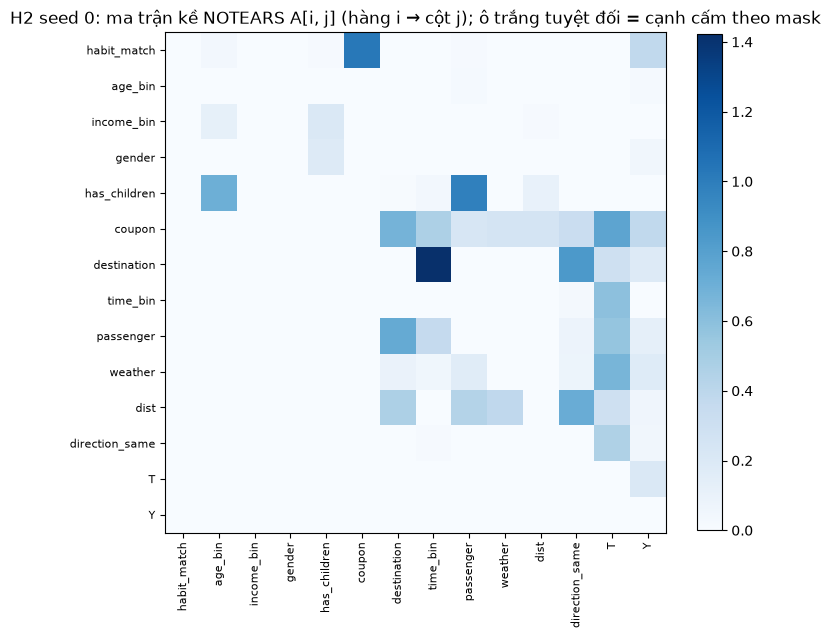

In [29]:
A_df = pd.DataFrame(H2_0["A"], index=NODES, columns=NODES)
A_df.to_csv(ART / "h2_adjacency_seed0.csv")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(A_df.values, cmap="Blues")
ax.set_xticks(range(len(NODES))); ax.set_xticklabels(NODES, rotation=90, fontsize=8)
ax.set_yticks(range(len(NODES))); ax.set_yticklabels(NODES, fontsize=8)
ax.set_title("H2 seed 0: ma trận kề NOTEARS A[i, j] (hàng i → cột j); ô trắng tuyệt đối = cạnh cấm theo mask")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.show()

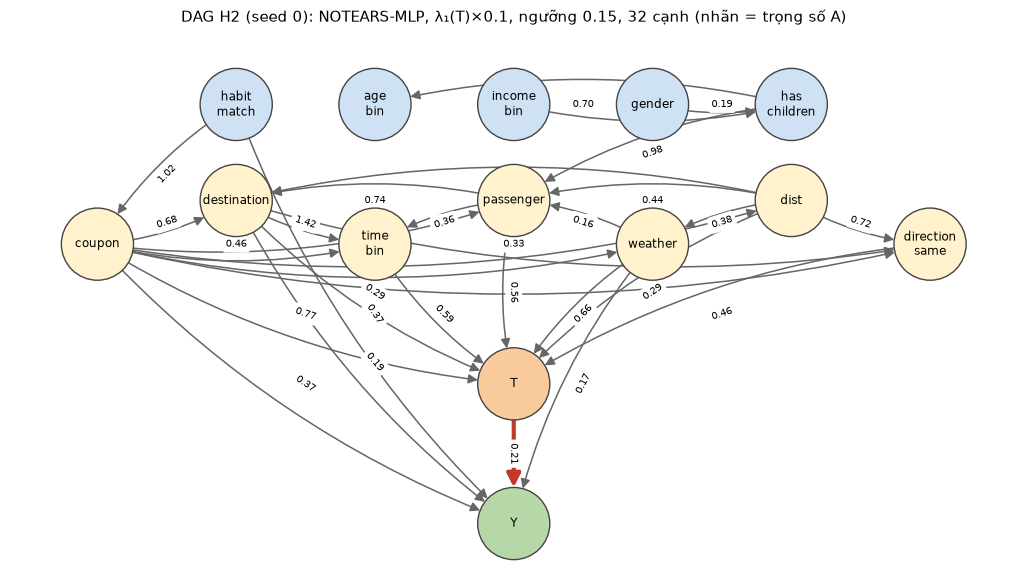

parents(Y) H2 = ['T', 'coupon', 'destination', 'habit_match', 'weather'] | parents(T) H2 = ['coupon', 'destination', 'direction_same', 'dist', 'passenger', 'time_bin', 'weather']


In [30]:
w = {(u, v): float(A_df.loc[u, v]) for u, v in H2_0["edges"]}
draw_dag(H2_0["edges"], f"DAG H2 (seed 0): NOTEARS-MLP, λ₁(T)×{H2_0['scale']}, ngưỡng {H2_0['thr']}, {len(H2_0['edges'])} cạnh (nhãn = trọng số A)", weights=w)
plt.savefig(ART / "dag_h2_seed0.png", dpi=130, bbox_inches="tight")
plt.show()
print("parents(Y) H2 =", sorted(H2_0["bn"].get_parents("Y")), "| parents(T) H2 =", sorted(H2_0["bn"].get_parents("T")))

In [31]:
MODEL_H2_0, ESTIMAND_H2_0 = dowhy_identify(H2_0["edges"], train0)
print("Re-identify trên DAG H2 (seed 0). Tập backdoor DoWhy chọn:", ESTIMAND_H2_0.get_backdoor_variables())
(ART / "identification_h2_seed0.txt").write_text(str(ESTIMAND_H2_0))
sym_diff = set(B0_0["edges"]) ^ set(H2_0["edges"])
print(f"So sánh cấu trúc B0 và H2 (seed 0): chung {len(set(B0_0['edges']) & set(H2_0['edges']))} cạnh, khác nhau {len(sym_diff)} cạnh (SHD có hướng = {len(sym_diff)})")

Re-identify trên DAG H2 (seed 0). Tập backdoor DoWhy chọn: ['destination', 'weather', 'coupon']
So sánh cấu trúc B0 và H2 (seed 0): chung 15 cạnh, khác nhau 45 cạnh (SHD có hướng = 45)


**Đọc kết quả.** Ở seed 0, B0 và H2 chỉ chung 15 cạnh (SHD 45) nhưng khác nhau chủ yếu ở các cạnh giữa biến nền; tập backdoor DoWhy chọn trên DAG H2 là {`destination`, `coupon`, `weather`} so với {`coupon`, `destination`, `habit_match`, `direction_same`, `time_bin`} trên DAG B0. Cạnh T → Y và parents(T) ⊆ tầng kịch bản xuất hiện ở cả hai; mục 11.1 xem điều đó có giữ qua 5 seed không.

<a id="11"></a>
## 11. Chạy 5 paired runs

Với mỗi seed: cùng TRAIN/VAL/TEST cho B0 → H1 (DAG của B0) → H2. Mỗi mô hình được chấm **dự đoán** trên TEST (Table A), **do-query** chuẩn hoá trên cohort TEST (Table B) và **bootstrap theo cụm người** trên TRAIN (200 lần, DAG cố định, cohort TEST cố định) để có khoảng tin cậy 95%. Thời gian fit và thời gian truy vấn được ghi lại.

In [32]:
def refit_table(spec: dict, boot: pd.DataFrame) -> pd.DataFrame:
    """Refit chỉ cơ chế của Y trên một TRAIN đã lấy mẫu lại, DAG giữ nguyên; trả về bảng P(Y=1 | parents).

    Tham số: spec — dict mô tả cách refit: {"kind": "bdeu", "bn": mạng B0/H2} (ước lượng lại CPD BDeu của Y)
             hoặc {"kind": "mlp", "parents", "val", "cfg", "seed"} (huấn luyện lại MLP của H1); boot — TRAIN bootstrap.
    """
    if spec["kind"] == "bdeu":
        cpd = BayesianEstimator(spec["bn"], boot[NODES], state_names=STATES).estimate_cpd(
            "Y", prior_type="BDeu", equivalent_sample_size=CONFIG["cpd"]["equivalent_sample_size"])
        f = cpd_to_frame(cpd)
        return f[f["Y"] == "1"].drop(columns="Y").rename(columns={"p": "p1"}).reset_index(drop=True)
    parents, val = spec["parents"], spec["val"]
    net_b, _ = train_mlp(onehot(boot, parents), (boot["Y"] == "1").astype(int).values,
                         onehot(val, parents), (val["Y"] == "1").astype(int).values, spec["cfg"], spec["seed"])
    return mlp_cpd(net_b, parents)[1]


def evaluate_model(name: str, seed: int, table: pd.DataFrame, train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame,
                   spec: dict, n_boot: int, rng: np.random.Generator) -> dict:
    """Chấm một mô hình đã fit: Table A (dự đoán TEST), Table B (do-query cohort TEST + bootstrap CI).

    Tham số: name — "B0"/"H1"/"H2"; table — bảng P(Y=1|parents); spec — mô tả refit cho bootstrap (refit_table); n_boot — số lần bootstrap.
    Trả về: dict một dòng kết quả.
    """
    yv, yt = (val["Y"] == "1").astype(int).values, (test["Y"] == "1").astype(int).values
    t0 = time.time()
    thr = choose_f1_threshold(yv, predict_y(table, val))
    pt = predict_y(table, test)
    met = prediction_metrics(yt, pt, thr)
    S = standardize(table, test)
    t_query = time.time() - t0
    t0 = time.time()
    boots = cluster_bootstrap(train, test, spec, n_boot, rng) if n_boot > 0 else pd.DataFrame([{"ATE": S["ATE"], **S["CATE"]}])
    t_boot = time.time() - t0
    lo, hi = percentile_ci(boots["ATE"].values, CONFIG["uncertainty"]["level"])
    cate_ci = {k: percentile_ci(boots[k].values, CONFIG["uncertainty"]["level"]) for k in S["CATE"]}
    return {"model": name, "seed": seed, **met, "n_test": len(test), "tỉ lệ Y=1 TEST": float(yt.mean()),
            "risk0": S["risk0"], "risk1": S["risk1"], "ATE": S["ATE"], "CI lo": lo, "CI hi": hi, "boot sd": float(boots["ATE"].std()),
            "CATE": S["CATE"], "CATE CI": cate_ci, "n_ref": S["n_ref"], "query_time": t_query, "boot_time": t_boot, "boots": boots}


RESULTS: dict = {}
RUNS: list[dict] = []
N_BOOT = CONFIG["uncertainty"]["n_boot"]
N_SEEDS = len(CONFIG["seeds"])
t_all = time.time()
for seed in CONFIG["seeds"]:
    rng = set_seed(seed)
    train, val, test = get_split(d, SPLITS, seed)
    t0 = time.time()
    b0 = run_b0(train, val)
    h1 = run_h1(b0["bn"], train, val, seed)
    h2 = run_h2(train, val, seed)
    for name, m in (("B0", b0), ("H1", h1), ("H2", h2)):
        spec = m["refit"] if name == "H1" else {"kind": "bdeu", "bn": m["bn"]}
        row = evaluate_model(name, seed, m["table"], train, val, test, spec, N_BOOT, rng)
        row.update({"fit_time": m["fit_time"], "n_edges": len(b0["edges"] if name == "H1" else m["edges"]),
                    "parents(Y)": ", ".join(sorted(m["bn"].get_parents("Y"))), "graph_id": f"{'B0' if name != 'H2' else 'H2'}-seed{seed}"})
        RUNS.append(row)
    RESULTS[seed] = {"B0": b0, "H1": h1, "H2": h2, "train": train, "val": val, "test": test}
    # lưu đồ thị, trọng số, CPD và checkpoint của từng run
    json.dump({"seed": seed, "chosen": b0["chosen"], "edges": b0["edges"]}, open(ART / f"b0_edges_seed{seed}.json", "w"), ensure_ascii=False, indent=1)
    json.dump({"seed": seed, "l1_scale_T": h2["scale"], "threshold": h2["thr"], "edges": h2["edges"], "removed": h2["removed"], "added": h2["added"], "info": {k: v for k, v in h2["info"].items() if k != "log"}},
              open(ART / f"h2_edges_seed{seed}.json", "w"), ensure_ascii=False, indent=1)
    pd.DataFrame(h2["A"], index=NODES, columns=NODES).to_csv(ART / f"h2_adjacency_seed{seed}.csv")
    b0["candidates"].to_csv(ART / f"b0_candidates_seed{seed}.csv", index=False)
    h2["thresholds"].to_csv(ART / f"h2_thresholds_seed{seed}.csv", index=False)
    torch.save(h1["net"].state_dict(), ART / f"h1_seed{seed}.pt")
    for name, m in (("B0", b0), ("H1", h1), ("H2", h2)):
        m["table"].to_csv(ART / f"cpd_y_{name}_seed{seed}.csv", index=False)
    print(f"seed {seed}: B0 = {b0['chosen']} ({len(b0['edges'])} cạnh) | H1 {h1['epochs']} epoch | H2 λ₁(T)×{h2['scale']} ngưỡng {h2['thr']} ({len(h2['edges'])} cạnh, T→Y khôi phục: {h2['recovered_TY']}) | {time.time() - t0:.0f}s")
print(f"Tổng thời gian {N_SEEDS} paired runs: {(time.time() - t_all) / 60:.1f} phút")

RUNS_DF = pd.DataFrame([{k: v for k, v in r.items() if k not in ("boots", "CATE", "CATE CI")} for r in RUNS])
RUNS_DF.to_csv(ART / "runs_raw.csv", index=False)
json.dump({"CONFIG": CONFIG, "ENV": ENV, "SOURCE": SOURCE}, open(ART / "config.json", "w"), ensure_ascii=False, indent=1, default=str)

seed 0: B0 = HC:k2:6 (43 cạnh) | H1 51 epoch | H2 λ₁(T)×0.1 ngưỡng 0.15 (32 cạnh, T→Y khôi phục: True) | 340s


seed 1: B0 = HC:k2:6 (41 cạnh) | H1 119 epoch | H2 λ₁(T)×0.3 ngưỡng 0.1 (36 cạnh, T→Y khôi phục: True) | 257s


seed 2: B0 = HC:k2:6 (43 cạnh) | H1 50 epoch | H2 λ₁(T)×0.1 ngưỡng 0.15 (32 cạnh, T→Y khôi phục: True) | 197s


seed 3: B0 = HC:k2:4 (36 cạnh) | H1 22 epoch | H2 λ₁(T)×0.1 ngưỡng 0.15 (32 cạnh, T→Y khôi phục: True) | 118s


seed 4: B0 = HC:k2:6 (41 cạnh) | H1 54 epoch | H2 λ₁(T)×0.1 ngưỡng 0.15 (33 cạnh, T→Y khôi phục: True) | 160s
Tổng thời gian 5 paired runs: 17.8 phút


### 11.1 Cấu trúc học được qua 5 seed

In [33]:
def edge_stability(edges_by_seed: dict[int, list]) -> pd.DataFrame:
    """Tần suất xuất hiện của từng cạnh qua các seed và Jaccard trung bình giữa các cặp seed."""
    seeds = sorted(edges_by_seed)
    sets = {s: set(map(tuple, edges_by_seed[s])) for s in seeds}
    all_edges = sorted(set().union(*sets.values()))
    freq = pd.DataFrame({"cạnh": [f"{u}→{v}" for u, v in all_edges],
                         "số seed": [sum(e in sets[s] for s in seeds) for e in all_edges]}).sort_values("số seed", ascending=False)
    jac = [len(sets[a] & sets[b]) / len(sets[a] | sets[b]) for a, b in itertools.combinations(seeds, 2)]
    freq.attrs["jaccard_mean"] = float(np.mean(jac))
    return freq


STRUCT = pd.DataFrame([{"seed": s, "B0 ứng viên": RESULTS[s]["B0"]["chosen"], "B0 cạnh": len(RESULTS[s]["B0"]["edges"]),
                        "B0 parents(Y)": ", ".join(sorted(RESULTS[s]["B0"]["bn"].get_parents("Y"))),
                        "B0 parents(T)": ", ".join(sorted(RESULTS[s]["B0"]["bn"].get_parents("T"))),
                        "H2 λ₁(T)×": RESULTS[s]["H2"]["scale"], "H2 ngưỡng": RESULTS[s]["H2"]["thr"], "H2 cạnh": len(RESULTS[s]["H2"]["edges"]),
                        "H2 parents(Y)": ", ".join(sorted(RESULTS[s]["H2"]["bn"].get_parents("Y"))),
                        "H2 parents(T)": ", ".join(sorted(RESULTS[s]["H2"]["bn"].get_parents("T"))),
                        "H2 T→Y khôi phục": bool(RESULTS[s]["H2"]["recovered_TY"]), "H2 chu trình bỏ": len(RESULTS[s]["H2"]["removed"]),
                        "SHD(B0,H2)": len(set(RESULTS[s]["B0"]["edges"]) ^ set(RESULTS[s]["H2"]["edges"]))} for s in CONFIG["seeds"]])
STRUCT.to_csv(ART / "structures.csv", index=False)
stab_b0 = edge_stability({s: RESULTS[s]["B0"]["edges"] for s in CONFIG["seeds"]})
stab_h2 = edge_stability({s: RESULTS[s]["H2"]["edges"] for s in CONFIG["seeds"]})
print(f"Jaccard trung bình giữa các seed: B0 = {stab_b0.attrs['jaccard_mean']:.3f}, H2 = {stab_h2.attrs['jaccard_mean']:.3f}")
n_seeds = len(CONFIG["seeds"])
print(f"Cạnh xuất hiện ở cả {n_seeds} seed: B0 {int((stab_b0['số seed'] == n_seeds).sum())}/{len(stab_b0)}, H2 {int((stab_h2['số seed'] == n_seeds).sum())}/{len(stab_h2)}")
STRUCT

Jaccard trung bình giữa các seed: B0 = 0.765, H2 = 0.771
Cạnh xuất hiện ở cả 5 seed: B0 28/52, H2 24/44


,seed,B0 ứng viên,B0 cạnh,B0 parents(Y),B0 parents(T),H2 λ₁(T)×,H2 ngưỡng,H2 cạnh,H2 parents(Y),H2 parents(T),H2 T→Y khôi phục,H2 chu trình bỏ,"SHD(B0,H2)"
0,0,HC:k2:6,43,"T, coupon, destination, direction_same, habit_...","coupon, destination, dist, passenger, time_bin...",0.1,0.15,32,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, pas...",True,0,45
1,1,HC:k2:6,41,"T, coupon, destination, direction_same, habit_...","coupon, destination, dist, passenger, time_bin...",0.3,0.10,36,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, pas...",True,0,43
2,2,HC:k2:6,43,"T, coupon, destination, direction_same, habit_...","coupon, destination, dist, passenger, time_bin...",0.1,0.15,32,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, pas...",True,0,39
3,3,HC:k2:4,36,"T, coupon, destination, habit_match","coupon, destination, dist, weather",0.1,0.15,32,"T, coupon, destination, habit_match","coupon, destination, direction_same, dist, pas...",True,0,34
4,4,HC:k2:6,41,"T, coupon, destination, direction_same, habit_...","coupon, destination, dist, passenger, time_bin...",0.1,0.15,33,"T, coupon, destination, habit_match, weather","coupon, destination, direction_same, dist, pas...",True,0,34


**Đọc bảng trên.** Hai cột `parents(T)` cho biết mỗi DAG có mô hình hoá cơ chế gán T hay không. Với H2, cột `H2 λ₁(T)×` là hệ số phạt L1 cho cạnh vào T mà VALIDATION chọn: log-loss của Y không phụ thuộc vào cạnh vào T, nên tiêu chí phụ (log-loss của T trên VALIDATION, tức là chấm riêng cơ chế gán T) quyết định và ưu tiên hệ số giữ được các cạnh kịch bản → T có ích cho việc dự đoán T. Nhờ đó H2 giữ đủ 7 parents kịch bản của T ở mọi seed; với phạt đồng đều (×1) cơ chế của T bị xoá ở 3/5 seed (mục 16.5). Cần nhớ rằng do-query của BN (mục 7.3) không dùng CPD của T, nên cạnh vào T chỉ ảnh hưởng tới tập backdoor mà DoWhy tìm ra, không ảnh hưởng tới ATE của BN.

In [34]:
print("Cạnh vào Y và vào T theo số seed xuất hiện (B0 | H2):")
pd.concat([stab_b0[stab_b0["cạnh"].str.endswith(("→Y", "→T"))].set_index("cạnh")["số seed"].rename("B0"),
           stab_h2[stab_h2["cạnh"].str.endswith(("→Y", "→T"))].set_index("cạnh")["số seed"].rename("H2")], axis=1).fillna(0).astype(int)

Cạnh vào Y và vào T theo số seed xuất hiện (B0 | H2):


,B0,H2
cạnh,,
T→Y,5,5
habit_match→Y,5,5
weather→T,5,5
dist→T,5,5
coupon→T,5,5
destination→Y,5,5
coupon→Y,5,5
destination→T,5,5
passenger→T,4,5


**Đọc kết quả.** Tám cạnh xuất hiện ở 5/5 seed của **cả hai** thuật toán: T → Y, `habit_match`/`coupon`/`destination` → Y và `coupon`/`destination`/`weather`/`dist` → T. Hai thuật toán chỉ bất đồng ở phần rìa của parents(Y): B0 thêm `direction_same` (4/5) và `time_bin` (2/5), H2 thêm `weather` (4/5); vì thế ATE của H2 lệch B0 khoảng 0,01 (mục 17.2) mà cấu trúc then chốt cho câu hỏi nhân quả thì giống nhau.

<a id="12"></a>
## 12. Table A: so sánh dự đoán trên TEST

Cùng dòng TEST, cùng evidence (mọi biến trừ Y). Báo cáo từng run, trung bình ± độ lệch chuẩn qua 5 seed, và chênh lệch có dấu H1 − B0, H2 − B0 theo từng seed.

In [35]:
METRICS_A = ["AUROC", "macro-F1", "Brier", "log loss"]
TABLE_A = RUNS_DF.pivot(index="seed", columns="model", values=METRICS_A + ["ngưỡng F1", "fit_time", "query_time"])
summary_A = RUNS_DF.groupby("model")[METRICS_A].agg(["mean", "std"]).round(4)
diffs_A = pd.concat([(RUNS_DF[RUNS_DF.model == m].set_index("seed")[METRICS_A] - RUNS_DF[RUNS_DF.model == "B0"].set_index("seed")[METRICS_A]).assign(so_sánh=f"{m} − B0")
                     for m in ("H1", "H2")])
diffs_A_summary = diffs_A.groupby("so_sánh")[METRICS_A].agg(["mean", "std"]).round(4)
RUNS_DF[["model", "seed"] + METRICS_A + ["ngưỡng F1", "n_test", "tỉ lệ Y=1 TEST", "graph_id", "fit_time", "query_time"]].round(4).to_csv(ART / "table_A_runs.csv", index=False)
print("Table A — từng run (TEST):")
display(RUNS_DF.pivot(index="seed", columns="model", values=METRICS_A).round(4))
print(f"Table A — tóm tắt qua {N_SEEDS} seed (mean, std):")
display(summary_A)
print(f"Chênh lệch có dấu so với B0 (mean, std qua {N_SEEDS} seed):")
diffs_A_summary

Table A — từng run (TEST):


AUROC                 macro-F1                   Brier                 log loss                
model      B0      H1      H2       B0      H1      H2      B0      H1      H2       B0      H1      H2
seed                                                                                                   
0      0.7201  0.7324  0.7240   0.6786  0.6763  0.6840  0.2093  0.2048  0.2083   0.6175  0.5986  0.6111
1      0.7514  0.7555  0.7553   0.6911  0.6949  0.6959  0.1968  0.1956  0.1960   0.5827  0.5766  0.5844
2      0.7413  0.7421  0.7371   0.6848  0.6880  0.6820  0.2033  0.2020  0.2048   0.5970  0.5906  0.6032
3      0.7365  0.7317  0.7365   0.6834  0.6760  0.6834  0.2042  0.2068  0.2042   0.5963  0.6013  0.5963
4      0.7474  0.7498  0.7448   0.6985  0.6987  0.6889  0.1990  0.1984  0.2015   0.5852  0.5833  0.5979

Table A — tóm tắt qua 5 seed (mean, std):


AUROC         macro-F1           Brier         log loss        
         mean     std     mean     std    mean     std     mean     std
model                                                                  
B0     0.7394  0.0122   0.6873  0.0077  0.2025  0.0049   0.5957  0.0137
H1     0.7423  0.0105   0.6868  0.0104  0.2015  0.0046   0.5901  0.0103
H2     0.7395  0.0115   0.6868  0.0057  0.2030  0.0046   0.5986  0.0098

Chênh lệch có dấu so với B0 (mean, std qua 5 seed):


AUROC         macro-F1           Brier         log loss        
           mean     std     mean     std    mean     std     mean     std
so_sánh                                                                  
H1 − B0  0.0029  0.0062  -0.0005  0.0046 -0.0010  0.0025  -0.0057  0.0087
H2 − B0  0.0002  0.0037  -0.0005  0.0061  0.0004  0.0015   0.0029  0.0071

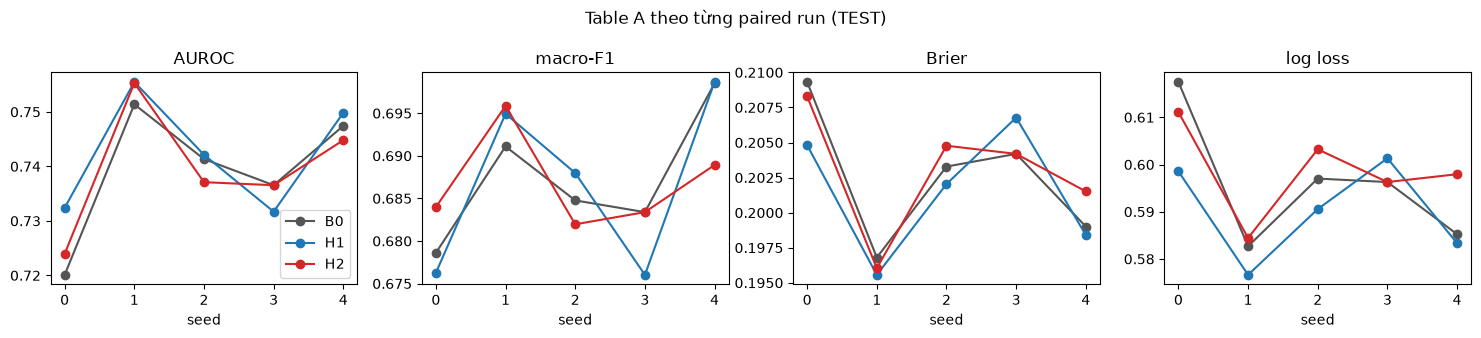

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, met in zip(axes, METRICS_A):
    for m, c in zip(("B0", "H1", "H2"), ("#555", "#1f77b4", "#d62728")):
        sub = RUNS_DF[RUNS_DF.model == m]
        ax.plot(sub["seed"], sub[met], "o-", color=c, label=m)
    ax.set_title(met); ax.set_xlabel("seed"); ax.set_xticks(CONFIG["seeds"])
axes[0].legend()
plt.suptitle("Table A theo từng paired run (TEST)")
plt.tight_layout()
plt.show()

**Đọc kết quả.** Ba đường gần như quấn vào nhau: chênh lệch trung bình giữa mô hình (≤ 0,006 log loss; trong một seed tối đa 0,019) nhỏ hơn chênh lệch của cùng mô hình giữa các seed (0,025–0,035), H1 thấp nhất về log loss ở 4/5 seed, H2 không khác B0. Mục 12.1 đặt ba BN cạnh hai mô hình không cấu trúc để biết DAG 4–6 parents giữ được bao nhiêu thông tin dự đoán; kết luận ở mục 17.2.

### 12.1 Mốc tham chiếu: mô hình dự đoán không có cấu trúc

Để biết ba BN "tốt đến đâu", so với hai mô hình dự đoán thuần tuý dùng **toàn bộ 13 biến** (one-hot) làm đầu vào, không có DAG: hồi quy logistic và gradient boosting (`HistGradientBoostingClassifier`, sklearn). Chúng không trả lời câu hỏi can thiệp, chỉ cho biết trần dự đoán mà dữ liệu cho phép với cùng tập biến.

In [37]:
def reference_predictors(train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame, seed: int) -> list[dict]:
    """Chấm hồi quy logistic và HistGradientBoosting trên one-hot của 13 biến (mọi nút trừ Y); trả về các dòng chỉ số như Table A."""
    feats = [c for c in NODES if c != "Y"]
    Xtr, Xv, Xte = onehot(train, feats), onehot(val, feats), onehot(test, feats)
    ytr, yv, yte = [(df["Y"] == "1").astype(int).values for df in (train, val, test)]
    rows = []
    for name, clf in (("Logistic (13 biến)", LogisticRegression(max_iter=2000, C=1.0)),
                      ("HistGradientBoosting (13 biến)", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4, random_state=seed))):
        t0 = time.time()
        clf.fit(Xtr, ytr)
        pv, pt = clf.predict_proba(Xv)[:, 1], clf.predict_proba(Xte)[:, 1]
        met = prediction_metrics(yte, pt, choose_f1_threshold(yv, pv))
        rows.append({"model": name, "seed": seed, **{k: met[k] for k in METRICS_A}, "fit_time": time.time() - t0})
    return rows


REF = pd.DataFrame([r for seed in CONFIG["seeds"] for r in reference_predictors(RESULTS[seed]["train"], RESULTS[seed]["val"], RESULTS[seed]["test"], seed)])
REF.round(4).to_csv(ART / "table_A_reference.csv", index=False)
ref_summary = pd.concat([RUNS_DF[["model", "seed"] + METRICS_A], REF[["model", "seed"] + METRICS_A]]).groupby("model")[METRICS_A].agg(["mean", "std"]).round(4)
print(f"Table A mở rộng: ba BN và hai mô hình tham chiếu không cấu trúc (mean, std qua {N_SEEDS} seed):")
ref_summary

Table A mở rộng: ba BN và hai mô hình tham chiếu không cấu trúc (mean, std qua 5 seed):


AUROC         macro-F1           Brier         log loss        
                                  mean     std     mean     std    mean     std     mean     std
model                                                                                           
B0                              0.7394  0.0122   0.6873  0.0077  0.2025  0.0049   0.5957  0.0137
H1                              0.7423  0.0105   0.6868  0.0104  0.2015  0.0046   0.5901  0.0103
H2                              0.7395  0.0115   0.6868  0.0057  0.2030  0.0046   0.5986  0.0098
HistGradientBoosting (13 biến)  0.7534  0.0055   0.6849  0.0042  0.1983  0.0017   0.5823  0.0057
Logistic (13 biến)              0.7339  0.0060   0.6755  0.0089  0.2044  0.0025   0.5961  0.0052

<a id="13"></a>
## 13. Table B: so sánh can thiệp trên cohort TEST

Cùng cohort tham chiếu (TEST của seed đó), cùng giá trị control T = 0 (1 ngày) và treatment T = 1 (2 giờ). Khoảng tin cậy 95% = percentile của 200 lần cluster-bootstrap TRAIN theo `resp_id` (refit cơ chế của Y, DAG cố định, cohort TEST cố định). Cột "backdoor DoWhy" là tập điều chỉnh nhỏ nhất DoWhy tìm được trên DAG tương ứng (với B0 luôn có `habit_match` của tầng người trả lời, mục 8.3); cột chuẩn hoá dùng toàn bộ $C_\text{full}$ (hợp lệ vì là siêu tập không chứa descendant của T; `dowhy_reference_estimate` assert tiêu chí backdoor cho cả hai tập ở mọi seed).

In [38]:
def dowhy_reference_estimate(edges: list[tuple[str, str]], train: pd.DataFrame, test: pd.DataFrame) -> dict:
    """Ước lượng độc lập bằng DoWhy: backdoor linear regression (risk difference), target_units = cohort TEST.

    Trả về: dict gồm model, estimand, estimate, tập backdoor, ATE, CI, thời gian.
    """
    t0 = time.time()
    model, estimand = dowhy_identify(edges, train)
    # need_conditional_estimates=False: chỉ cần ATE; nhánh CATE nội bộ của DoWhy dùng groupby.apply và lỗi với pandas 3
    est = model.estimate_effect(estimand, method_name="backdoor.linear_regression", control_value=0, treatment_value=1,
                                target_units=to_dowhy_frame(test), confidence_intervals=True,
                                method_params={"need_conditional_estimates": False})
    ci = np.asarray(est.get_confidence_intervals()).ravel()
    for Z in (estimand.get_backdoor_variables(), C_FULL):      # mục 8.3: cả tập DoWhy chọn lẫn C_full phải thoả tiêu chí backdoor
        assert check_backdoor(edges, Z)["hợp lệ"], f"tập điều chỉnh không hợp lệ: {Z}"
    return {"model": model, "estimand": estimand, "estimate": est, "backdoor": estimand.get_backdoor_variables(),
            "ATE": float(est.value), "CI": (float(ci[0]), float(ci[1])), "time": time.time() - t0}


DOWHY: dict = {}
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    DOWHY[seed] = {"B0": dowhy_reference_estimate(R["B0"]["edges"], R["train"], R["test"]),
                   "H2": dowhy_reference_estimate(R["H2"]["edges"], R["train"], R["test"])}
    (ART / f"identification_b0_seed{seed}.txt").write_text(str(DOWHY[seed]["B0"]["estimand"]))
    (ART / f"identification_h2_seed{seed}.txt").write_text(str(DOWHY[seed]["H2"]["estimand"]))

BD_ALL = pd.DataFrame([{"DAG": g, "seed": seed, "tập": lab, "Z": ", ".join(sorted(Z)), **check_backdoor(RESULTS[seed][g]["edges"], Z)}
                       for seed in CONFIG["seeds"] for g in ("B0", "H2")
                       for lab, Z in (("DoWhy chọn", DOWHY[seed][g]["backdoor"]), ("parents(T)", list(RESULTS[seed][g]["bn"].get_parents("T"))),
                                      ("C_full", C_FULL), ("rỗng", []))])
BD_ALL.to_csv(ART / "backdoor_check.csv", index=False)
print(f"Tiêu chí backdoor (mục 8.3) cho {N_SEEDS} seed × 2 DAG × 4 tập: số tập hợp lệ / tổng:")
display(BD_ALL.groupby(["DAG", "tập"])[["hợp lệ", "tối thiểu"]].agg(["sum", "count"]))

rows_B = []
for r in RUNS:
    dw = DOWHY[r["seed"]]["H2" if r["model"] == "H2" else "B0"]
    rows_B.append({"model": r["model"], "seed": r["seed"], "cohort": f"TEST-seed{r['seed']}", "n_ref": r["n_ref"], "T control/treat": "1d=0 / 2h=1",
                   "graph": r["graph_id"], "backdoor DoWhy": ", ".join(dw["backdoor"]), "chuẩn hoá theo": "C_full (12 biến nền TEST)",
                   "risk(0)": r["risk0"], "risk(1)": r["risk1"], "ATE": r["ATE"], "CI95 lo": r["CI lo"], "CI95 hi": r["CI hi"],
                   "phương pháp CI": f"cluster bootstrap B={N_BOOT}", "overlap": "đủ (coupon × destination: ≥ 30 dòng/nhánh T mọi ô)",
                   "DoWhy ATE (lin. reg.)": dw["ATE"], "DoWhy CI lo": dw["CI"][0], "DoWhy CI hi": dw["CI"][1]})
TABLE_B = pd.DataFrame(rows_B)
TABLE_B.round(4).to_csv(ART / "table_B_runs.csv", index=False)
print("Table B — từng run:")
display(TABLE_B[["model", "seed", "cohort", "n_ref", "graph", "backdoor DoWhy", "risk(0)", "risk(1)", "ATE", "CI95 lo", "CI95 hi", "DoWhy ATE (lin. reg.)"]].round(4))
summary_B = TABLE_B.groupby("model")[["risk(0)", "risk(1)", "ATE", "DoWhy ATE (lin. reg.)"]].agg(["mean", "std"]).round(4)
print(f"Table B — tóm tắt qua {N_SEEDS} seed:")
summary_B

Tiêu chí backdoor (mục 8.3) cho 5 seed × 2 DAG × 4 tập: số tập hợp lệ / tổng:


hợp lệ       tối thiểu      
                  sum count       sum count
DAG tập                                    
B0  C_full          5     5         0     5
    DoWhy chọn      5     5         5     5
    parents(T)      5     5         5     5
    rỗng            0     5         0     5
H2  C_full          5     5         0     5
    DoWhy chọn      5     5         5     5
    parents(T)      5     5         0     5
    rỗng            0     5         0     5

Table B — từng run:


,model,seed,cohort,n_ref,graph,backdoor DoWhy,risk(0),risk(1),ATE,CI95 lo,CI95 hi,DoWhy ATE (lin. reg.)
0,B0,0,TEST-seed0,1824,B0-seed0,"direction_same, time_bin, destination, coupon,...",0.6519,0.4892,-0.1627,-0.1899,-0.1412,-0.1679
1,H1,0,TEST-seed0,1824,B0-seed0,"direction_same, time_bin, destination, coupon,...",0.6585,0.4891,-0.1694,-0.1926,-0.1487,-0.1679
2,H2,0,TEST-seed0,1824,H2-seed0,"destination, weather, coupon",0.6459,0.5015,-0.1443,-0.1620,-0.1222,-0.1660
3,B0,1,TEST-seed1,1813,B0-seed1,"direction_same, destination, coupon, habit_match",0.6353,0.4810,-0.1542,-0.1810,-0.1352,-0.1653
4,H1,1,TEST-seed1,1813,B0-seed1,"direction_same, destination, coupon, habit_match",0.6354,0.4773,-0.1581,-0.1772,-0.1302,-0.1653
5,H2,1,TEST-seed1,1813,H2-seed1,"destination, weather, coupon",0.6295,0.4843,-0.1452,-0.1656,-0.1206,-0.1630
6,B0,2,TEST-seed2,1831,B0-seed2,"direction_same, time_bin, destination, coupon,...",0.6553,0.4797,-0.1756,-0.2025,-0.1548,-0.1809
7,H1,2,TEST-seed2,1831,B0-seed2,"direction_same, time_bin, destination, coupon,...",0.6479,0.4806,-0.1673,-0.1945,-0.1460,-0.1809
8,H2,2,TEST-seed2,1831,H2-seed2,"destination, weather, coupon",0.6563,0.4996,-0.1566,-0.1807,-0.1288,-0.1783
9,B0,3,TEST-seed3,1796,B0-seed3,"destination, coupon, habit_match",0.6603,0.4817,-0.1785,-0.2026,-0.1549,-0.1725


Table B — tóm tắt qua 5 seed:


risk(0)         risk(1)             ATE         DoWhy ATE (lin. reg.)        
         mean     std    mean     std    mean     std                  mean     std
model                                                                              
B0     0.6506  0.0094  0.4864  0.0085 -0.1643  0.0125               -0.1699  0.0071
H1     0.6486  0.0096  0.4856  0.0066 -0.1630  0.0056               -0.1699  0.0071
H2     0.6483  0.0119  0.4928  0.0091 -0.1555  0.0139               -0.1677  0.0074

Chênh lệch thô P(Y=1|T=1) − P(Y=1|T=0) trên TEST (không điều chỉnh): mean -0.1531, sd 0.0130
Khoảng cách nhỏ giữa chênh thô và ATE điều chỉnh là hệ quả của giả định G1 (T gần như được gán ngẫu nhiên trong mỗi kịch bản).


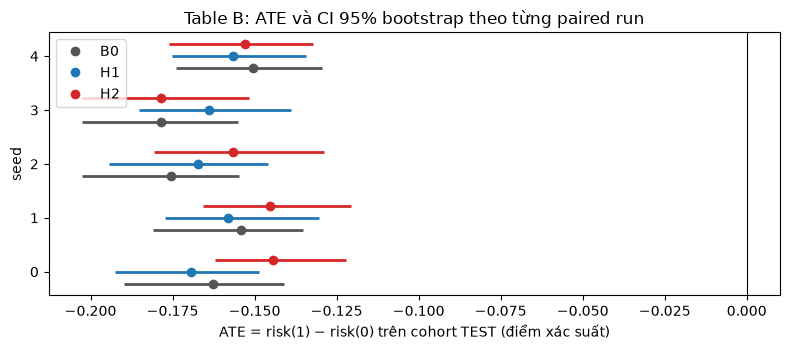

In [39]:
naive = pd.Series({s: float((RESULTS[s]["test"].query("T == '1'")["Y"] == "1").mean() - (RESULTS[s]["test"].query("T == '0'")["Y"] == "1").mean()) for s in CONFIG["seeds"]})
print(f"Chênh lệch thô P(Y=1|T=1) − P(Y=1|T=0) trên TEST (không điều chỉnh): mean {naive.mean():+.4f}, sd {naive.std():.4f}")
print("Khoảng cách nhỏ giữa chênh thô và ATE điều chỉnh là hệ quả của giả định G1 (T gần như được gán ngẫu nhiên trong mỗi kịch bản).")

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, m in enumerate(("B0", "H1", "H2")):
    sub = TABLE_B[TABLE_B.model == m]
    y = sub["seed"] + (i - 1) * 0.22
    c = ["#555", "#1f77b4", "#d62728"][i]
    ax.hlines(y, sub["CI95 lo"], sub["CI95 hi"], color=c, lw=2)
    ax.plot(sub["ATE"], y, "o", color=c, label=m)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(CONFIG["seeds"]); ax.set_ylabel("seed"); ax.set_xlabel("ATE = risk(1) − risk(0) trên cohort TEST (điểm xác suất)")
ax.set_title("Table B: ATE và CI 95% bootstrap theo từng paired run"); ax.legend()
plt.tight_layout(); plt.show()

**Đọc kết quả.** Cả 15 CI (3 mô hình × 5 seed) nằm hẳn dưới 0; H1 trùng B0, H2 kém âm hơn ≈ 0,01 vì parents(Y) khác (mục 11.1). Chênh thô −0,153 chỉ cách ATE điều chỉnh ≈ 0,01, đúng với việc T gần như được gán ngẫu nhiên trong mỗi kịch bản (mục 5.4); diễn giải đầy đủ và bảng tổng hợp ở mục 17.1.

### 13.1 CATE theo loại coupon

Hiệu ứng của hạn 2 giờ rất khác nhau theo loại quán: trung bình $q_m(1, C_i) - q_m(0, C_i)$ trong từng nhóm `coupon` của cohort TEST, lấy trung bình qua 5 seed.

Bar         Carry out & Take away         Coffee House         Restaurant(20-50)         Restaurant(<20)        
         mean     std                  mean     std         mean     std              mean     std            mean     std
model                                                                                                                     
B0    -0.0415  0.0330               -0.1377  0.0175      -0.1431  0.0196           -0.2452  0.0402         -0.2427  0.0121
H1    -0.0712  0.0306               -0.1513  0.0181      -0.1401  0.0184           -0.2145  0.0141         -0.2291  0.0261
H2    -0.0159  0.0259               -0.1410  0.0230      -0.1479  0.0145           -0.2361  0.0434         -0.2140  0.0258

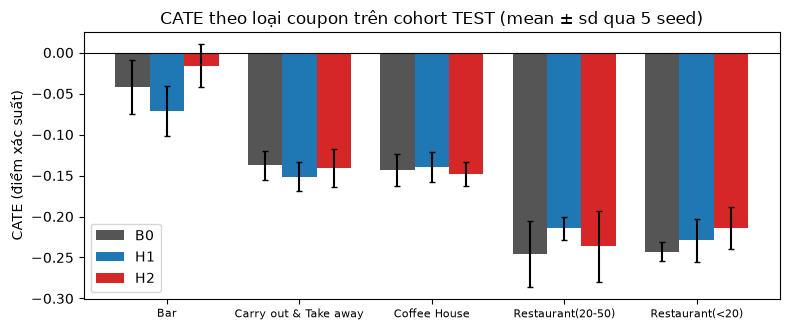

In [40]:
CATE = pd.DataFrame([{"model": r["model"], "seed": r["seed"], **r["CATE"]} for r in RUNS])
CATE_summary = CATE.groupby("model")[STATES["coupon"]].agg(["mean", "std"]).round(4)
CATE.round(4).to_csv(ART / "cate_by_coupon.csv", index=False)
display(CATE_summary)
fig, ax = plt.subplots(figsize=(8, 3.4))
means = CATE.groupby("model")[STATES["coupon"]].mean()
sds = CATE.groupby("model")[STATES["coupon"]].std()
x = np.arange(len(STATES["coupon"]))
for i, m in enumerate(("B0", "H1", "H2")):
    ax.bar(x + (i - 1) * 0.26, means.loc[m], 0.26, yerr=sds.loc[m], capsize=2, label=m, color=["#555", "#1f77b4", "#d62728"][i])
ax.set_xticks(x); ax.set_xticklabels(STATES["coupon"], fontsize=8); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("CATE (điểm xác suất)"); ax.set_title(f"CATE theo loại coupon trên cohort TEST (mean ± sd qua {N_SEEDS} seed)"); ax.legend()
plt.tight_layout(); plt.show()

Thanh lỗi ở hình trên là độ lệch chuẩn **giữa 5 seed**, tức là độ nhạy với cách chia dữ liệu. Bất định lấy mẫu *trong một run* lấy từ cùng bootstrap theo cụm của mục 11: mỗi lần refit cơ chế của Y trên TRAIN đã lấy mẫu lại cho một bộ CATE trên cohort TEST cố định, nên CI percentile của CATE theo coupon có sẵn mà không tốn thêm tính toán. Câu hỏi là CATE của Bar có khác 0 không, và CI của Bar rộng hơn các coupon khác bao nhiêu (Bar chỉ chiếm ≈ 13 % dòng hợp lệ, và ô Bar × Work đã bị loại ở mục 5 vì không có overlap).

CATE theo coupon với CI 95 % bootstrap theo cụm (B = 200) trung bình qua 5 seed; cột cuối = số seed (trên 5) có CI chứa 0:


CATE  lo_mean  hi_mean  nửa_khoảng  seed_CI_chứa_0
model coupon                                                                     
B0    Bar                   -0.0415  -0.1061   0.0249      0.0655               4
      Carry out & Take away -0.1377  -0.1908  -0.0880      0.0514               0
      Coffee House          -0.1431  -0.1847  -0.1022      0.0413               0
      Restaurant(20-50)     -0.2452  -0.3076  -0.1812      0.0632               0
      Restaurant(<20)       -0.2427  -0.2870  -0.2007      0.0432               0
H1    Bar                   -0.0712  -0.1148  -0.0292      0.0428               0
      Carry out & Take away -0.1513  -0.1948  -0.1118      0.0415               0
      Coffee House          -0.1401  -0.1743  -0.1078      0.0333               0
      Restaurant(20-50)     -0.2145  -0.2695  -0.1616      0.0539               0
      Restaurant(<20)       -0.2291  -0.2589  -0.1812      0.0388               0
H2    Bar                   -0.0159  -0.0733   0.0413      0.0573               5
      Carry out & Take away -0.1410  -0.1849  -0.0950      0.0449               0
      Coffee House          -0.1479  -0.1896  -0.1076      0.0410               0
      Restaurant(20-50)     -0.2361  -0.2955  -0.1713      0.0621               0
      Restaurant(<20)       -0.2140  -0.2523  -0.1722      0.0401               0

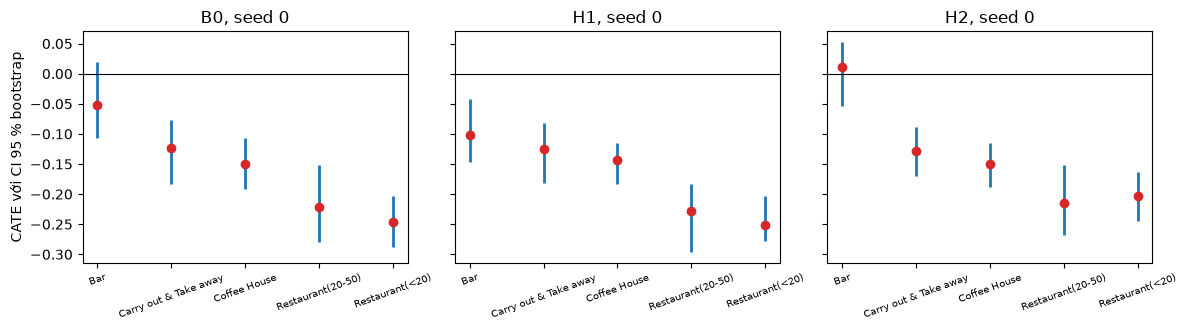

In [41]:
CATE_CI = pd.DataFrame([{"model": r["model"], "seed": r["seed"], "coupon": c, "CATE": r["CATE"][c], "CI95 lo": r["CATE CI"][c][0], "CI95 hi": r["CATE CI"][c][1]}
                        for r in RUNS for c in STATES["coupon"]])
CATE_CI["nửa khoảng CI"] = (CATE_CI["CI95 hi"] - CATE_CI["CI95 lo"]) / 2
CATE_CI["CI chứa 0"] = (CATE_CI["CI95 lo"] <= 0) & (CATE_CI["CI95 hi"] >= 0)
CATE_CI.round(4).to_csv(ART / "cate_ci_by_coupon.csv", index=False)
cate_ci_summary = CATE_CI.groupby(["model", "coupon"], sort=False).agg(CATE=("CATE", "mean"), lo_mean=("CI95 lo", "mean"), hi_mean=("CI95 hi", "mean"),
                                                                      nửa_khoảng=("nửa khoảng CI", "mean"), seed_CI_chứa_0=("CI chứa 0", "sum")).round(4)
print(f"CATE theo coupon với CI 95 % bootstrap theo cụm (B = {N_BOOT}) trung bình qua {N_SEEDS} seed; cột cuối = số seed (trên {N_SEEDS}) có CI chứa 0:")
display(cate_ci_summary)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, m in zip(axes, ("B0", "H1", "H2")):
    sub = CATE_CI[(CATE_CI.model == m) & (CATE_CI.seed == CONFIG["seeds"][0])].set_index("coupon").loc[STATES["coupon"]]
    ax.vlines(np.arange(len(sub)), sub["CI95 lo"], sub["CI95 hi"], color="#1f77b4", lw=2)
    ax.plot(np.arange(len(sub)), sub["CATE"], "o", color="#d62728")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(np.arange(len(sub))); ax.set_xticklabels(sub.index, fontsize=7, rotation=20); ax.set_title(f"{m}, seed {CONFIG['seeds'][0]}")
axes[0].set_ylabel("CATE với CI 95 % bootstrap")
plt.tight_layout(); plt.savefig(ART / "cate_ci_seed0.png", dpi=120, bbox_inches="tight"); plt.show()

**Đọc kết quả.** Bốn loại coupon ngoài Bar có CI 95 % nằm hẳn dưới 0 ở cả 5 seed và cả ba mô hình: hiệu ứng của hạn 2 giờ lên coupon nhà hàng, cà phê, mang về là thật, không phải nhiễu lấy mẫu. **Bar là ngoại lệ:** với B0, CI trung bình [−0,11; +0,02] chứa 0 ở 4/5 seed; với H2 chứa 0 ở cả 5 seed; nửa khoảng CI của Bar (≈ 0,066 với B0) rộng hơn các coupon khác (0,041–0,063) vì ô Bar thưa. Trong ba mô hình chính, H1 là mô hình duy nhất cho Bar khác 0 (−0,07, CI [−0,11; −0,03], 0/5 seed chứa 0) vì MLP chia sẻ tham số giữa các ô nên bất định ở ô thưa nhỏ hơn, nhưng cũng vì thế mà ước lượng của nó phụ thuộc vào giả định hàm của MLP (MLP có phạt đơn điệu ở mục 16.7 cũng cho Bar khác 0). Kết luận an toàn: **dữ liệu không đủ để khẳng định hạn 2 giờ có tác dụng với coupon Bar**; với bốn loại còn lại hiệu ứng âm là chắc chắn.

### 13.2 Các ô có τ > 0 của B0: hiệu ứng thật hay nhiễu lấy mẫu?

Table B (và bảng theo mô hình ở mục 16.6) cho thấy B0 gán τ > 0 cho một phần dòng TEST. Mỗi τ là hiệu ứng của một **ô** (tổ hợp các parents(Y) khác T), ước lượng từ hai ô con T = 0 và T = 1 bằng BDeu. Để biết các τ dương có ý nghĩa không, ta lặp lại cluster bootstrap của mục 7.3 nhưng lưu τ **của từng ô** thay vì ATE, rồi so bề rộng CI và số dòng TRAIN của các ô τ > 0 với các ô τ ≤ 0. Nếu các ô τ > 0 là ô thưa với CI chứa 0 thì đó là nhiễu lấy mẫu, không phải bằng chứng cho hiệu ứng ngược chiều.

B0 seed 0: 270 ô trong bảng CPD, 98 ô có dòng TEST; bootstrap 200 lần theo cụm, 4s


,số ô,số dòng TEST,n TRAIN nhỏ nhất (median),bề rộng CI (median),tỉ lệ ô có CI chứa 0,tỉ lệ ô có ô con trống
nhóm,,,,,,
τ > 0,19,357,11.0,0.422,0.947,0.105
τ ≤ 0,79,1467,22.0,0.423,0.506,0.089


Trong các dòng TEST thuộc ô τ > 0: 94.7% thuộc ô có CI chứa 0; 6.2% thuộc ô có một ô con (T=0 hoặc T=1) trống trên TRAIN; 27.5% thuộc ô có ô con < 10 dòng
Ô τ > 0 có CI không chứa 0: 1 ô (19 dòng TEST), trong đó 1 ô có ô con trống (BDeu kéo về 0,5 ở mọi lần bootstrap nên CI không phản ánh độ bất định này)
Các ô τ > 0 có nhiều dòng TEST nhất:


,coupon,destination,direction_same,habit_match,time_bin,tau,n TRAIN T=0,n TRAIN T=1,n TEST,CI lo,CI hi
22,Bar,No Urgent Place,0,low,evening,0.041,93,109,65,-0.065,0.165
134,Coffee House,No Urgent Place,0,mid,morning,0.106,52,104,32,-0.052,0.271
4,Bar,Home,0,low,evening,0.181,63,31,28,-0.002,0.419
80,Carry out & Take away,No Urgent Place,0,mid,morning,0.043,35,96,27,-0.110,0.258
64,Carry out & Take away,Home,1,high,evening,0.034,46,57,22,-0.102,0.156
238,Restaurant(<20),No Urgent Place,0,low,evening,0.035,37,51,21,-0.133,0.278
149,Coffee House,Work,0,low,morning,0.076,52,123,21,-0.049,0.214
186,Restaurant(20-50),No Urgent Place,0,mid,afternoon,0.055,9,10,19,-0.333,0.541


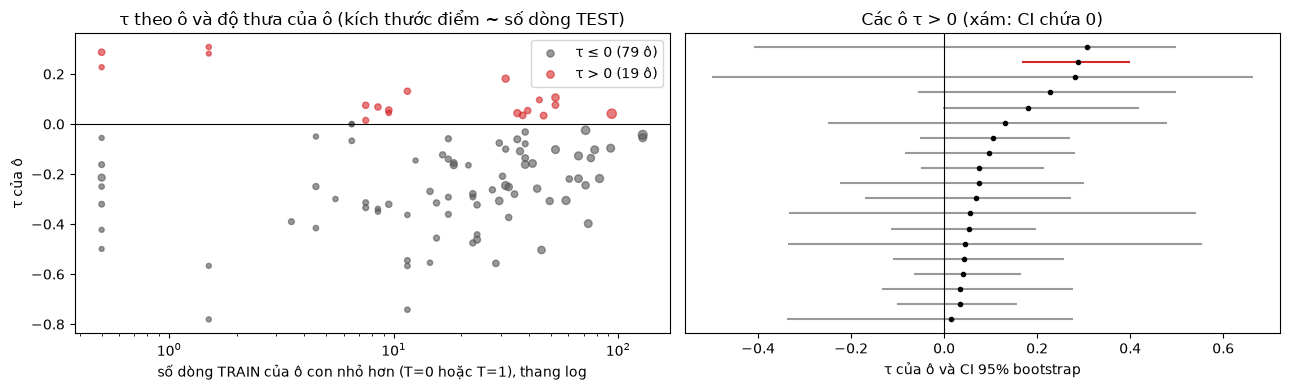

In [42]:
def cell_effects(table: pd.DataFrame) -> pd.DataFrame:
    """τ theo ô từ bảng P(Y=1 | parents): ô = tổ hợp parents(Y) trừ T; τ = p1(T=1) − p1(T=0).

    Tham số: table — bảng CPD của Y (cột parents + p1).
    Trả về: DataFrame gồm các cột ô và cột tau.
    """
    keys = [c for c in table.columns if c not in ("T", "p1")]
    w = table.pivot_table(index=keys, columns="T", values="p1").reset_index()
    w["tau"] = w["1"] - w["0"]
    return w[keys + ["tau"]]


def cell_effect_bootstrap(train: pd.DataFrame, spec: dict, n_boot: int, rng: np.random.Generator) -> pd.DataFrame:
    """Cluster bootstrap theo resp_id (như cluster_bootstrap) nhưng trả về τ của từng ô ở mỗi lần lặp.

    Tham số: train — TRAIN; spec — mô tả refit cơ chế của Y (refit_table); n_boot — số lần lặp; rng — Generator đã seed.
    Trả về: DataFrame gồm các cột ô, tau và boot (chỉ số lần lặp).
    """
    groups = train["resp_id"].unique()
    by_group = {g: idx for g, idx in train.groupby("resp_id").indices.items()}
    out = []
    for b in range(n_boot):
        chosen = rng.choice(groups, size=len(groups), replace=True)
        idx = np.concatenate([by_group[g] for g in chosen])
        out.append(cell_effects(refit_table(spec, train.iloc[idx].reset_index(drop=True))).assign(boot=b))
    return pd.concat(out, ignore_index=True)


R0 = RESULTS[0]
CELLS = cell_effects(R0["B0"]["table"])
CELL_KEYS = [c for c in CELLS.columns if c != "tau"]
n_tr = R0["train"].groupby(CELL_KEYS + ["T"]).size().unstack("T", fill_value=0).rename(columns={"0": "n TRAIN T=0", "1": "n TRAIN T=1"}).reset_index()
n_te = R0["test"].groupby(CELL_KEYS).size().rename("n TEST").reset_index()
t0 = time.time()
CELL_BOOT = cell_effect_bootstrap(R0["train"], {"kind": "bdeu", "bn": R0["B0"]["bn"]}, N_BOOT, set_seed(0))
ci = CELL_BOOT.groupby(CELL_KEYS)["tau"].quantile([0.025, 0.975]).unstack().rename(columns={0.025: "CI lo", 0.975: "CI hi"}).reset_index()
CELLS = CELLS.merge(n_tr, on=CELL_KEYS, how="left").merge(n_te, on=CELL_KEYS, how="left").merge(ci, on=CELL_KEYS, how="left")
CELLS[["n TRAIN T=0", "n TRAIN T=1", "n TEST"]] = CELLS[["n TRAIN T=0", "n TRAIN T=1", "n TEST"]].fillna(0).astype(int)
CELLS["n TRAIN nhỏ nhất"] = CELLS[["n TRAIN T=0", "n TRAIN T=1"]].min(axis=1)
CELLS["nhóm"] = np.where(CELLS["tau"] > 0, "τ > 0", "τ ≤ 0")
CELLS["CI chứa 0"] = (CELLS["CI lo"] <= 0) & (CELLS["CI hi"] >= 0)
CELLS["bề rộng CI"] = CELLS["CI hi"] - CELLS["CI lo"]
USED = CELLS[CELLS["n TEST"] > 0]
cell_summary = USED.groupby("nhóm").agg(**{"số ô": ("tau", "size"), "số dòng TEST": ("n TEST", "sum"), "n TRAIN nhỏ nhất (median)": ("n TRAIN nhỏ nhất", "median"),
                                           "bề rộng CI (median)": ("bề rộng CI", "median"), "tỉ lệ ô có CI chứa 0": ("CI chứa 0", "mean"),
                                           "tỉ lệ ô có ô con trống": ("n TRAIN nhỏ nhất", lambda v: float((v == 0).mean()))})
w_pos = USED[USED["nhóm"] == "τ > 0"]
print(f"B0 seed 0: {len(CELLS)} ô trong bảng CPD, {len(USED)} ô có dòng TEST; bootstrap {N_BOOT} lần theo cụm, {time.time() - t0:.0f}s")
display(cell_summary.round(3))
print(f"Trong các dòng TEST thuộc ô τ > 0: {(w_pos['n TEST'] * w_pos['CI chứa 0']).sum() / max(w_pos['n TEST'].sum(), 1):.1%} thuộc ô có CI chứa 0; "
      f"{(w_pos['n TEST'] * (w_pos['n TRAIN nhỏ nhất'] == 0)).sum() / max(w_pos['n TEST'].sum(), 1):.1%} thuộc ô có một ô con (T=0 hoặc T=1) trống trên TRAIN; "
      f"{(w_pos['n TEST'] * (w_pos['n TRAIN nhỏ nhất'] < 10)).sum() / max(w_pos['n TEST'].sum(), 1):.1%} thuộc ô có ô con < 10 dòng")
print(f"Ô τ > 0 có CI không chứa 0: {int((~w_pos['CI chứa 0']).sum())} ô ({int(w_pos.loc[~w_pos['CI chứa 0'], 'n TEST'].sum())} dòng TEST), "
      f"trong đó {int(((~w_pos['CI chứa 0']) & (w_pos['n TRAIN nhỏ nhất'] == 0)).sum())} ô có ô con trống (BDeu kéo về 0,5 ở mọi lần bootstrap nên CI không phản ánh độ bất định này)")
print("Các ô τ > 0 có nhiều dòng TEST nhất:")
display(w_pos.sort_values("n TEST", ascending=False).head(8)[CELL_KEYS + ["tau", "n TRAIN T=0", "n TRAIN T=1", "n TEST", "CI lo", "CI hi"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for g, c in (("τ ≤ 0", "#555"), ("τ > 0", "#d62728")):
    sub = USED[USED["nhóm"] == g]
    axes[0].scatter(sub["n TRAIN nhỏ nhất"] + 0.5, sub["tau"], s=12 + sub["n TEST"] / 2, color=c, alpha=0.6, label=f"{g} ({len(sub)} ô)")
axes[0].set_xscale("log"); axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].set_xlabel("số dòng TRAIN của ô con nhỏ hơn (T=0 hoặc T=1), thang log"); axes[0].set_ylabel("τ của ô"); axes[0].legend()
axes[0].set_title("τ theo ô và độ thưa của ô (kích thước điểm ~ số dòng TEST)")
pos = w_pos.sort_values("tau").reset_index(drop=True)
axes[1].hlines(range(len(pos)), pos["CI lo"], pos["CI hi"], color=np.where(pos["CI chứa 0"], "#999", "#d62728"))
axes[1].plot(pos["tau"], range(len(pos)), "o", color="k", markersize=3); axes[1].axvline(0, color="k", linewidth=0.8)
axes[1].set_yticks([]); axes[1].set_xlabel("τ của ô và CI 95% bootstrap"); axes[1].set_title("Các ô τ > 0 (xám: CI chứa 0)")
plt.tight_layout(); plt.show()
CELLS.round(4).to_csv(ART / "cell_effects_b0_seed0.csv", index=False)

**Đọc kết quả.** 18/19 ô τ > 0 của B0 có CI chứa 0 (so với 51 % ở nhóm τ ≤ 0) và là ô thưa hơn (ô con nhỏ hơn: median 11 dòng TRAIN so với 22); ô duy nhất có CI không chứa 0 là ô có ô con trống, nơi BDeu kéo xác suất về 0,5 ở mọi lần bootstrap nên CI không phản ánh bất định thật. Kết luận: các hiệu ứng dương của B0 là nhiễu lấy mẫu ở ô thưa, không phải bằng chứng cho hiệu ứng ngược chiều.

<a id="14"></a>
## 14. DoWhy: identify, estimate và hai refuter

### 14.1 Identify và ước lượng độc lập (seed 0)

In [43]:
print(DOWHY[0]["B0"]["estimand"])
print(f"DoWhy (DAG B0, seed 0): ATE = {DOWHY[0]['B0']['ATE']:+.4f}, CI 95% = {DOWHY[0]['B0']['CI']}  |  BN B0 chuẩn hoá: {RUNS_DF.query('model == \"B0\" and seed == 0')['ATE'].iloc[0]:+.4f}")
print(f"DoWhy (DAG H2, seed 0): ATE = {DOWHY[0]['H2']['ATE']:+.4f}, CI 95% = {DOWHY[0]['H2']['CI']}  |  BN H2 chuẩn hoá: {RUNS_DF.query('model == \"H2\" and seed == 0')['ATE'].iloc[0]:+.4f}")

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                                                               
────(E[Y|direction_same,time_bin,destination,coupon,habit_match])
d[T]                                                             
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,direction_same,time_bin,destination,coupon,habit_match,U) = P(Y|T,direction_same,time_bin,destination,coupon,habit_match)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
 d                                                           
────(E[Y|dist,time_bin,destination,passenger,weather,coupon])
d[T]                                                         
Estimand assumption 1, Unconfoundedness: If U→{T} and U→Y then P(Y|T,dist,time_bin,destination,passenger,weath

**Đọc kết quả.** DoWhy liệt kê bốn estimand nhưng chỉ backdoor và general adjustment áp dụng được (không có IV, không có frontdoor); hai tập điều chỉnh khác nhau đều hợp lệ (kiểm tra ở mục 8.3). Ở seed 0 hồi quy backdoor cho −0,168 trên DAG B0 và −0,166 trên DAG H2, gần nhau vì chỉ dùng tập điều chỉnh chứ không dùng CPD của từng DAG; BN B0 chuẩn hoá cho −0,163, BN H2 −0,144. CI của DoWhy hẹp hơn CI bootstrap theo cụm vì coi các dòng độc lập (hạn chế 3, mục 17.4).

### 14.2 Hai refuter của DoWhy (placebo hoán vị T, data subset 80%)

Hai kiểm tra này **refit estimator tuyến tính của DoWhy** trên DAG B0 và DAG H2 của từng seed (100 mô phỏng mỗi kiểm tra). Kỳ vọng: placebo cho hiệu ứng ≈ 0; subset cho hiệu ứng ≈ ước lượng gốc. Chúng kiểm tra ước lượng tham chiếu, **không** kiểm tra pipeline nơ-ron của H1; mục 14.3 bổ sung kiểm tra tương tự được cài riêng cho cả ba BN.

In [44]:
def dowhy_refute(dw: dict, seed: int) -> dict:
    """Chạy placebo_treatment_refuter và data_subset_refuter trên ước lượng DoWhy đã có."""
    R = CONFIG["refute"]
    t0 = time.time()
    placebo = dw["model"].refute_estimate(dw["estimand"], dw["estimate"], method_name="placebo_treatment_refuter",
                                          placebo_type=R["placebo"]["placebo_type"], num_simulations=R["placebo"]["num_simulations"], random_seed=seed)
    subset = dw["model"].refute_estimate(dw["estimand"], dw["estimate"], method_name="data_subset_refuter",
                                         subset_fraction=R["subset"]["subset_fraction"], num_simulations=R["subset"]["num_simulations"], random_seed=seed)
    return {"placebo effect": float(placebo.new_effect), "placebo p": float(placebo.refutation_result["p_value"]),
            "subset effect": float(subset.new_effect), "subset p": float(subset.refutation_result["p_value"]),
            "time": time.time() - t0, "placebo_obj": placebo, "subset_obj": subset}


REFUTE = {}
for seed in CONFIG["seeds"]:
    for g in ("B0", "H2"):
        REFUTE[(seed, g)] = dowhy_refute(DOWHY[seed][g], seed)
print("Kết quả thô DoWhy, DAG B0 seed 0:")
print(REFUTE[(0, "B0")]["placebo_obj"])
print(REFUTE[(0, "B0")]["subset_obj"])
REFUTE_DF = pd.DataFrame([{"DAG": g, "seed": s, "ATE gốc": DOWHY[s][g]["ATE"], **{k: v for k, v in r.items() if not k.endswith("_obj")}} for (s, g), r in REFUTE.items()])
REFUTE_DF.round(4).to_csv(ART / "dowhy_refuters.csv", index=False)
REFUTE_DF.round(4)

Kết quả thô DoWhy, DAG B0 seed 0:
Refute: Use a Placebo Treatment
Estimated effect:-0.1678941522917477
New effect:-0.0011457353457674456
p value:0.92

Refute: Use a subset of data
Estimated effect:-0.1678941522917477
New effect:-0.16736955782649154
p value:0.94



,DAG,seed,ATE gốc,placebo effect,placebo p,subset effect,subset p,time
0,B0,0,-0.1679,-0.0011,0.92,-0.1674,0.94,11.2617
1,H2,0,-0.1660,-0.0009,0.94,-0.1655,0.94,8.2119
2,B0,1,-0.1653,0.0013,0.94,-0.1657,0.98,8.1113
3,H2,1,-0.1630,0.0015,0.88,-0.1635,0.96,5.8697
4,B0,2,-0.1809,0.0007,0.90,-0.1808,1.00,10.7539
5,H2,2,-0.1783,0.0008,0.96,-0.1781,0.94,7.6258
6,B0,3,-0.1725,-0.0022,0.94,-0.1724,0.94,4.9263
7,H2,3,-0.1714,-0.0021,0.90,-0.1714,0.98,3.5699
8,B0,4,-0.1631,0.0018,0.84,-0.1631,0.96,4.8210
9,H2,4,-0.1597,0.0019,0.76,-0.1600,0.94,3.6303


### 14.3 Kiểm tra tương tự cho BN (B0, H1, H2), cài đặt riêng và ghi nhãn rõ

- **Placebo:** hoán vị cột T trong TRAIN (giữ mọi biến khác), refit **cơ chế của Y** (CPD BDeu hoặc MLP) trên DAG cố định, tính lại ATE trên cohort TEST. Kỳ vọng ≈ 0.
- **Subset:** lấy 80% người trả lời của TRAIN, refit cơ chế của Y, tính lại ATE. Kỳ vọng ≈ ATE gốc.

Số mô phỏng: 100 cho B0/H2 (refit CPD nhanh), 30 cho H1 (mỗi lần huấn luyện lại MLP).

In [45]:
def bn_refuters(train: pd.DataFrame, test: pd.DataFrame, spec: dict, n_sims: int, rng: np.random.Generator) -> dict:
    """Placebo (hoán vị T trong TRAIN) và subset (80% người) cho một BN; trả về trung bình và sd của ATE mô phỏng.

    Tham số: spec — mô tả cách refit cơ chế của Y (refit_table); n_sims — số mô phỏng mỗi loại.
    """
    placebo, subset = [], []
    groups = train["resp_id"].unique()
    for _ in range(n_sims):
        sh = train.copy()
        sh["T"] = rng.permutation(sh["T"].values)
        placebo.append(standardize(refit_table(spec, sh), test)["ATE"])
        keep = rng.choice(groups, size=int(0.8 * len(groups)), replace=False)
        subset.append(standardize(refit_table(spec, train[train["resp_id"].isin(keep)].reset_index(drop=True)), test)["ATE"])
    return {"placebo mean": float(np.mean(placebo)), "placebo sd": float(np.std(placebo)),
            "subset mean": float(np.mean(subset)), "subset sd": float(np.std(subset)), "n_sims": n_sims}


BN_REFUTE = []
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    rng = set_seed(100 + seed)
    for name in ("B0", "H1", "H2"):
        spec = R[name]["refit"] if name == "H1" else {"kind": "bdeu", "bn": R[name]["bn"]}
        t0 = time.time()
        res = bn_refuters(R["train"], R["test"], spec, 30 if name == "H1" else 100, rng)
        BN_REFUTE.append({"model": name, "seed": seed, "ATE gốc": RUNS_DF.query("model == @name and seed == @seed")["ATE"].iloc[0], **res, "time": time.time() - t0})
BN_REFUTE_DF = pd.DataFrame(BN_REFUTE)
BN_REFUTE_DF.round(4).to_csv(ART / "bn_refuters.csv", index=False)
display(BN_REFUTE_DF.round(4))
BN_REFUTE_DF.groupby("model")[["ATE gốc", "placebo mean", "subset mean"]].agg(["mean", "std"]).round(4)

,model,seed,ATE gốc,placebo mean,placebo sd,subset mean,subset sd,n_sims,time
0,B0,0,-0.1627,0.0003,0.0114,-0.1623,0.0077,100,4.5303
1,H1,0,-0.1694,0.0018,0.0084,-0.1710,0.0054,30,76.1374
2,H2,0,-0.1443,0.0009,0.0119,-0.1441,0.0065,100,3.3834
3,B0,1,-0.1542,-0.0008,0.0111,-0.1535,0.0056,100,3.1092
4,H1,1,-0.1581,-0.0018,0.0080,-0.1571,0.0073,30,33.1651
5,H2,1,-0.1452,0.0006,0.0100,-0.1449,0.0062,100,3.0431
6,B0,2,-0.1756,0.0005,0.0105,-0.1766,0.0070,100,3.8525
7,H1,2,-0.1673,-0.0019,0.0089,-0.1704,0.0062,30,28.7933
8,H2,2,-0.1566,0.0010,0.0109,-0.1554,0.0074,100,3.0296
9,B0,3,-0.1785,-0.0004,0.0093,-0.1794,0.0064,100,2.4496


ATE gốc         placebo mean         subset mean        
         mean     std         mean     std        mean     std
model                                                         
B0    -0.1643  0.0125       0.0000  0.0005     -0.1645  0.0130
H1    -0.1630  0.0056      -0.0014  0.0018     -0.1628  0.0075
H2    -0.1555  0.0139      -0.0000  0.0013     -0.1548  0.0139

<a id="15"></a>
## 15. Table C: ổn định, robustness và chi phí

Một dòng cho mỗi mô hình, gom ba nhóm cột: **ổn định** (sd của ATE qua 5 seed so với sd bootstrap trung bình trong một seed, và chênh lệch có dấu so với B0 trên cùng seed), **robustness** (placebo và subset của DoWhy trên DAG tương ứng, mục 14.2, và phiên bản cài riêng cho BN, mục 14.3), **chi phí** (giây fit, do-query và bootstrap trung bình mỗi seed trên phần cứng ghi bên dưới).

In [46]:
HW = f"{platform.machine()} CPU {os.cpu_count()} lõi, không GPU; Python {ENV['python']}, pgmpy {ENV['pgmpy']}, DoWhy {ENV['dowhy']}, torch {ENV['torch']}"
rows_C = []
for m in ("B0", "H1", "H2"):
    sub = RUNS_DF[RUNS_DF.model == m].set_index("seed")
    base = RUNS_DF[RUNS_DF.model == "B0"].set_index("seed")
    diff = sub["ATE"] - base["ATE"]
    g = "H2" if m == "H2" else "B0"
    rf = REFUTE_DF[REFUTE_DF.DAG == g]
    br = BN_REFUTE_DF[BN_REFUTE_DF.model == m]
    rows_C.append({"model": m, "ATE mean": sub["ATE"].mean(), f"ATE sd ({N_SEEDS} seed)": sub["ATE"].std(), "boot sd trung bình": sub["boot sd"].mean(),
                   "Δ vs B0 mean": diff.mean(), "Δ vs B0 sd": diff.std(),
                   "DoWhy placebo (DAG)": f"{rf['placebo effect'].mean():+.4f} (p̄={rf['placebo p'].mean():.2f})",
                   "DoWhy subset (DAG)": f"{rf['subset effect'].mean():+.4f} (p̄={rf['subset p'].mean():.2f})",
                   "BN placebo": f"{br['placebo mean'].mean():+.4f} ± {br['placebo sd'].mean():.4f}",
                   "BN subset": f"{br['subset mean'].mean():+.4f} ± {br['subset sd'].mean():.4f}",
                   "fit (s)": sub["fit_time"].mean(), "query (s)": sub["query_time"].mean(), "bootstrap (s)": sub["boot_time"].mean()})
TABLE_C = pd.DataFrame(rows_C).set_index("model")
TABLE_C.to_csv(ART / "table_C.csv")
print("Phần cứng / phần mềm:", HW)
TABLE_C.round(4)

Phần cứng / phần mềm: arm64 CPU 8 lõi, không GPU; Python 3.13.18, pgmpy 1.1.2, DoWhy 0.14, torch 2.15.0


,ATE mean,ATE sd (5 seed),boot sd trung bình,Δ vs B0 mean,Δ vs B0 sd,DoWhy placebo (DAG),DoWhy subset (DAG),BN placebo,BN subset,fit (s),query (s),bootstrap (s)
model,,,,,,,,,,,,
B0,-0.1643,0.0125,0.0123,0.0000,0.0000,+0.0001 (p̄=0.91),-0.1699 (p̄=0.96),+0.0000 ± 0.0104,-0.1645 ± 0.0067,22.4713,0.1009,5.1441
H1,-0.1630,0.0056,0.0116,0.0013,0.0097,+0.0001 (p̄=0.91),-0.1699 (p̄=0.96),-0.0014 ± 0.0087,-0.1628 ± 0.0067,3.8533,0.1006,108.4665
H2,-0.1555,0.0139,0.0120,0.0087,0.0100,+0.0003 (p̄=0.89),-0.1677 (p̄=0.95),-0.0000 ± 0.0109,-0.1548 ± 0.0065,70.1033,0.0889,3.7887


**Đọc kết quả.** Hai nguồn bất định cùng cỡ: độ lệch giữa 5 seed (0,006–0,014) và sd bootstrap trong một run (≈ 0,012). Placebo của DoWhy lẫn của BN cho ≈ 0 (p̄ ≈ 0,9), subset 80 % giữ nguyên ATE, ở cả ba mô hình. Chi phí: H1 fit nhanh nhất nhưng bootstrap chậm nhất (huấn luyện lại MLP 200 lần); H2 fit chậm nhất (3 lần NOTEARS) nhưng query và bootstrap rẻ; số giây phụ thuộc tải máy nên chỉ so tương đối.

<a id="16"></a>
## 16. Kiểm tra ngoài, ablation (A1–A5) và độ nhạy

### 16.1 Kiểm tra ngoài: thuật toán có tự tìm ra "T không phụ thuộc người trả lời" không?

Bỏ ràng buộc tầng (chỉ giữ "Y là nút lá", tức cấm mọi cạnh ra khỏi Y) và chạy lại HillClimb với cùng hàm điểm của ứng viên B0 thắng ở seed đó và `max_indegree` = 6; đếm số cạnh nối giữa tầng người trả lời và T (hai chiều) và số cạnh ngược tầng thời gian. Kỳ vọng 0 cạnh người↔T vì thiết kế bảng hỏi gán T độc lập với người; cạnh ngược tầng có thể xuất hiện vì thuật toán điểm số chỉ xác định được lớp tương đương Markov, không xác định hướng.

In [47]:
EXT = []
for seed in CONFIG["seeds"]:
    tr = RESULTS[seed]["train"]
    ek = ExpertKnowledge(forbidden_edges=[("Y", n) for n in NODES if n != "Y"])
    chosen = RESULTS[seed]["B0"]["chosen"]
    scoring = chosen.split(":")[1] if chosen.startswith("HC") else "bic-d"
    dag = HillClimbSearch(tr[NODES]).estimate(scoring_method=scoring, max_indegree=6, expert_knowledge=ek, show_progress=False)
    e = set(dag.edges())
    resp_T = [x for x in e if (x[0] in RESP and x[1] == "T") or (x[1] in RESP and x[0] == "T")]
    back = [x for x in e if TIER_OF[x[0]] > TIER_OF[x[1]]]
    EXT.append({"seed": seed, "cạnh người↔T": len(resp_T), "cạnh ngược tầng": len(back), "ví dụ ngược tầng": ", ".join(f"{u}→{v}" for u, v in back[:4])})
pd.DataFrame(EXT)

,seed,cạnh người↔T,cạnh ngược tầng,ví dụ ngược tầng
0,0,1,11,"destination→habit_match, coupon→income_bin, T→..."
1,1,2,14,"weather→age_bin, destination→habit_match, coup..."
2,2,1,10,"destination→habit_match, coupon→income_bin, T→..."
3,3,2,13,"destination→habit_match, coupon→income_bin, T→..."
4,4,2,13,"destination→habit_match, coupon→gender, coupon..."


**Đọc kết quả.** Không có ràng buộc tầng, Hill Climbing tạo 1–2 cạnh người ↔ T và 10–14 cạnh ngược thời gian mỗi seed (ví dụ `passenger → has_children`, `T → habit_match`): thuật toán chỉ bắt phụ thuộc thống kê, còn hướng nhân quả đến từ tri thức miền ở mục 6. Mục 16.2 kiểm tra điều ngược lại với NOTEARS: khi *cho phép* người → T, thuật toán có thêm cạnh đó không?

### 16.2 A2: nới một ràng buộc của H2 (cho phép người trả lời → T), học lại NOTEARS

Đổi mask để các cạnh tầng 1 → T được phép, giữ mọi ràng buộc khác và acyclic. Nếu NOTEARS vẫn không tạo cạnh người → T thì dữ liệu ủng hộ ràng buộc; ATE được tính lại trên DAG mới (re-identify).

In [48]:
MASK_A2 = MASK.copy()
for r in RESP:
    MASK_A2[NODES.index(r), NODES.index("T")] = 1.0
A2 = []
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    h2a = run_h2(R["train"], R["val"], seed, mask=MASK_A2)
    thr = h2a["thr"]
    resp_T_w = {r: float(h2a["A"][NODES.index(r), NODES.index("T")]) for r in RESP}
    n_resp_T = sum(1 for r in RESP if (r, "T") in set(h2a["edges"]))
    dw = dowhy_reference_estimate(h2a["edges"], R["train"], R["test"])
    S = standardize(h2a["table"], R["test"])
    yt = (R["test"]["Y"] == "1").astype(int).values
    A2.append({"seed": seed, "ngưỡng": thr, "số cạnh": len(h2a["edges"]), "cạnh người→T": n_resp_T, "max A[người,T]": round(max(resp_T_w.values()), 3),
               "backdoor DoWhy": ", ".join(dw["backdoor"]), "ATE A2": S["ATE"], "ATE H2": RUNS_DF.query("model == 'H2' and seed == @seed")["ATE"].iloc[0],
               "log loss A2": log_loss(yt, predict_y(h2a["table"], R["test"])), "SHD(H2,A2)": len(set(h2a["edges"]) ^ set(R["H2"]["edges"]))})
A2_DF = pd.DataFrame(A2)
A2_DF.round(4).to_csv(ART / "ablation_A2.csv", index=False)
A2_DF.round(4)

,seed,ngưỡng,số cạnh,cạnh người→T,"max A[người,T]",backdoor DoWhy,ATE A2,ATE H2,log loss A2,"SHD(H2,A2)"
0,0,0.15,32,0,0.046,"destination, weather, coupon",-0.1443,-0.1443,0.6111,0
1,1,0.10,36,0,0.057,"destination, weather, coupon",-0.1452,-0.1452,0.5844,0
2,2,0.15,32,0,0.041,"destination, weather, coupon",-0.1566,-0.1566,0.6032,0
3,3,0.15,32,0,0.116,"destination, coupon",-0.1785,-0.1785,0.5963,0
4,4,0.15,33,0,0.055,"destination, weather, coupon",-0.1530,-0.1530,0.5979,0


**Đọc kết quả.** Không: với mask A2 nới lỏng, trọng số lớn nhất của mọi cạnh người → T chỉ 0,04–0,12, dưới ngưỡng cắt ở cả 5 seed, nên DAG A2 trùng H2 (SHD 0) và ATE giữ nguyên đến 4 chữ số. Dữ liệu tự xác nhận G1 ngay cả khi không bị ép, bổ sung cho kiểm định chi-square ở mục 5.4.

### 16.3 A1: H1 bỏ dropout, A3: B0 với MLE thay BDeu, A4: B0 với ESS khác

Mỗi ablation chỉ đổi đúng một thành phần so với mô hình mẹ, cùng split và seed; báo cáo chênh lệch có dấu trên TEST (điểm ước lượng, không bootstrap). A4 thay equivalent sample size của BDeu (5 → 1 và 5 → 20) để xem ATE và dự đoán nhạy với mức làm trơn đến đâu; đây là tham số duy nhất của bước học tham số ở B0/H2.

In [49]:
AB = []
cfg_a1 = {**CONFIG["h1"], "dropout": 0.0}
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    yt = (R["test"]["Y"] == "1").astype(int).values
    yv = (R["val"]["Y"] == "1").astype(int).values
    # A1
    h1a = run_h1(R["B0"]["bn"], R["train"], R["val"], seed, cfg=cfg_a1)
    pt = predict_y(h1a["table"], R["test"])
    met = prediction_metrics(yt, pt, choose_f1_threshold(yv, predict_y(h1a["table"], R["val"])))
    AB.append({"ablation": "A1 (H1, dropout=0)", "mẹ": "H1", "seed": seed, **{k: met[k] for k in METRICS_A}, "ATE": standardize(h1a["table"], R["test"])["ATE"],
               "train loss cuối": h1a["hist"]["train loss"].iloc[-1], "val loss tốt nhất": h1a["hist"]["val loss"].min(), "epoch": h1a["epochs"]})
    # A3
    bn_ml = fit_discrete_bn(R["B0"]["edges"], R["train"], estimator="MLE")
    tab_ml = y_table(bn_ml)
    pt = np.clip(predict_y(tab_ml, R["test"]), 1e-6, 1 - 1e-6)     # clip chỉ để tính log loss, tách khỏi làm trơn CPD
    met = prediction_metrics(yt, pt, choose_f1_threshold(yv, np.clip(predict_y(tab_ml, R["val"]), 1e-6, 1 - 1e-6)))
    AB.append({"ablation": "A3 (B0, MLE)", "mẹ": "B0", "seed": seed, **{k: met[k] for k in METRICS_A}, "ATE": standardize(tab_ml, R["test"])["ATE"],
               "ô P=0 hoặc 1": int(((tab_ml["p1"] <= 1e-9) | (tab_ml["p1"] >= 1 - 1e-9)).sum()), "ô NaN": int(tab_ml["p1"].isna().sum())})
    # A4: B0 với ESS = 1 và 20 (DAG giữ nguyên)
    for ess in (1.0, 20.0):
        bn_e = fit_discrete_bn(R["B0"]["edges"], R["train"], ess=ess)
        tab_e = y_table(bn_e)
        met = prediction_metrics(yt, predict_y(tab_e, R["test"]), choose_f1_threshold(yv, predict_y(tab_e, R["val"])))
        AB.append({"ablation": f"A4 (B0, ESS={ess:g})", "mẹ": "B0", "seed": seed, **{k: met[k] for k in METRICS_A}, "ATE": standardize(tab_e, R["test"])["ATE"]})
    # H1+H2 (tuỳ chọn): MLP trên DAG H2
    h12 = run_h1(R["H2"]["bn"], R["train"], R["val"], seed)
    pt = predict_y(h12["table"], R["test"])
    met = prediction_metrics(yt, pt, choose_f1_threshold(yv, predict_y(h12["table"], R["val"])))
    AB.append({"ablation": "H1+H2 (MLP trên DAG H2)", "mẹ": "H2", "seed": seed, **{k: met[k] for k in METRICS_A}, "ATE": standardize(h12["table"], R["test"])["ATE"]})
AB_DF = pd.DataFrame(AB)
AB_DF.round(4).to_csv(ART / "ablations_A1_A3_H1H2.csv", index=False)
parent_vals = RUNS_DF.set_index(["model", "seed"])
for col in METRICS_A + ["ATE"]:
    AB_DF[f"Δ {col}"] = [row[col] - parent_vals.loc[(row["mẹ"], row["seed"]), col] for _, row in AB_DF.iterrows()]
display(AB_DF.groupby("ablation")[[f"Δ {c}" for c in METRICS_A + ["ATE"]]].agg(["mean", "std"]).round(4))
AB_DF[AB_DF.ablation.str.startswith("A3")][["seed", "ô P=0 hoặc 1", "ô NaN", "log loss", "ATE"]].round(4)

Δ AUROC         Δ macro-F1         Δ Brier         Δ log loss           Δ ATE        
                           mean     std       mean     std    mean     std       mean     std    mean     std
ablation                                                                                                     
A1 (H1, dropout=0)       0.0009  0.0017    -0.0016  0.0034 -0.0002  0.0005    -0.0003  0.0011 -0.0073  0.0025
A3 (B0, MLE)            -0.0000  0.0001     0.0000  0.0000  0.0000  0.0000     0.0041  0.0041 -0.0001  0.0001
A4 (B0, ESS=1)           0.0000  0.0000     0.0000  0.0000  0.0000  0.0000     0.0009  0.0009 -0.0001  0.0000
A4 (B0, ESS=20)         -0.0000  0.0000     0.0000  0.0000 -0.0000  0.0000    -0.0008  0.0007  0.0002  0.0001
H1+H2 (MLP trên DAG H2)  0.0039  0.0063    -0.0009  0.0069 -0.0016  0.0030    -0.0091  0.0091 -0.0026  0.0111

,seed,ô P=0 hoặc 1,ô NaN,log loss,ATE
1,0,8.0,0.0,0.6239,-0.1627
6,1,4.0,0.0,0.5920,-0.1543
11,2,8.0,0.0,0.6016,-0.1756
16,3,0.0,0.0,0.5963,-0.1787
21,4,3.0,0.0,0.5853,-0.1504


**Đọc kết quả.** Cách học tham số của Y hầu như không ảnh hưởng: MLE (A3) tạo 0–8 ô xác suất đúng 0/1 và làm log loss xấu đi 0,004, ESS 1 hay 20 (A4) đổi log loss ≤ 0,001 và ATE ≤ 0,0003. Thay đổi duy nhất đáng kể là A1 (H1 bỏ dropout): ATE âm hơn 0,007 ± 0,003 dù dự đoán không đổi, vì dropout làm trơn CPD ở ô thưa; H1+H2 cải thiện log loss của H2 0,009, cùng cỡ H1 so với B0.

### 16.4 A5: chọn ngưỡng H2 theo log-likelihood toàn mạng thay vì log-loss của Y

Tiêu chí chính của H2 chỉ chấm log-loss của Y, tức là chỉ "nhìn" cơ chế của Y. A5 dùng lại ma trận kề NOTEARS đã chọn (không học lại) nhưng chọn ngưỡng theo **log-likelihood trung bình mỗi dòng của toàn mạng** trên VALIDATION, rồi fit CPD BDeu và chấm như H2. So sánh cho thấy cái giá phải trả giữa "mô hình hoá đủ cơ chế" và "dự đoán Y tốt".

In [50]:
A5 = []
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    tab_h2 = R["H2"]["thresholds"][R["H2"]["thresholds"]["λ₁(T)×"] == R["H2"]["scale"]]   # chỉ các ngưỡng của hệ số phạt đã chọn
    tab = tab_h2.sort_values("val LL/dòng", ascending=False)
    thr5 = float(tab.iloc[0]["ngưỡng"])
    edges5, removed5, added5 = threshold_dag(R["H2"]["A"], thr5)
    bn5 = fit_discrete_bn(edges5, R["train"], CONFIG["cpd"]["estimator"], CONFIG["cpd"]["equivalent_sample_size"])
    tab5 = y_table(bn5)
    yt = (R["test"]["Y"] == "1").astype(int).values
    yv = (R["val"]["Y"] == "1").astype(int).values
    met = prediction_metrics(yt, predict_y(tab5, R["test"]), choose_f1_threshold(yv, predict_y(tab5, R["val"])))
    A5.append({"seed": seed, "ngưỡng H2": R["H2"]["thr"], "ngưỡng A5": thr5, "cạnh H2": len(R["H2"]["edges"]), "cạnh A5": len(edges5),
               "parents(T) H2": len(R["H2"]["bn"].get_parents("T")), "parents(T) A5": len(bn5.get_parents("T")),
               "parents(Y) A5": len(bn5.get_parents("Y")), "hợp lệ": check_dag(edges5)["hợp lệ"],
               "log loss H2": RUNS_DF.query("model == 'H2' and seed == @seed")["log loss"].iloc[0], "log loss A5": met["log loss"],
               "AUROC A5": met["AUROC"], "ATE H2": RUNS_DF.query("model == 'H2' and seed == @seed")["ATE"].iloc[0], "ATE A5": standardize(tab5, R["test"])["ATE"],
               "val LL/dòng H2": float(tab_h2.set_index("ngưỡng").loc[R["H2"]["thr"], "val LL/dòng"]), "val LL/dòng A5": float(tab.iloc[0]["val LL/dòng"])})
A5_DF = pd.DataFrame(A5)
A5_DF.round(4).to_csv(ART / "ablation_A5.csv", index=False)
print(f"A5 so với H2: Δ log loss (TEST) = {(A5_DF['log loss A5'] - A5_DF['log loss H2']).mean():+.4f} ± {(A5_DF['log loss A5'] - A5_DF['log loss H2']).std():.4f}; "
      f"Δ ATE = {(A5_DF['ATE A5'] - A5_DF['ATE H2']).mean():+.4f} ± {(A5_DF['ATE A5'] - A5_DF['ATE H2']).std():.4f}; "
      f"seed có parents(T) rỗng: H2 {int((A5_DF['parents(T) H2'] == 0).sum())}/{len(A5_DF)}, A5 {int((A5_DF['parents(T) A5'] == 0).sum())}/{len(A5_DF)}")
A5_DF.round(4)

A5 so với H2: Δ log loss (TEST) = +0.0280 ± 0.0174; Δ ATE = +0.0009 ± 0.0055; seed có parents(T) rỗng: H2 0/5, A5 0/5


,seed,ngưỡng H2,ngưỡng A5,cạnh H2,cạnh A5,parents(T) H2,parents(T) A5,parents(Y) A5,hợp lệ,log loss H2,log loss A5,AUROC A5,ATE H2,ATE A5,val LL/dòng H2,val LL/dòng A5
0,0,0.15,0.05,32,40,7,7,7,True,0.6111,0.6486,0.7234,-0.1443,-0.1412,-10.2432,-10.0296
1,1,0.10,0.10,36,36,7,7,5,True,0.5844,0.5844,0.7553,-0.1452,-0.1452,-10.2611,-10.2611
2,2,0.15,0.05,32,41,7,7,7,True,0.6032,0.6345,0.7335,-0.1566,-0.1590,-10.4818,-10.3405
3,3,0.15,0.05,32,43,7,7,8,True,0.5963,0.6420,0.7497,-0.1785,-0.1695,-10.4651,-10.1854
4,4,0.15,0.10,33,37,7,7,6,True,0.5979,0.6232,0.7440,-0.1530,-0.1583,-10.6155,-10.5862


**Đọc kết quả.** Tiêu chí log-likelihood toàn mạng chọn ngưỡng thấp hơn ở 4/5 seed, thêm 4–11 cạnh và làm log loss của Y xấu đi 0,028 ± 0,017 trong khi ATE chỉ đổi 0,001: các cạnh thêm nằm giữa biến nền, không giúp dự đoán Y. Với câu hỏi về Y, tiêu chí log-loss của Y (H2) là lựa chọn đúng; cơ chế của T (7 parents) được giữ ở cả hai tiêu chí.

### 16.5 Lưới hệ số phạt L1 cho cạnh vào T: mỗi hệ số cho DAG và ATE nào?

H2 chọn hệ số phạt vào T trên VALIDATION (mục 10). Bảng dưới tách riêng từng hệ số trong lưới {1; 0,3; 0,1}: với mỗi (seed, hệ số) lấy ngưỡng tốt nhất của hệ số đó, fit CPD BDeu, rồi chấm trên TEST và chạy do-query. Câu hỏi: (i) hệ số đồng đều (×1) có xoá cơ chế của T không, (ii) hệ số nhỏ hơn có đưa về đúng các parents kịch bản của T như B0 không, và (iii) ATE có đổi theo hệ số không. Không cần chạy lại NOTEARS: ma trận kề của từng hệ số đã được giữ trong `per_scale`.

In [51]:
L1SEL = []
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    yt = (R["test"]["Y"] == "1").astype(int).values
    yv = (R["val"]["Y"] == "1").astype(int).values
    for scale, sub in R["H2"]["thresholds"].groupby("λ₁(T)×", sort=False):
        best = sub.iloc[0]                                        # bảng đã xếp theo tiêu chí nên dòng đầu của nhóm là ngưỡng tốt nhất của hệ số đó
        edges_s, _, _ = threshold_dag(R["H2"]["per_scale"][scale]["A"], float(best["ngưỡng"]))
        bn_s = fit_discrete_bn(edges_s, R["train"], CONFIG["cpd"]["estimator"], CONFIG["cpd"]["equivalent_sample_size"])
        tab_s = y_table(bn_s)
        met = prediction_metrics(yt, predict_y(tab_s, R["test"]), choose_f1_threshold(yv, predict_y(tab_s, R["val"])))
        _, est_s = dowhy_identify(edges_s, R["train"])
        L1SEL.append({"seed": seed, "λ₁(T)×": scale, "chọn": bool(scale == R["H2"]["scale"]), "ngưỡng": float(best["ngưỡng"]), "số cạnh": int(best["số cạnh"]),
                      "parents(T)": best["parents(T)"], "parents(Y)": best["parents(Y)"], "val log-loss Y": float(best["val log-loss Y"]),
                      "val log-loss T": float(best["val log-loss T"]), "val LL/dòng": float(best["val LL/dòng"]), "test log loss": met["log loss"], "test AUROC": met["AUROC"],
                      "ATE": standardize(tab_s, R["test"])["ATE"], "backdoor DoWhy": ", ".join(est_s.get_backdoor_variables())})
L1SEL_DF = pd.DataFrame(L1SEL)
L1SEL_DF.round(4).to_csv(ART / "h2_l1_scale_selection.csv", index=False)
rng_ate = L1SEL_DF.groupby("seed")["ATE"].agg(lambda v: v.max() - v.min())
rng_ll = L1SEL_DF.groupby("seed")["test log loss"].agg(lambda v: v.max() - v.min())
print("Hệ số chọn theo seed:", dict(zip(L1SEL_DF[L1SEL_DF["chọn"]]["seed"], L1SEL_DF[L1SEL_DF["chọn"]]["λ₁(T)×"])))
print("Số seed có parents(T) rỗng theo hệ số:", L1SEL_DF.assign(rỗng=L1SEL_DF["parents(T)"] == "").groupby("λ₁(T)×", sort=False)["rỗng"].sum().to_dict())
print(f"Chênh lệch lớn nhất giữa các hệ số trong cùng seed: ATE {rng_ate.max():.4f}, test log loss {rng_ll.max():.4f}")
L1SEL_DF.round(4)

Hệ số chọn theo seed: {0: 0.1, 1: 0.3, 2: 0.1, 3: 0.1, 4: 0.1}
Số seed có parents(T) rỗng theo hệ số: {0.1: 0, 0.3: 0, 1.0: 3}
Chênh lệch lớn nhất giữa các hệ số trong cùng seed: ATE 0.0000, test log loss 0.0000


,seed,λ₁(T)×,chọn,ngưỡng,số cạnh,parents(T),parents(Y),val log-loss Y,val log-loss T,val LL/dòng,test log loss,test AUROC,ATE,backdoor DoWhy
0,0,0.1,True,0.15,32,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match, weather",0.5830,0.3358,-10.2432,0.6111,0.7240,-0.1443,"destination, weather, coupon"
1,0,0.3,False,0.15,31,"coupon, direction_same, dist, passenger, time_...","T, coupon, destination, habit_match, weather",0.5830,0.3530,-10.2603,0.6111,0.7240,-0.1443,"destination, weather, coupon"
2,0,1.0,False,0.15,30,"coupon, dist, passenger, time_bin, weather","T, coupon, destination, habit_match, weather",0.5830,0.3722,-10.2796,0.6111,0.7240,-0.1443,"destination, weather, coupon"
3,1,0.3,True,0.10,36,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match, weather",0.6064,0.3057,-10.2611,0.5844,0.7553,-0.1452,"destination, weather, coupon"
4,1,0.1,False,0.10,35,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match, weather",0.6064,0.3057,-10.4015,0.5844,0.7553,-0.1452,"destination, weather, coupon"
5,1,1.0,False,0.10,34,"coupon, dist, passenger, time_bin, weather","T, coupon, destination, habit_match, weather",0.6064,0.3428,-10.2982,0.5844,0.7553,-0.1452,"destination, weather, coupon"
6,2,0.1,True,0.15,32,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match, weather",0.6136,0.3578,-10.4818,0.6032,0.7371,-0.1566,"destination, weather, coupon"
7,2,0.3,False,0.15,33,"coupon, direction_same, dist, passenger, time_...","T, coupon, destination, habit_match, weather",0.6136,0.3752,-10.5261,0.6032,0.7371,-0.1566,"destination, weather, coupon"
8,2,1.0,False,0.15,27,,"T, coupon, destination, habit_match, weather",0.6136,0.6904,-10.8412,0.6032,0.7371,-0.1566,
9,3,0.1,True,0.15,32,"coupon, destination, direction_same, dist, pas...","T, coupon, destination, habit_match",0.6140,0.3070,-10.4651,0.5963,0.7365,-0.1785,"destination, coupon"


**Đọc kết quả.** Phạt đồng đều (×1) xoá hết parents(T) ở 3/5 seed vì T chỉ phụ thuộc yếu vào kịch bản; ×0,1 và ×0,3 giữ 6–7 parents. Trong cùng seed ba hệ số cho cùng parents(Y), cùng log-loss và cùng ATE, nên chỉ tiêu chí phụ (log-loss của T trên VALIDATION) phân biệt được chúng: chọn ×0,1 ở 4 seed, ×0,3 ở seed 1. Hệ quả cho người dùng NOTEARS: cơ chế của treatment phải được kiểm tra riêng, vì tập backdoor DoWhy báo cáo phụ thuộc vào nó (hạn chế 4, mục 17.4).

### 16.6 CPD của Y đơn điệu theo T: hồi quy logistic trên cùng parents(Y)

Mục 13.2 cho thấy BDeu gán τ > 0 cho các ô thưa. Một cách đưa tri thức "hạn ngắn hơn không thể làm tăng ý định chấp nhận" vào mô hình là dùng CPD **cộng tính trên thang logit**: $\operatorname{logit} P(Y{=}1 \mid \text{parents}) = \alpha + \beta_T\,\mathbb{1}[T{=}1] + \sum_{p \ne T} \beta_{p, x_p}$. Khi đó τ của mọi ô cùng dấu với $\beta_T$ (đơn điệu theo T) và số tham số giảm từ hàng trăm ô xuống khoảng 20, nên ô thưa được "mượn" thống kê từ ô khác. Biến thể thứ hai thêm tương tác coupon × T để CATE được khác nhau theo loại coupon (vẫn đơn điệu trong từng loại). Cả hai dùng cùng DAG B0 và cùng TEST như B0, H1; đây là một cách học tham số khác cho cùng cấu trúc, nên chỉ ảnh hưởng dự đoán và τ theo ô, không đổi estimand.

In [52]:
def logit_features(data: pd.DataFrame, parents: list[str], interact_with_T: list[str]) -> np.ndarray:
    """Đặc trưng cho hồi quy logistic: one-hot của parents, cộng thêm one-hot của từng biến trong interact_with_T nhân với 1[T=1].

    Tham số: data — bảng có cột parents (và T); parents — parents(Y) kể cả T; interact_with_T — các biến tương tác với T (có thể rỗng).
    Trả về: ma trận đặc trưng float32.
    """
    X = onehot(data, parents)
    t = (data["T"].values == "1").astype(np.float32)[:, None]
    extra = [onehot(data, [c]) * t for c in interact_with_T]
    return np.concatenate([X] + extra, axis=1) if extra else X


def logit_cpd(train: pd.DataFrame, parents: list[str], interact_with_T: list[str]) -> tuple[pd.DataFrame, LogisticRegression]:
    """Fit hồi quy logistic (sklearn, C = 1) cho P(Y=1 | parents) rồi liệt kê mọi tổ hợp parents thành bảng cùng định dạng với y_table().

    Tham số: train — TRAIN; parents — parents(Y) của DAG; interact_with_T — biến tương tác với T.
    Trả về: (bảng parents + p1, mô hình đã fit).
    """
    clf = LogisticRegression(max_iter=2000, C=1.0)
    clf.fit(logit_features(train, parents, interact_with_T), (train["Y"] == "1").astype(int).values)
    configs = pd.DataFrame(list(itertools.product(*[STATES[p] for p in parents])), columns=parents)
    p1 = np.clip(clf.predict_proba(logit_features(configs, parents, interact_with_T))[:, 1], 1e-6, 1 - 1e-6)
    return configs.assign(p1=p1), clf


MONO = []
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    parents = sorted(R["B0"]["bn"].get_parents("Y"))
    yt = (R["test"]["Y"] == "1").astype(int).values
    yv = (R["val"]["Y"] == "1").astype(int).values
    tables = {"B0 (BDeu)": R["B0"]["table"], "H1 (MLP)": R["H1"]["table"]}
    beta_T = {}
    for name, inter in (("Logit cộng tính", []), ("Logit + coupon×T", ["coupon"])):
        tables[name], clf = logit_cpd(R["train"], parents, inter)
        beta_T[name] = float(clf.coef_[0][parents.index("T") * 2 + 1] - clf.coef_[0][parents.index("T") * 2])   # hệ số T=1 trừ T=0 (one-hot cả hai mức)
    for name, tab in tables.items():
        met = prediction_metrics(yt, predict_y(tab, R["test"]), choose_f1_threshold(yv, predict_y(tab, R["val"])))
        q = do_query(tab, R["test"])
        S = standardize(tab, R["test"])
        MONO.append({"model": name, "seed": seed, **{k: met[k] for k in METRICS_A}, "ATE": S["ATE"], "tỉ lệ dòng TEST có τ > 0": float(((q["q1"] - q["q0"]) > 0).mean()),
                     "CATE Bar": S["CATE"]["Bar"], "CATE Rest(20-50)": S["CATE"]["Restaurant(20-50)"], "β_T": beta_T.get(name, np.nan)})
MONO_DF = pd.DataFrame(MONO)
MONO_DF.round(4).to_csv(ART / "ablation_monotone_logit.csv", index=False)
mono_summary = MONO_DF.groupby("model", sort=False)[METRICS_A + ["ATE", "tỉ lệ dòng TEST có τ > 0", "CATE Bar", "CATE Rest(20-50)"]].agg(["mean", "std"]).round(4)
print("β_T của logit cộng tính theo seed:", MONO_DF[MONO_DF.model == "Logit cộng tính"].set_index("seed")["β_T"].round(3).to_dict())
display(mono_summary)
print("Chênh lệch log loss (TEST) so với B0, mean ± sd qua seed:")
base = MONO_DF[MONO_DF.model == "B0 (BDeu)"].set_index("seed")["log loss"]
for name in ("H1 (MLP)", "Logit cộng tính", "Logit + coupon×T"):
    d = MONO_DF[MONO_DF.model == name].set_index("seed")["log loss"] - base
    print(f"  {name}: {d.mean():+.4f} ± {d.std():.4f}")

β_T của logit cộng tính theo seed: {0: -0.797, 1: -0.794, 2: -0.869, 3: -0.82, 4: -0.774}


AUROC         macro-F1           Brier         log loss             ATE         tỉ lệ dòng TEST có τ > 0         CATE Bar         CATE Rest(20-50)        
                    mean     std     mean     std    mean     std     mean     std    mean     std                     mean     std     mean     std             mean     std
model                                                                                                                                                                        
B0 (BDeu)         0.7394  0.0122   0.6873  0.0077  0.2025  0.0049   0.5957  0.0137 -0.1643  0.0125                   0.1365  0.0402  -0.0415  0.0330          -0.2452  0.0402
H1 (MLP)          0.7423  0.0105   0.6868  0.0104  0.2015  0.0046   0.5901  0.0103 -0.1630  0.0056                   0.0325  0.0338  -0.0712  0.0306          -0.2145  0.0141
Logit cộng tính   0.7189  0.0107   0.6652  0.0109  0.2093  0.0043   0.6070  0.0093 -0.1693  0.0069                   0.0000  0.0000  -0.1772  0.0081          -0.1784  0.0082
Logit + coupon×T  0.7254  0.0105   0.6760  0.0108  0.2074  0.0040   0.6034  0.0091 -0.1672  0.0061                   0.0000  0.0000  -0.0328  0.0105          -0.2631  0.0157

Chênh lệch log loss (TEST) so với B0, mean ± sd qua seed:
  H1 (MLP): -0.0057 ± 0.0087
  Logit cộng tính: +0.0112 ± 0.0079
  Logit + coupon×T: +0.0077 ± 0.0080


### 16.7 H1 đơn điệu: MLP có phạt τ > 0

Mục 16.6 cho thấy ràng buộc đơn điệu bằng logit cộng tính làm mất 0,01 log-loss. Cách giữ sức mạnh của MLP mà vẫn có τ ≤ 0 là thêm vào hàm mất mát của H1 một **phạt đơn điệu**: với mỗi dòng trong batch, tính $P(Y{=}1 \mid T{=}1, c) - P(Y{=}1 \mid T{=}0, c)$ bằng cách đặt lại hai cột one-hot của T, và phạt phần dương bằng $\lambda \cdot \mathrm{ReLU}(\cdot)$. Mọi thứ khác (kiến trúc, early stopping theo BCE trên VALIDATION) giữ như H1. Thử λ ∈ {1, 10, 100} trên DAG B0 (so với H1, λ = 0, và logit ở mục 16.6) và λ = 1 trên DAG H2 (so với H1+H2 ở mục 16.3).

In [53]:
MONO_MLP = []
for seed in CONFIG["seeds"]:
    R = RESULTS[seed]
    yt = (R["test"]["Y"] == "1").astype(int).values
    yv = (R["val"]["Y"] == "1").astype(int).values
    for dag, lams in (("B0", (0.0, 1.0, 10.0, 100.0)), ("H2", (0.0, 1.0))):
        for lam in lams:
            if dag == "B0" and lam == 0:
                h = R["H1"]                                                   # chính là H1
            else:
                h = run_h1(R[dag]["bn"], R["train"], R["val"], seed, cfg={**CONFIG["h1"], "mono_lambda": lam})
            met = prediction_metrics(yt, predict_y(h["table"], R["test"]), choose_f1_threshold(yv, predict_y(h["table"], R["val"])))
            q = do_query(h["table"], R["test"])
            S = standardize(h["table"], R["test"])
            MONO_MLP.append({"DAG": dag, "λ": lam, "seed": seed, **{k: met[k] for k in METRICS_A}, "ATE": S["ATE"],
                             "tỉ lệ dòng TEST có τ > 0": float(((q["q1"] - q["q0"]) > 0).mean()), "τ lớn nhất": float((q["q1"] - q["q0"]).max()),
                             "CATE Bar": S["CATE"]["Bar"], "CATE Rest(20-50)": S["CATE"]["Restaurant(20-50)"], "epoch": h["epochs"], "giây": round(h["fit_time"], 2)})
MONO_MLP_DF = pd.DataFrame(MONO_MLP)
MONO_MLP_DF.round(4).to_csv(ART / "ablation_monotone_mlp.csv", index=False)
mono_mlp_summary = MONO_MLP_DF.groupby(["DAG", "λ"])[METRICS_A + ["ATE", "tỉ lệ dòng TEST có τ > 0", "τ lớn nhất", "CATE Bar", "CATE Rest(20-50)"]].agg(["mean", "std"]).round(4)
display(mono_mlp_summary)
print("Chênh lệch log loss (TEST) so với MLP không phạt trên cùng DAG (λ = 0), mean ± sd qua seed:")
for dag, lams in (("B0", (1.0, 10.0, 100.0)), ("H2", (1.0,))):
    base = MONO_MLP_DF[(MONO_MLP_DF.DAG == dag) & (MONO_MLP_DF["λ"] == 0)].set_index("seed")["log loss"]
    for lam in lams:
        d = MONO_MLP_DF[(MONO_MLP_DF.DAG == dag) & (MONO_MLP_DF["λ"] == lam)].set_index("seed")["log loss"] - base
        print(f"  DAG {dag}, λ = {lam:g}: {d.mean():+.4f} ± {d.std():.4f}")

AUROC         macro-F1           Brier         log loss             ATE         tỉ lệ dòng TEST có τ > 0         τ lớn nhất         CATE Bar         CATE Rest(20-50)  \
             mean     std     mean     std    mean     std     mean     std    mean     std                     mean     std       mean     std     mean     std             mean   
DAG λ                                                                                                                                                                               
B0  0.0    0.7423  0.0105   0.6868  0.0104  0.2015  0.0046   0.5901  0.0103 -0.1630  0.0056                   0.0325  0.0338     0.0041  0.0385  -0.0712  0.0306          -0.2145   
    1.0    0.7434  0.0111   0.6866  0.0084  0.2013  0.0044   0.5896  0.0101 -0.1641  0.0070                   0.0000  0.0000    -0.0157  0.0168  -0.0816  0.0152          -0.2219   
    10.0   0.7432  0.0102   0.6855  0.0095  0.2012  0.0044   0.5895  0.0100 -0.1659  0.0068                   0.0000  0.0000    -0.0178  0.0094  -0.0835  0.0154          -0.2225   
    100.0  0.7427  0.0102   0.6872  0.0111  0.2015  0.0044   0.5900  0.0098 -0.1635  0.0067                   0.0000  0.0000    -0.0219  0.0121  -0.0859  0.0180          -0.2158   
H2  0.0    0.7435  0.0115   0.6860  0.0080  0.2013  0.0045   0.5895  0.0099 -0.1581  0.0053                   0.0167  0.0266    -0.0006  0.0338  -0.0774  0.0158          -0.2099   
    1.0    0.7435  0.0114   0.6855  0.0073  0.2012  0.0045   0.5892  0.0100 -0.1572  0.0042                   0.0025  0.0056    -0.0122  0.0136  -0.0845  0.0097          -0.2061   

                   
              std  
DAG λ              
B0  0.0    0.0141  
    1.0    0.0078  
    10.0   0.0180  
    100.0  0.0125  
H2  0.0    0.0076  
    1.0    0.0083

Chênh lệch log loss (TEST) so với MLP không phạt trên cùng DAG (λ = 0), mean ± sd qua seed:
  DAG B0, λ = 1: -0.0005 ± 0.0011
  DAG B0, λ = 10: -0.0006 ± 0.0005
  DAG B0, λ = 100: -0.0001 ± 0.0011
  DAG H2, λ = 1: -0.0003 ± 0.0008


**Đọc kết quả.** Với λ = 1, tỉ lệ dòng TEST có τ > 0 bằng 0 ở cả 5 seed trên DAG B0, log-loss không xấu đi (chênh lệch so với H1 ≈ −0,0005 ± 0,0011), ATE −0,164 ± 0,007 và CATE theo coupon gần như H1 (Bar −0,08); λ = 10 và 100 cho cùng kết quả, nên kết luận không nhạy với λ. Trên DAG H2 (so với H1+H2 ở mục 16.3) phạt gần loại hết τ > 0 (còn 0,3 % dòng, chỉ ở seed 4, với τ lớn nhất 0,001), log-loss và ATE (−0,157) không đổi. Khác với logit ở mục 16.6, ràng buộc đơn điệu đặt lên MLP không tốn gì về dự đoán: tri thức miền "hạn ngắn không làm tăng ý định" tương thích với dữ liệu. Lưu ý kỹ thuật: hiệu hai xác suất phải tính khi tắt dropout, nếu không hai mask dropout khác nhau tạo ra phạt giả đẩy mọi τ âm hơn (trong lúc phát triển, phiên bản mắc lỗi này cho ATE ≈ −0,23; phiên bản đó không còn trong notebook).

<a id="17"></a>
## 17. Kết luận, hạn chế và AI disclosure

In [54]:
def fmt(m: str, col: str) -> str:
    """Chuỗi 'mean ± sd' của một cột trong RUNS_DF cho mô hình m."""
    s = RUNS_DF[RUNS_DF.model == m][col]
    return f"{s.mean():.4f} ± {s.std():.4f}"


print(f"TÓM TẮT KẾT QUẢ (mean ± sd qua {len(CONFIG['seeds'])} paired runs)")
for m in ("B0", "H1", "H2"):
    print(f"  {m}: AUROC {fmt(m, 'AUROC')} | macro-F1 {fmt(m, 'macro-F1')} | Brier {fmt(m, 'Brier')} | log loss {fmt(m, 'log loss')} | "
          f"risk(0) {fmt(m, 'risk0')} | risk(1) {fmt(m, 'risk1')} | ATE {fmt(m, 'ATE')}")
print(f"  Chênh thô trên TEST: {naive.mean():+.4f}; DoWhy (DAG B0, lin. reg.): {TABLE_B[TABLE_B.model == 'B0']['DoWhy ATE (lin. reg.)'].mean():+.4f}")
print("  Chênh lệch có dấu so với B0 (log loss):", {m: f"{diffs_A[diffs_A.so_sánh == f'{m} − B0']['log loss'].mean():+.4f}" for m in ("H1", "H2")})
print("  CATE theo coupon (B0):", {k: f"{v:+.3f}" for k, v in CATE[CATE.model == 'B0'][STATES['coupon']].mean().items()})

TÓM TẮT KẾT QUẢ (mean ± sd qua 5 paired runs)
  B0: AUROC 0.7394 ± 0.0122 | macro-F1 0.6873 ± 0.0077 | Brier 0.2025 ± 0.0049 | log loss 0.5957 ± 0.0137 | risk(0) 0.6506 ± 0.0094 | risk(1) 0.4864 ± 0.0085 | ATE -0.1643 ± 0.0125
  H1: AUROC 0.7423 ± 0.0105 | macro-F1 0.6868 ± 0.0104 | Brier 0.2015 ± 0.0046 | log loss 0.5901 ± 0.0103 | risk(0) 0.6486 ± 0.0096 | risk(1) 0.4856 ± 0.0066 | ATE -0.1630 ± 0.0056
  H2: AUROC 0.7395 ± 0.0115 | macro-F1 0.6868 ± 0.0057 | Brier 0.2030 ± 0.0046 | log loss 0.5986 ± 0.0098 | risk(0) 0.6483 ± 0.0119 | risk(1) 0.4928 ± 0.0091 | ATE -0.1555 ± 0.0139
  Chênh thô trên TEST: -0.1531; DoWhy (DAG B0, lin. reg.): -0.1699
  Chênh lệch có dấu so với B0 (log loss): {'H1': '-0.0057', 'H2': '+0.0029'}
  CATE theo coupon (B0): {'Bar': '-0.041', 'Carry out & Take away': '-0.138', 'Coffee House': '-0.143', 'Restaurant(20-50)': '-0.245', 'Restaurant(<20)': '-0.243'}


**Forest plot: mọi ước lượng ATE trong notebook trên một trục.** Trước khi kết luận, gom tất cả ước lượng ATE đã tính (ba mô hình, hai cách ước lượng của DoWhy trên hai DAG, các mô hình ablation ở mục 16.3, 16.6, 16.7 và chênh lệch thô không điều chỉnh) lên cùng một trục để thấy chúng đồng thuận đến đâu. Mỗi điểm xám là một seed, đoạn ngang là khoảng min–max qua 5 seed, hình thoi là trung bình; đường đứt đỏ là ATE của B0 để so sánh. Bảng và hình lưu ở `ate_all_estimators.csv`, `ate_forest.png`.

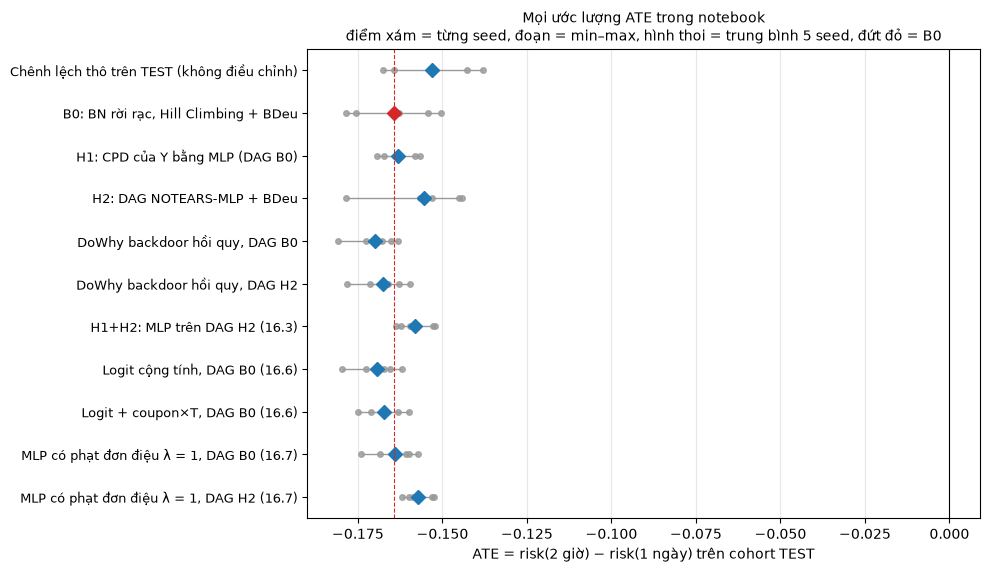

,mean,std,min,max
ước lượng,,,,
Chênh lệch thô trên TEST (không điều chỉnh),-0.1531,0.0130,-0.1676,-0.1380
"B0: BN rời rạc, Hill Climbing + BDeu",-0.1643,0.0125,-0.1785,-0.1503
H1: CPD của Y bằng MLP (DAG B0),-0.1630,0.0056,-0.1694,-0.1565
H2: DAG NOTEARS-MLP + BDeu,-0.1555,0.0139,-0.1785,-0.1443
"DoWhy backdoor hồi quy, DAG B0",-0.1699,0.0071,-0.1809,-0.1631
"DoWhy backdoor hồi quy, DAG H2",-0.1677,0.0074,-0.1783,-0.1597
H1+H2: MLP trên DAG H2 (16.3),-0.1581,0.0053,-0.1637,-0.1523
"Logit cộng tính, DAG B0 (16.6)",-0.1693,0.0069,-0.1797,-0.1619
"Logit + coupon×T, DAG B0 (16.6)",-0.1672,0.0061,-0.1750,-0.1598


In [55]:
def ate_rows() -> pd.DataFrame:
    """Gom mọi ước lượng ATE theo seed đã tính trong notebook thành một bảng (ước lượng, seed, ATE) để vẽ forest plot."""
    rows = [("Chênh lệch thô trên TEST (không điều chỉnh)", s, naive[s]) for s in CONFIG["seeds"]]
    for m, lab in (("B0", "B0: BN rời rạc, Hill Climbing + BDeu"), ("H1", "H1: CPD của Y bằng MLP (DAG B0)"), ("H2", "H2: DAG NOTEARS-MLP + BDeu")):
        rows += [(lab, r["seed"], r["ATE"]) for _, r in RUNS_DF[RUNS_DF.model == m].iterrows()]
    for g, lab in (("B0", "DoWhy backdoor hồi quy, DAG B0"), ("H2", "DoWhy backdoor hồi quy, DAG H2")):
        rows += [(lab, r["seed"], r["DoWhy ATE (lin. reg.)"]) for _, r in TABLE_B[TABLE_B.model == g].iterrows()]
    rows += [("H1+H2: MLP trên DAG H2 (16.3)", r["seed"], r["ATE"]) for _, r in AB_DF[AB_DF.ablation == "H1+H2 (MLP trên DAG H2)"].iterrows()]
    for m, lab in (("Logit cộng tính", "Logit cộng tính, DAG B0 (16.6)"), ("Logit + coupon×T", "Logit + coupon×T, DAG B0 (16.6)")):
        rows += [(lab, r["seed"], r["ATE"]) for _, r in MONO_DF[MONO_DF.model == m].iterrows()]
    for g, lab in (("B0", "MLP có phạt đơn điệu λ = 1, DAG B0 (16.7)"), ("H2", "MLP có phạt đơn điệu λ = 1, DAG H2 (16.7)")):
        rows += [(lab, r["seed"], r["ATE"]) for _, r in MONO_MLP_DF[(MONO_MLP_DF.DAG == g) & (MONO_MLP_DF["λ"] == 1)].iterrows()]
    return pd.DataFrame(rows, columns=["ước lượng", "seed", "ATE"])


ATE_ALL = ate_rows()
order = list(dict.fromkeys(ATE_ALL["ước lượng"]))
ate_sum = ATE_ALL.groupby("ước lượng", sort=False)["ATE"].agg(["mean", "std", "min", "max"]).loc[order]
ate_sum.round(4).to_csv(ART / "ate_all_estimators.csv")
fig, ax = plt.subplots(figsize=(10, 0.42 * len(order) + 1.2))
ys = np.arange(len(order))[::-1]
for y, lab in zip(ys, order):
    sub = ATE_ALL[ATE_ALL["ước lượng"] == lab]
    ax.plot(sub["ATE"], [y] * len(sub), "o", color="#999", markersize=4, alpha=0.8)
    ax.hlines(y, ate_sum.loc[lab, "min"], ate_sum.loc[lab, "max"], color="#999", linewidth=1)
    ax.plot(ate_sum.loc[lab, "mean"], y, "D", color="#d62728" if lab.startswith("B0:") else "#1f77b4", markersize=7)
ax.axvline(ate_sum.loc["B0: BN rời rạc, Hill Climbing + BDeu", "mean"], color="#d62728", linewidth=0.8, linestyle="--")
ax.axvline(0, color="k", linewidth=0.8)
ax.set_yticks(ys); ax.set_yticklabels(order, fontsize=9); ax.set_xlabel("ATE = risk(2 giờ) − risk(1 ngày) trên cohort TEST")
ax.set_title(f"Mọi ước lượng ATE trong notebook\nđiểm xám = từng seed, đoạn = min–max, hình thoi = trung bình {N_SEEDS} seed, đứt đỏ = B0", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(ART / "ate_forest.png", dpi=130, bbox_inches="tight")
plt.show()
ate_sum.round(4)

### 17.1 Trả lời câu hỏi nhân quả

**Rút hạn coupon từ 1 ngày xuống 2 giờ làm giảm xác suất chấp nhận khoảng 16 điểm phần trăm** trên cohort TEST: risk(1d) ≈ 0,65 → risk(2h) ≈ 0,49. Ba mô hình và ước lượng độc lập của DoWhy (backdoor hồi quy) cho cùng một câu trả lời:

| Ước lượng (5 seed) | ATE | Ghi chú |
|---|---|---|
| B0 (BN rời rạc, HC + BDeu) | −0,164 ± 0,013 | CI 95% bootstrap theo cụm của từng run không chứa 0 (ví dụ seed 0: [−0,190; −0,141]) |
| H1 (CPD của Y bằng MLP) | −0,163 ± 0,006 | sd qua seed thấp nhất |
| H2 (DAG NOTEARS-MLP) | −0,156 ± 0,014 | nhỏ hơn B0 khoảng 0,009, cùng dấu, CI chồng lấn |
| DoWhy backdoor linear regression (DAG B0) | −0,170 ± 0,007 | cùng tập điều chỉnh, phương pháp ước lượng khác |
| Chênh lệch thô trên TEST | −0,153 ± 0,013 | không điều chỉnh |

Chênh lệch thô và ATE điều chỉnh gần nhau là hệ quả trực tiếp của giả định G1 (T chỉ phụ thuộc biến kịch bản, mục 5.4): điều chỉnh backdoor chỉ dịch ước lượng khoảng 1 điểm phần trăm. Dịch chuyển này có nguồn gốc rõ: tỉ lệ coupon hạn 2 giờ thay đổi theo loại coupon (Bar 0,30 → Coffee House 0,56) và các loại này cũng khác nhau về tỉ lệ chấp nhận nền, nên `coupon` là confounder thật dù yếu.

**Hiệu ứng không đồng nhất theo loại coupon (CATE, mục 13.1).** Với B0: Restaurant(<20) −0,24, Restaurant(20–50) −0,25, Coffee House −0,14, Carry out −0,14, **Bar −0,04** (gần 0, sd 0,03 giữa seed). Bốn loại ngoài Bar có CI 95 % bootstrap nằm hẳn dưới 0 ở mọi seed và mọi mô hình; riêng Bar các mô hình không thống nhất (MLP có phạt đơn điệu ở mục 16.7 cũng cho Bar −0,08 như H1):

| Mô hình | CATE Bar | CI 95 % (trung bình 5 seed) | số seed CI chứa 0 |
|---|---|---|---|
| B0 | −0,04 | [−0,11; +0,02] | 4/5 |
| H2 | −0,02 | [−0,07; +0,04] | 5/5 |
| H1 | −0,07 | [−0,11; −0,03] | 0/5 |

Kết quả hợp lý về mặt hành vi: coupon nhà hàng cần người lái sắp xếp thời gian nên hạn 2 giờ là rào cản lớn; coupon bar vốn đã ít được chấp nhận nên thời hạn gần như không đổi được quyết định. Thứ tự thô (nhà hàng < cà phê, mang về < Bar) giống nhau ở cả ba mô hình; thứ tự trong từng cặp đổi chỗ tuỳ mô hình.

**Forest plot (hình trên, `ate_forest.png`).** Mười một ước lượng ATE trong notebook, kể cả các mô hình ablation, có trung bình 5 seed nằm trong dải −0,153 … −0,170 (từng seed −0,138 … −0,181) và cách xa 0 nhiều lần độ lệch giữa seed. Trong 10 ước lượng có điều chỉnh, nhỏ nhất về độ lớn là H2 (−0,156) và MLP đơn điệu trên DAG H2 (−0,157), lớn nhất là DoWhy backdoor và logit cộng tính trên DAG B0 (−0,170); khoảng cách 0,014 giữa chúng nhỏ hơn hai lần sd giữa seed của B0. Chênh lệch thô không điều chỉnh (−0,153) cũng nằm sát dải này vì T độc lập với tầng người trả lời (mục 16.2), nên điều chỉnh backdoor chỉ đổi kết quả khoảng 0,01.

**Kiểm chứng bằng bootstrap theo ô (mục 13.2).** Trong 19 ô có τ > 0 của B0 (357 dòng TEST), 18 ô có CI 95 % bootstrap chứa 0 (so với 51 % ở các ô τ ≤ 0); ô con nhỏ hơn của chúng có median 11 dòng TRAIN so với 22 ở nhóm τ ≤ 0. Ô duy nhất có CI không chứa 0 là ô mà TRAIN không có dòng T = 1 nào, nên BDeu kéo P(Y=1 | T=1) về 0,5 ở mọi lần bootstrap; CI ở đó không phản ánh độ bất định thật. Vậy các hiệu ứng dương của B0 là nhiễu lấy mẫu ở ô thưa cộng với prior của BDeu, không phải bằng chứng cho hiệu ứng ngược chiều. Qua 5 seed, tỉ lệ dòng TEST có τ > 0 là 14 % ± 4 % với B0 và 3 % ± 3 % với H1 (seed 0 là 0 %).

**CPD đơn điệu theo T (mục 16.6).** Thay BDeu bằng hồi quy logistic cộng tính trên cùng parents(Y) buộc τ ≤ 0 ở mọi ô ($\beta_T$ ≈ −0,8 ở cả 5 seed) và cho ATE −0,169 ± 0,007, nhưng log-loss xấu hơn B0 0,011 ± 0,008 và CATE của Bar bị kéo về mức chung (−0,18 thay vì −0,04). Thêm tương tác coupon × T khôi phục CATE theo coupon (Bar −0,03, Restaurant(20–50) −0,26) với log-loss xấu hơn B0 0,008 ± 0,008. Nghĩa là tri thức đơn điệu loại được nhiễu dương nhưng mô hình cộng tính bỏ sót tương tác bậc cao mà BDeu và MLP bắt được.

**MLP có phạt đơn điệu (mục 16.7).** Thêm phạt λ · ReLU(P(Y=1 | T=1, c) − P(Y=1 | T=0, c)) vào hàm mất mát của H1 đạt cả hai mục tiêu: với λ = 1, tỉ lệ dòng TEST có τ > 0 bằng 0 ở cả 5 seed, log-loss không xấu đi (−0,0005 ± 0,0011 so với H1), ATE −0,164 ± 0,007 và CATE theo coupon gần như H1 (Bar −0,08). Kết quả không nhạy với λ trong khoảng 1–100. Trên DAG H2 (so với H1+H2 ở mục 16.3) phạt cũng gần loại hết τ > 0 (0,3 % dòng), log-loss và ATE (−0,157) không đổi. Nếu cần hiệu ứng ở mức ô thì đây là mô hình nên dùng; CI bootstrap cho nó chưa được tính (mục 17.5).

### 17.2 So sánh ba mô hình

- **Dự đoán (Table A).** Ba mô hình gần như ngang nhau: AUROC 0,739 / 0,742 / 0,740, log loss 0,596 / 0,590 / 0,599 (B0 / H1 / H2). H1 tốt hơn B0 một chút và nhất quán ở 4/5 seed (Δ log loss −0,006 ± 0,009), nhưng chênh lệch nhỏ hơn độ lệch chuẩn giữa các seed, nên **không thể kết luận H1 vượt B0**. H2 không khác B0 (Δ log loss +0,003 ± 0,007). So với mốc tham chiếu không cấu trúc (mục 12.1): ba BN ngang hồi quy logistic trên 13 biến (AUROC 0,734, log loss 0,596) và thấp hơn gradient boosting (AUROC 0,753, log loss 0,582) khoảng 0,011–0,014 AUROC; nghĩa là DAG chỉ dùng 4–6 parents của Y nhưng giữ được gần hết thông tin dự đoán, phần còn thiếu là tương tác bậc cao mà boosting bắt được.
- **Can thiệp (Table B).** H1 không làm thay đổi ATE so với B0 (Δ +0,001 ± 0,010) vì chỉ thay cách ước lượng P(Y | parents) trên cùng DAG. H2 cho ATE nhỏ hơn khoảng 0,009 vì DAG của nó chọn tập parents(Y) khác (thường có `weather`, bỏ `direction_same`, `time_bin`).
- **Cấu trúc (mục 11.1).** Hai thuật toán ổn định ngang nhau qua seed: Jaccard trung bình 0,77 (B0) và 0,77 (H2); 28/52 cạnh của B0 và 24/44 cạnh của H2 xuất hiện ở cả 5 seed. Cả hai **đều tự tìm ra cạnh T → Y** ở mọi seed và đều đồng ý parents(Y) ⊇ {T, coupon, destination, habit_match}; H2 thêm `weather`, B0 thêm `direction_same`/`time_bin`. H2 thưa hơn (32–36 cạnh so với 36–43) nhưng với hệ số phạt vào T chọn trên VALIDATION (×0,1 ở 4 seed, ×0,3 ở seed 1) nó giữ **đủ 7 biến kịch bản làm parents của T** ở mọi seed, nhiều hơn B0 (4–6 parents); DoWhy chọn tập backdoor nhỏ nhất {coupon, destination, habit_match} (+ `direction_same`, `time_bin` tuỳ seed) trên DAG B0 và {coupon, destination, weather} (seed 3: {coupon, destination}) trên DAG H2; cả hai đều thoả tiêu chí backdoor khi kiểm tra lại bằng d-separation (mục 8.3, 13). SHD giữa hai DAG vẫn lớn (34–45) vì chúng khác nhau ở các cạnh trong tầng người và trong tầng kịch bản, là phần không ảnh hưởng đến câu hỏi nhân quả.
- **Chi phí (Table C).** B0 fit ≈ 10–15 s (chủ yếu là duyệt 13 ứng viên cấu trúc: 12 Hill Climbing + PC), H2 ≈ 20–40 s tuỳ tải máy (3 lần NOTEARS), H1 ≈ 0,5 s nhưng bootstrap của H1 chậm gấp 15–20 lần B0 (huấn luyện lại MLP 200 lần); số giây tuyệt đối thay đổi theo lần chạy, chỉ thứ tự tương đối là ổn định.

**Kết luận chọn mô hình:** B0 là mô hình nên trình bày chính vì đơn giản, ổn định, giải thích được (CPD đọc trực tiếp) và trùng với ước lượng độc lập của DoWhy; H1 là cải tiến nhỏ về dự đoán, không đổi về nhân quả; H2 là kiểm chứng độc lập rằng cấu trúc then chốt (T → Y, parents(Y), parents(T) ⊆ tầng kịch bản) không phụ thuộc thuật toán học DAG. Nếu cần hiệu ứng ở mức ô thay vì ATE thì dùng H1 có phạt đơn điệu λ = 1 (mục 16.7): giữ log-loss của H1 và đảm bảo τ ≤ 0 ở mọi ô.

### 17.3 Kiểm tra robustness và ablation

- **Tiêu chí backdoor (mục 8.3, 13):** tập điều chỉnh DoWhy chọn, parents(T) và $C_\text{full}$ đều không chứa hậu duệ của T và d-tách T khỏi Y trong đồ thị đã cắt cạnh ra khỏi T, ở cả 5 seed và 2 DAG (`backdoor_check.csv`); tập rỗng không đạt vì đường backdoor qua `coupon`. Vì vậy do-query chuẩn hoá theo $C_\text{full}$ (mục 7.3) và ước lượng backdoor của DoWhy nhắm cùng một estimand.
- **Refuter của DoWhy (mục 14.2):** placebo (hoán vị T) cho hiệu ứng ≈ 0 (|mean| ≤ 0,002, p ≈ 0,8–1,0); subset 80% giữ nguyên ATE (p ≈ 0,9–1,0) ở cả 10 cặp (DAG, seed).
- **Refuter cài riêng cho BN (mục 14.3):** placebo mean 0,000 / −0,001 / 0,000, subset mean −0,165 / −0,163 / −0,155 (B0 / H1 / H2), đúng như kỳ vọng.
- **A2 (nới mask người → T khi học NOTEARS, mục 16.2):** thuật toán **không thêm bất kỳ cạnh người → T nào** (trọng số lớn nhất 0,04–0,12, dưới ngưỡng cắt), DAG giống hệt H2 (SHD 0 ở cả 5 seed), nên ATE giữ nguyên đến 4 chữ số. Dữ liệu tự xác nhận giả định G1 ngay cả khi không bị ép.
- **Kiểm tra ngoài (mục 16.1):** Hill Climbing *không* có ràng buộc tầng tạo ra 1–2 cạnh người ↔ T và 10–14 cạnh ngược thứ tự thời gian mỗi seed (ví dụ `weather → habit_match`, `passenger → has_children`). Ràng buộc miền ở mục 6 là cần thiết để DAG có nghĩa nhân quả; thuật toán học cấu trúc chỉ tìm được phụ thuộc thống kê.
- **A5 (chọn ngưỡng H2 theo log-likelihood toàn mạng, mục 16.4):** ở 4 seed tiêu chí này chọn ngưỡng thấp hơn (0,05 hoặc 0,10), thêm 4–11 cạnh và làm log-loss của Y xấu đi (+0,028 ± 0,017) trong khi ATE trung bình chỉ đổi 0,001 (từng seed tới 0,009). Log-likelihood toàn mạng thưởng cho các cạnh giữa biến nền không giúp dự đoán Y, nên tiêu chí log-loss của Y là lựa chọn đúng cho câu hỏi này.
- **Lưới hệ số phạt L1 cho cạnh vào T (mục 16.5):** ba kết quả. (a) Với phạt đồng đều (×1) NOTEARS xoá hết cạnh vào T ở 3/5 seed (seed 2, 3, 4) vì T chỉ phụ thuộc yếu vào kịch bản nên cải thiện cross-entropy của T quá nhỏ so với phạt; ×0,3 và ×0,1 giữ 6–7 parents kịch bản của T ở mọi seed. (b) Trong cùng một seed, cả ba hệ số cho **cùng parents(Y), cùng log-loss và cùng ATE đến 4 chữ số**, đúng như lập luận ở mục 7.3 (do-query chuẩn hoá không dùng CPD của T), nên tiêu chí chính không phân biệt được chúng. (c) Tiêu chí phụ (log-loss của T trên VALIDATION) chọn ×0,1 ở 4 seed; ở seed 1 hai hệ số ×0,1 và ×0,3 hoà cả hai tiêu chí nên log-likelihood toàn mạng chọn ×0,3.
- **Tái lập:** chạy lại toàn bộ notebook trong môi trường sạch (venv mới, cài từ `requirements.txt`, tải lại dữ liệu UCI) cho split, 10 DAG học được, Table A/B, CI bootstrap và mọi ước lượng ATE trên forest plot giống hệt bản nộp; mọi nguồn ngẫu nhiên (random, numpy, torch, DoWhy) đều được seed.
- **CPD đơn điệu theo T (mục 16.6):** hồi quy logistic cộng tính / có tương tác coupon × T trên cùng parents(Y) của B0 cho ATE −0,169 / −0,167, τ ≤ 0 ở 100 % dòng TEST, log-loss xấu hơn B0 0,011 / 0,008; chỉ biến thể có tương tác giữ được CATE của Bar ≈ 0. ATE không nhạy với cách học tham số của Y, còn hiệu ứng theo ô thì có.
- **H1 có phạt đơn điệu (mục 16.7):** λ ∈ {1, 10, 100} đều cho τ ≤ 0 ở 100 % dòng TEST của cả 5 seed, log-loss bằng H1 (Δ −0,0005 … −0,0001), ATE −0,164 … −0,166; trên DAG H2 cũng vậy (ATE −0,157, còn 0,3 % dòng τ > 0). Ràng buộc miền "hạn ngắn không làm tăng ý định" tương thích với dữ liệu nên không tốn gì về dự đoán.
- **A1 (H1 bỏ dropout):** dự đoán không đổi (Δ AUROC +0,001, Δ log loss 0,000) nhưng ATE âm hơn 0,007 ± 0,003 (−0,170 so với −0,163), mức dịch lớn nhất trong các ablation: dropout làm trơn CPD của Y ở ô thưa. **A3 (B0 dùng MLE thay BDeu):** 0–8 ô CPD có xác suất đúng 0 hoặc 1, log loss xấu đi 0,004 ± 0,004, ATE không đổi. **A4 (B0 với ESS = 1 hoặc 20 thay 5):** Δ log loss ≤ 0,001, Δ ATE ≤ 0,0003. Bước học tham số gần như không ảnh hưởng kết quả với 8 400 dòng TRAIN; làm trơn chỉ có tác dụng ở ô thưa. **H1+H2 (MLP trên DAG H2):** log loss −0,009 ± 0,009 so với H2, cùng cỡ với H1 so với B0.

### 17.4 Hạn chế

1. **Giả định G2 (không có confounder ẩn, mục 2) không kiểm chứng được:** phiên bản bảng hỏi gán T không có trong dữ liệu. Nếu phiên bản bảng hỏi còn liên hệ với một yếu tố ảnh hưởng Y ngoài 7 biến kịch bản thì ATE bị chệch; thiết kế của Wang et al. (2017) và ablation A2 (mục 16.2) làm giả định này hợp lý nhưng không chứng minh được.
2. **Y là ý định khai báo (G5):** kết quả nói về phản ứng với kịch bản giả định, không phải hành vi mua thật; hiệu ứng thật có thể nhỏ hơn.
3. **Dữ liệu cụm:** chỉ 580 người trả lời; CI bootstrap theo cụm rộng hơn CI của DoWhy (nửa khoảng ≈ 0,023 cho B0 trung bình 5 seed so với ≈ 0,020 của DoWhy trên DAG B0) vì DoWhy coi ≈ 8 400 dòng TRAIN là độc lập, nên CI của DoWhy hẹp hơn mức đúng. CATE của Bar dựa trên ô có ít dữ liệu nhất và dao động mạnh nhất giữa các seed.
4. **H2:** với phạt L1 đồng đều NOTEARS xoá cơ chế của T ở 3/5 seed (mục 16.5); notebook khắc phục bằng lưới hệ số phạt chọn trên VALIDATION, nhưng tiêu chí chính (log-loss của Y) không phân biệt các hệ số, chỉ tiêu chí phụ (log-loss của T) quyết định; nghĩa là cơ chế của T được chọn theo khả năng dự đoán T chứ không theo một tiêu chí nhân quả. Khi dùng NOTEARS cho câu hỏi nhân quả, cần kiểm tra cơ chế của treatment có được giữ hay không, vì tập backdoor DoWhy báo cáo phụ thuộc vào nó.
5. **Rời rạc hoá:** `age`, `income`, `time` được gộp thành 3–4 mức để tránh ô thưa; mức gộp khác có thể cho CPD khác, nhưng ATE ít nhạy vì các biến này không phải confounder của T.
6. Ước lượng tham chiếu của DoWhy dùng hồi quy tuyến tính cho Y nhị phân (risk difference); đây là mô hình làm việc, không phải mô hình xác suất đúng, nên chỉ dùng để đối chiếu.

### 17.5 Hướng cải tiến tiếp theo

- Mô hình MLP có phạt đơn điệu (mục 16.7) mới có ước lượng điểm; bước tiếp theo là bootstrap theo cụm cho ATE, CATE và cho τ theo từng ô của nó, để so với CI của B0 ở mục 13.2.
- Thay MLP cho riêng Y bằng một mô hình cơ chế cho mọi nút (ví dụ `dowhy.gcm`) để trả lời các truy vấn phản thực (counterfactual) cho từng người, điều mà BN rời rạc không làm được.
- Thêm các biến người còn lại của dữ liệu gốc (`education`, `maritalStatus`, `occupation` với 25 nghề) vào tầng người trả lời để kiểm tra chúng có vào CPD của Y khi đủ dữ liệu không; theo giả định G1 chúng không phải confounder của T nên ATE dự kiến không đổi.
- Thu hẹp CI cho CATE của Bar bằng cách gộp thêm dữ liệu Bar × Work nếu có nguồn khác có overlap.

### 17.6 AI disclosure

Mã nguồn, văn bản giải thích và bố cục của notebook này được xây dựng với sự hỗ trợ của trợ lý AI (Claude, Anthropic) theo yêu cầu và chỉnh sửa của tác giả. Mọi số liệu trong notebook là **kết quả thực thi thật** của mã trên dữ liệu UCI In-Vehicle Coupon (sha256 kiểm tra ở mục 4.1), không có số nào được nhập tay; `artifacts/coupon_results/` chứa toàn bộ output để đối chiếu. Thuật toán NOTEARS-MLP cho biến phân loại được cài đặt lại từ bài báo Zheng et al. (2020), không sao chép mã gốc. Tác giả chịu trách nhiệm về các lựa chọn mô hình, giả định và kết luận.

**Tài liệu tham khảo.**
- Wang, T., Rudin, C., Doshi-Velez, F., Liu, Y., Klampfl, E., MacNeille, P. (2017). *A Bayesian framework for learning rule sets for interpretable classification.* JMLR 18. (nguồn dữ liệu UCI 603)
- Pearl, J. (2009). *Causality*, 2nd ed. Cambridge University Press. (do-calculus, backdoor, truncated factorization)
- Zheng, X., Dan, C., Aragam, B., Ravikumar, P., Xing, E. (2020). *Learning sparse nonparametric DAGs.* AISTATS. (NOTEARS-MLP)
- Heckerman, D., Geiger, D., Chickering, D. (1995). *Learning Bayesian networks: the combination of knowledge and statistical data.* Machine Learning 20. (BDeu)
- Sharma, A., Kiciman, E. (2020). *DoWhy: an end-to-end library for causal inference.* arXiv:2011.04216.
- Ankan, A., Textor, J. (2024). *pgmpy: a Python toolkit for Bayesian networks.* JMLR 25.